# Run all stages with saved models

Select the configured `student-dropout` Python 3.12 kernel, start with a working directory inside this cloned repository, and run the cells in order (or choose **Run All**). See the [setup instructions](../README.md) for dependencies.

All stages share the active IPython namespace. Each stage's Markdown is displayed and its code cells run in their original order. Keep the source notebooks' training, rebuild, search and stability-retraining controls **False**, and Drive mode disabled. This runner does not override those controls.

Markdown and normal outputs, including plots, appear beneath each launcher cell here; the Stage 1/2/3 source notebooks' saved outputs are not updated. **Restart the kernel before a complete rerun.**


In [1]:
import os
from pathlib import Path

_runner_start = Path.cwd().resolve()
for _runner_root in (_runner_start, *_runner_start.parents):
    if all((_runner_root / name).is_dir() for name in ('src', 'data', 'notebooks')):
        os.chdir(_runner_root / 'notebooks')
        break
else:
    raise FileNotFoundError('Start the kernel with its working directory inside the cloned repository.')

import nbformat
from IPython.display import Markdown, display


def _run_stage(filename):
    path = Path(filename).resolve()
    notebook = nbformat.read(path, as_version=4)
    shell = get_ipython()
    if shell is None:
        raise RuntimeError('Run this notebook in an IPython kernel.')
    for number, cell in enumerate(notebook.cells, start=1):
        try:
            if cell.cell_type == 'markdown':
                display(Markdown(cell.source))
            elif cell.cell_type == 'code':
                shell.run_cell(cell.source, store_history=False).raise_error()
        except BaseException as error:
            raise RuntimeError(
                f'{path.name}: source cell {number} ({cell.get("id", "no id")}) failed'
            ) from error


/home/alexd/miniforge3/envs/student-dropout/lib/python3.12/site-packages/nbformat/validator.py:434: MissingIDFieldWarning: Cell is missing an id field, this will become a hard error in future nbformat versions. You may want to use `normalize()` on your notebooks before validations (available since nbformat 5.1.4). Previous versions of nbformat are fixing this issue transparently, and will stop doing so in the future.
  _validate(nbdict, ref, version, version_minor, relax_add_props)


# Student Dropout Prediction - Stage 1


## Colab / Local Setup

Local execution still works from the cloned repo in VS Code / WSL.

In Google Colab, start each new runtime by cloning the repo, optionally enabling Google Drive-backed artifacts, and then running the setup cell below.

```bash
!git clone <repo-url> /content/student-dropout-prediction
%cd /content/student-dropout-prediction
!pip install -r requirements.txt
```

Set `USE_GOOGLE_DRIVE_ARTIFACTS = True` in the setup cell if you want models, tuning outputs, reports, and demo artifacts to persist across Colab sessions.


I0000 00:00:1792077268.115771  214481 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


Running in Colab: False
Artifact mode: local_repo
Project root: /home/alexd/projects/student-dropout-prediction/student-dropout-prediction
Working directory: /home/alexd/projects/student-dropout-prediction/student-dropout-prediction/notebooks


I0000 00:00:1792077268.177638  214481 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX_VNNI AVX_VNNI_INT8 AVX_NE_CONVERT FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
I0000 00:00:1792077269.302043  214481 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
/home/alexd/miniforge3/envs/student-dropout/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


# Stage 1 data

## Business Background

This dataset is Stage 1 of a three-stage student progression modelling framework.

Stage 1 contains applicant and course-level information that is known at the point of application or admission, prior to programme commencement. 

The objective of this stage is to develop a predictive model that estimates the risk of student drop-out using only intake-available features.

A structured, data-centric approach to feature engineering and selection will be applied to ensure:

- Removal of redundant or high-cardinality noise features
- Appropriate handling of missing values
- Controlled encoding of categorical variables
- Avoidance of temporal leakage


A model with optimised performance metrics that are aligned to minimising the risk of missed opportunities for early intervention measures will help to improve student retention and performance. For example using measures that minimise the risk of false negatives (i.e., failing to identify at-risk students), rather than relying on overall accuracy alone.

An optimised and well-generalised Stage 1 model can support proactive engagement strategies, enabling efficient implementation of intervention measures to improve overall student retention outcomes.

## Data loading

Loaded Stage 1 public dataset from /home/alexd/projects/student-dropout-prediction/student-dropout-prediction/data/processed/Stage_1_public.csv; cache writes disabled.


,CentreName,LearnerCode,BookingType,LeadSource,DiscountType,Gender,Age,Nationality,CourseLevel,academic_stage,subject_cluster,delivery_variant,IsFirstIntake,CompletedCourse,dropout,progression_degree_level,ProgressionUniversity
0,UK_SCOT_02,5471702600,Agent,Standard Agent Booking,NaN,Male,27,Chinese,Pre-Masters,Pre Masters,Business_Law_Combined,standard,True,Yes,0,MSc,UK_SCOT_02
1,UK_SCOT_02,5798287286,Agent,Standard Agent Booking,NaN,Male,27,Chinese,Foundation,UG Foundation Programme,Science_Health,standard,False,Yes,0,BSc,UK_SCOT_02
2,UK_SCOT_02,5073159875,Agent,Standard Agent Booking,NaN,Male,25,Chinese,International Year Two,International Year Two,Business_Economics_Finance,standard,False,Yes,0,MA,UK_SCOT_02
3,UK_SCOT_02,9006902202,Agent,Standard Agent Booking,NaN,Male,26,Chinese,International Year Two,International Year Two,Business_Economics_Finance,standard,True,Yes,0,MA,UK_SCOT_02
4,UK_SCOT_02,1792089712,Agent,Standard Agent Booking,NaN,Male,29,Chinese,Pre-Masters,Pre Masters,Business_Law_Combined,standard,True,Yes,0,MSc,UK_SCOT_02


## Data Inspection

First we'll review the data and perform any data cleanse or pre-processing.

### Data Quality Checks

We will perform basic data quality checks, view the dataframe metadata to determine assigned datatypes, and determine the size of the dataset.

Data quality checks:

- Duplicated rows
- Missing data checks
- Trailing / Leading whitespace
- Count of unique values
- Duplicated value analysis

<class 'pandas.DataFrame'>
RangeIndex: 25059 entries, 0 to 25058
Data columns (total 17 columns):
 #   Column                    Non-Null Count  Dtype
---  ------                    --------------  -----
 0   CentreName                25059 non-null  str  
 1   LearnerCode               25059 non-null  int64
 2   BookingType               25059 non-null  str  
 3   LeadSource                25059 non-null  str  
 4   DiscountType              7595 non-null   str  
 5   Gender                    25059 non-null  str  
 6   Age                       25059 non-null  int64
 7   Nationality               25059 non-null  str  
 8   CourseLevel               25059 non-null  str  
 9   academic_stage            25059 non-null  str  
 10  subject_cluster           25059 non-null  str  
 11  delivery_variant          25059 non-null  str  
 12  IsFirstIntake             25059 non-null  bool 
 13  CompletedCourse           25059 non-null  str  
 14  dropout                   25059 non-null  int64
 

**Interpretation**

***Data Summary***

- 25059 records
- 0 duplicated rows
- 1 x numeric (identifier)
    - LearnerCode
- 1 x boolean
    - IsFirstIntake
- Date values stored in text:
    - DateofBirth
- Boolean indicator stored in text:
    CompletedCourse (Yes / No)


***There are null values in the fields:***

- DiscountType (highly sparse) 
- HomeState (missing in 64% of records)
- HomeCity (missing in 14% of records)

- ProgressionDegree (missing in 3.5% of records)
    - High level of cardinality 
    - If retained transformation may be required after further investigation e.g.
        - Grouping
        - Target encoding
        - Addressing missing values after transformation
    - Note the degree level appears to be the first unbroken characters in the field
        - Extract this for further analysis.

***Leading / trailing space***

- HomeCity - trim the three affected fields


***Duplicated identifier fields (initially flagged for investigation)***

- LearnerCode is "almost unique"
    - 24,877 distinct values
    - 182 repeated (0.73%)

This suggests repeat enrolments or data quality issue.


Overall, the dataset exhibits expected cardinality patterns and repetition levels, with one area flagged for further investigation (Repeated LearnerCode). We see high repetition in CentreName, CourseLevel, BookingType which is consistent with low-cardinality categorical variables, low repetition in LearnerCode (this is a near-unique identifier), and moderate repetition in ProgressionDegree (long-tail categorical).



**Provisional Data cleanse actions**

1. **Identifier reuse analysis**
   - Inspect the 182 duplicated learner code rows
   - Either retain (if other values indicate a different course) or drop.
   - Consider adding a new feature (is_repeat_learner)

2. **Convert date values**
   - Convert validated date field to datetime types
   - Add age column and compute age from DateofBirth relative to a fixed reference date.
   - Drop original DateofBirth column

3. **Remove Whitespace**
    - Remove whitespace from the three affected HomeCity field values

4. **Convert Numeric Stored as String to Numeric**
    - Complete conversion - values are counts so convert to INT
    - Check for any conversion failures

5. **Create and Encode Target Variable** 
    - CompletedCourse is one of two values:
        - 'Yes' - Course completed
        - 'No' - Course not completed - indicating drop-out
    - We will binary encode CompletedCourse:
        - 'Yes' = 1
        - 'No' = 0
    - Create a new column 'dropout' which is the inverse of CompletedCourse
        - This is aligned with the modelling objective described in the brief; to predict whether a student will drop out.

6. **Extract Degree Level from ProgressionDegree** 
    - Create column progression_degree_level
    - Map the 1st unbroken string to this value
    - Further refine groupings if needed 

Note: We will decide on imputation strategy after initial data cleanse and completion of EDA.


Data quality check (6) inspect rows with repeated LearnerCode values:



,CentreName,LearnerCode,BookingType,LeadSource,DiscountType,Gender,Age,Nationality,CourseLevel,academic_stage,subject_cluster,delivery_variant,IsFirstIntake,CompletedCourse,dropout,progression_degree_level,ProgressionUniversity
20946,UK_SCOT_01,66117986,Agent,Sponsor,NaN,Male,24,Saudi,Foundation,UG Foundation Programme,Engineering,standard,False,Yes,0,BEng,UK_SCOT_01
17956,UK_NE_04,66117986,Agent,Sponsor,NaN,Male,24,Saudi,Foundation,International Foundation Year,Engineering,standard,False,Yes,0,BEng,UK_NE_05
17107,UK_NE_04,92376119,Agent,Standard Agent Booking,Bursary,Male,28,Chinese,Pre-Masters,Pre Masters,Business_Humanities_Combined,standard,False,Yes,0,MSc,UK_NE_05
9759,UK_NW_01,92376119,Agent,Standard Agent Booking,NaN,Male,28,Chinese,Pre-Masters,Pre Masters,Engineering_Computer_Combined,standard,False,No,1,MSc,UK_NW_01
5187,UK_NE_05,182573716,Agent,Standard Agent Booking,Bursary,Male,24,Egyptian,International Year One,International Year One,Business_Management_Combined,accountancy_chartered,False,Yes,0,UNKNOWN,UK_NE_01
8828,OTHER_01,182573716,Agent,Standard Agent Booking,Bursary,Male,24,Egyptian,International Year One,International Year One,Business,accountancy_chartered,False,Yes,0,BSc,UK_NW_02
6708,UK_SE_02,209300577,Agent,Standard Agent Booking,Bursary,Male,27,Bangladeshi,Foundation,International Foundation Year,Business_Economics_Finance,standard,False,Yes,0,BSc,UK_SE_02
13081,UK_LON_01,209300577,Agent,Standard Agent Booking,Bursary,Male,27,Bangladeshi,International Year One,International Year One,Business_Economics_Finance,standard,False,No,1,BA,UK_LON_01
13084,UK_LON_01,233851063,Agent,Standard Agent Booking,Bursary,Female,27,Pakistani,International Year One,International Year One,Business_Economics_Finance,standard,False,Yes,0,BA,UK_LON_01
12667,UK_NE_01,233851063,Agent,Standard Agent Booking,Other Scholarships / Bursaries,Female,27,Pakistani,International Year One,International Year One,Business_Management_Combined,standard,False,Yes,0,BA,UK_NE_07


**LearnerCode Investigation**

The repeated LearnerCode values represent real data for learner readmissions - often moving from a Foundation course to an International Year One. As we do not have course start dates we cannot use this aspect of our dataset to generate new useful features (e.g. is_repeat_learner, previously_completed_courses).

The column is an identifier therefore in this case the most appropriate course of action is to keep all rows and drop LearnerCode from our feature set.

This investigation resolves the initially flagged concern regarding LearnerCode reuse.

**Confirmed Initial Data Cleanse Action**

Data cleanse actions required before further analytics.


1. **Remove Identifier**
   - Drop LearnerCode

2. **Convert date values**
   - Convert validated date field to datetime types
   - Add age column and compute age from DateofBirth relative to a fixed reference date.
   - Drop original DateofBirth column

3. **Remove Whitespace**
    - Remove whitespace from the three affected HomeCity field values

4. **Convert Numeric Stored as String to Numeric**
    - Complete conversion - values are counts so convert to INT
    - Check for any conversion failures

5. **Create and Encode Target Variable** 
    - CompletedCourse is one of two values:
        - 'Yes' - Course completed
        - 'No' - Course not completed - indicating drop-out
    - We will binary encode CompletedCourse:
        - 'Yes' = 1
        - 'No' = 0
    - Create a new column 'drop_out' which is the inverse of CompletedCourse
        - This is aligned with the modelling objective described in the brief; to predict whether a student will drop out.

6. **Extract Degree Level from ProgressionDegree** 
    - Create column progression_degree_level
    - Map the 1st unbroken string to this value
    - Further refine groupings if needed 



Missing progression degree values were explicitly encoded as UNKNOWN to preserve missing values as a potential signal. Following the exclusion of non-degree values, the progression_degree_level feature shows a long tail of low-frequency degree awards (e.g. LLB = 1).

To balance feature granularity and sparsity, we will group low-frequency degree awards into family-specific categories (other_bachelors, other_masters). We'll keep well-supported degree types as distinct categories.

,CentreName,BookingType,LeadSource,DiscountType,Gender,Age,Nationality,CourseLevel,academic_stage,subject_cluster,delivery_variant,IsFirstIntake,CompletedCourse,dropout,progression_degree_level,ProgressionUniversity
0,UK_SCOT_02,Agent,Standard Agent Booking,NaN,Male,27,Chinese,Pre-Masters,Pre Masters,Business_Law_Combined,standard,True,Yes,0,MSc,UK_SCOT_02
1,UK_SCOT_02,Agent,Standard Agent Booking,NaN,Male,27,Chinese,Foundation,UG Foundation Programme,Science_Health,standard,False,Yes,0,BSc,UK_SCOT_02
2,UK_SCOT_02,Agent,Standard Agent Booking,NaN,Male,25,Chinese,International Year Two,International Year Two,Business_Economics_Finance,standard,False,Yes,0,MA,UK_SCOT_02
3,UK_SCOT_02,Agent,Standard Agent Booking,NaN,Male,26,Chinese,International Year Two,International Year Two,Business_Economics_Finance,standard,True,Yes,0,MA,UK_SCOT_02
4,UK_SCOT_02,Agent,Standard Agent Booking,NaN,Male,29,Chinese,Pre-Masters,Pre Masters,Business_Law_Combined,standard,True,Yes,0,MSc,UK_SCOT_02


### Missing Data Analysis

We will now investigate columns with missing data:

- Quantify missingness per column
- Examine row-level missingness
- Evaluate missingness vs target signal

DiscountType
          count  dropout_rate
category                     
NULL      17464      0.106562
PRESENT    7595      0.249243

progression_degree_level
          count  dropout_rate
category                     
PRESENT   24184      0.134965
UNKNOWN     875      0.560000



### Feature Screening

The following features will be dropped:

**HomeState & HomeCity**

- High Cardinality (HomeState & HomeCity)
- High percentage of missing values (HomeState -> 64.38%) 
- Missing vs present shows limited signal when compared with the target
- Hard to encode meaningfully

The following feature will be added:

**DiscountType**

| Category | DropOut    |
| -------- | ---------- |
| NULL     | 10.6%      |
| PRESENT  | 24.9%      |

The dropout-rate difference suggests the absence carries information rather than random missingness. For example no value may indicate that the learner in question paid full un-discounted price for the course.

The variable will be retained and a decision made on encoding strategy (e.g. replace with None or NoDiscount) following EDA.


**Nationality**

- High Cardinality


**progression_degree_missing**

Progression degree not being present has a meaningful correlation with the dropout rate.

The missingness signal will be retained in a new progression_degree_missing (bool)

- Value = true when Progression Degree = null
- Otherwise value = false

***Assumption***

The intended progression degree pathway is declared at or prior to enrolment and is therefore known at intake. This value is valid for the Stage 1 model features.

Note: Verified that ProgressionDegree values remain unchanged across the Stage 1–3 datasets; the field is treated as intake-available and time-invariant.


**High Cardinality Data Analysis**

Next we'll investigate remaining columns with high cardinality



,count,dropout_rate
Nationality,,
Chinese,9042,0.041141
Indian,2072,0.490347
Bangladeshi,2007,0.647733
Pakistani,1973,0.284845
Hong Kong Chinese,1278,0.019562
Kuwaiti,893,0.080627
Saudi,762,0.060367
Egyptian,640,0.029687
Emirati,415,0.033735


**High Cardinality Fields Interpretation**

**CourseName**

The field contains structured components that typically encode:

- Academic Stage (e.g. INTERNATIONAL YEAR ONE)
- Subject (e.g ACCOUNTING AND FINANCE)
- Delivery Variant (e.g. ACCELERATED)

We can significantly reduce cardinality by extracting these values form the field and grouping, which will prevents sparsity introduced by one-hot encoding raw CourseName


**Nationality**

This feature can be grouped geographically to reduce cardinality. The most obvious option is by continent, however this is not recommended as doing so would merge materially different course completion behaviours into a single category, reducing predictive power and signal.

If we collapsed the following to asia:

| Nationality       | Count |   Dropout |
| ----------------- | ----: | --------: |
| Chinese           | 9,042 |  **4.1%** |
| Indian            | 2,072 | **49.1%** |
| Bangladeshi       | 2,007 | **64.8%** |
| Pakistani         | 1,973 | **28.5%** |
| Hong Kong Chinese | 1,278 |  **2.0%** |
| Kuwaiti           |   893 |  **8.1%** |
| Saudi             |   762 |  **6.1%** |


The following would be mixed:

Chinese (4%)
Indian (49%)
Bangladeshi (65%)
Pakistani (28%)

This is undesirable since it collapses strong predictive signal.

However, to reduce dimensionality we can justify grouping as follows:

- Retain countries with >= 30 entries

- Group rare nationalities to:

    - Asia_Other
    - Europe_Other
    - Africa_Other
    - Americas_Other
    - Middle_East_Other (optional)
    - Oceania_Other

Countries with ≥ 30 entries are retained individually, while lower-frequency nationalities are grouped regionally to prevent sparse categories.



,count
Nationality,
Chinese,9042
Indian,2072
Bangladeshi,2007
Pakistani,1973
Hong Kong Chinese,1278
Kuwaiti,893
Saudi,762
Egyptian,640
Emirati,415


                          count
progression_degree_level       
BSc                        8130
BA                         6015
MSc                        4646
BEng                       2037
MA                          931
UNKNOWN                     875
LLB                         788
Other                       707
MPHARM                      249
MEng                        208
other_bachelors             129
other_masters               104
BBA                          81
LLM                          71
MBA                          58
MPLAN                        30


,CentreName,BookingType,LeadSource,DiscountType,Gender,Age,Nationality,CourseLevel,academic_stage,subject_cluster,delivery_variant,IsFirstIntake,CompletedCourse,dropout,progression_degree_level,ProgressionUniversity,progression_degree_missing
0,UK_SCOT_02,Agent,Standard Agent Booking,NaN,Male,27,Chinese,Pre-Masters,Pre Masters,Business_Law_Combined,standard,True,Yes,0,MSc,UK_SCOT_02,False
1,UK_SCOT_02,Agent,Standard Agent Booking,NaN,Male,27,Chinese,Foundation,UG Foundation Programme,Science_Health,standard,False,Yes,0,BSc,UK_SCOT_02,False
2,UK_SCOT_02,Agent,Standard Agent Booking,NaN,Male,25,Chinese,International Year Two,International Year Two,Business_Economics_Finance,standard,False,Yes,0,MA,UK_SCOT_02,False
3,UK_SCOT_02,Agent,Standard Agent Booking,NaN,Male,26,Chinese,International Year Two,International Year Two,Business_Economics_Finance,standard,True,Yes,0,MA,UK_SCOT_02,False
4,UK_SCOT_02,Agent,Standard Agent Booking,NaN,Male,29,Chinese,Pre-Masters,Pre Masters,Business_Law_Combined,standard,True,Yes,0,MSc,UK_SCOT_02,False



### Exploratory Data Analysis

Generate descriptive statistics and visualise the data to explore patterns, distributions, and trends in the data.

**Descriptive Statistics**

We will now generate descriptive statistics (including percentile values for all numeric columns in the dataset), and document any insights this provides about the data.



,count,unique,top,freq,mean,std,min,5%,25%,50%,75%,95%,max
Age,25059.0,0.0,0.0,0.0,25.02554,3.166425,19.0,21.0,23.0,24.0,27.0,30.0,63.0
BookingType,25059,2,Agent,21878,0,0,0,0,0,0,0,0,0
CentreName,25059,19,UK_NE_04,5877,0,0,0,0,0,0,0,0,0
CompletedCourse,25059,2,Yes,21305,0,0,0,0,0,0,0,0,0
CourseLevel,25059,4,Foundation,14666,0,0,0,0,0,0,0,0,0
DiscountType,7595,11,Bursary,3561,0,0,0,0,0,0,0,0,0
Gender,25059,2,Male,15655,0,0,0,0,0,0,0,0,0
IsFirstIntake,25059,2,False,22035,0,0,0,0,0,0,0,0,0
LeadSource,25059,7,Standard Agent Booking,20284,0,0,0,0,0,0,0,0,0
Nationality,25059,58,Chinese,9042,0,0,0,0,0,0,0,0,0


,count,mean,std,min,25%,50%,75%,max
dropout,,,,,,,,
0,21305.0,24.992678,3.256027,19.0,23.0,24.0,27.0,63.0
1,3754.0,25.212040,2.592556,20.0,23.0,25.0,27.0,47.0



**EDA Interpretation (non-categorical)**


**Target Variable – dropout**

- The dropout rate is 15.0%, indicating a moderately imbalanced target variable.
- Most students complete their course, with 85% classified as completions.

**Age**

- The mean age is 25.2 years with a standard deviation of 3.18, indicating a relatively tight distribution.
- Most students fall within the 23–27 year interquartile range
- The minimum age is 20, while the maximum age (63) represents a small number of mature students.

Overall, age appears reasonably well-behaved with moderate right skew.


**Data Visualisation**

1. **Numerical Fields**

Visualise the numeric data with box-plots and histograms to further understand the data patterns, distributions, and trends.

2. **Categorical Fields**

We will plot the mean target value by each categorical variable (grouped by the value)


3. **Missing data vs signal**

For fields missing data, plot the null / non-null vs dropout to gain insight into the meaning of the missing value


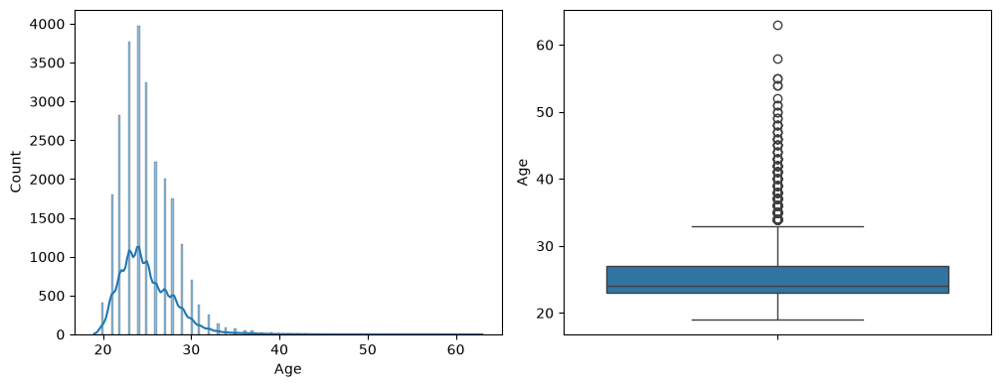

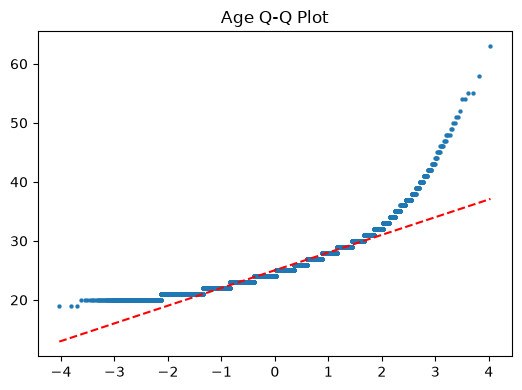

### Target Variable Analysis

**Target Bar Plot**

We will plot overall target distribution to determine the balance.

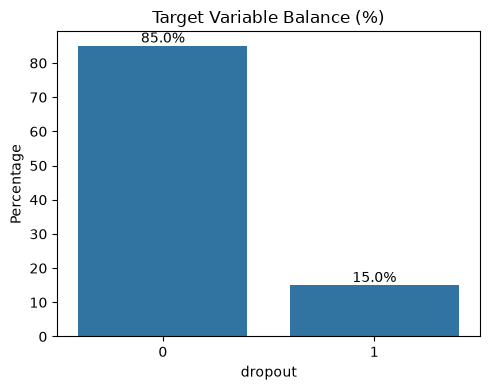

**Class Imbalance Check**

Confirmed: 

- 85% complete
- 15% dropout

This is imbalanced, and should be considered when creating test / train / validation - use stratified split

When evaluating model performance consider imbalance when assessing accuracy measures.


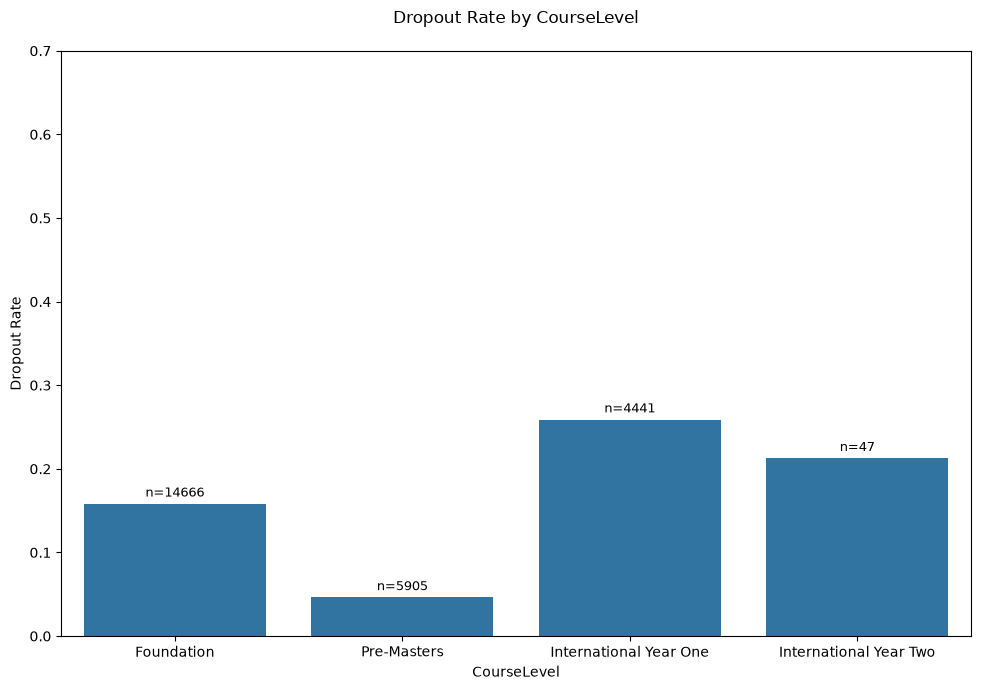

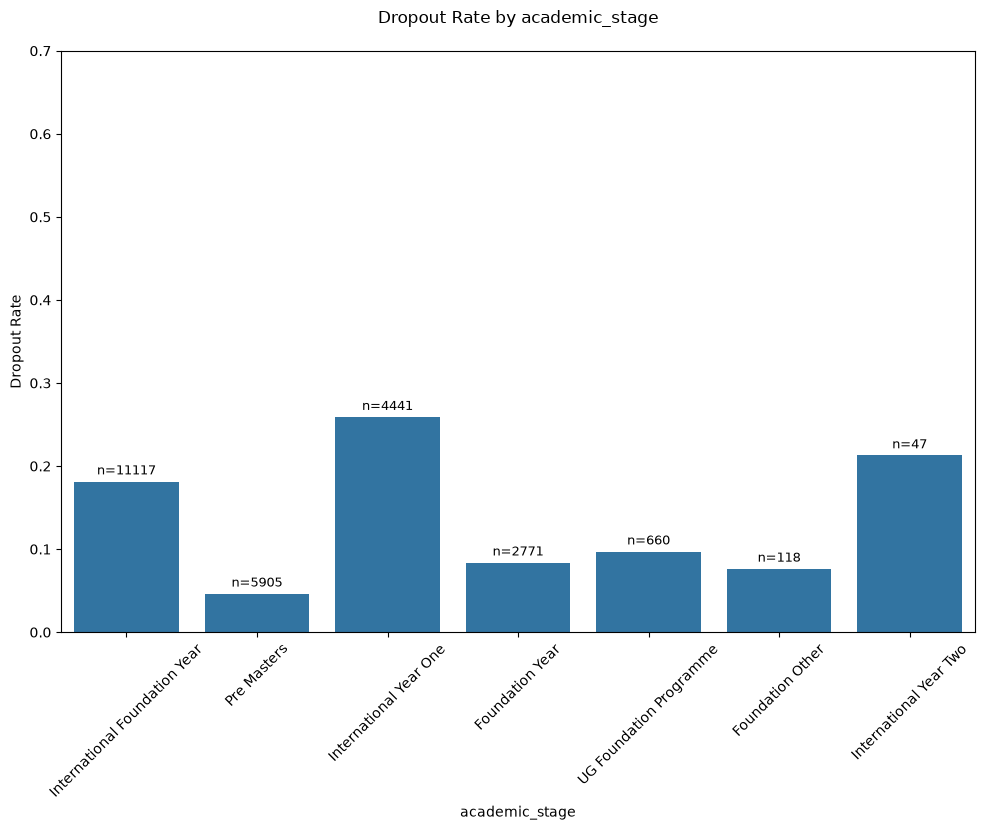

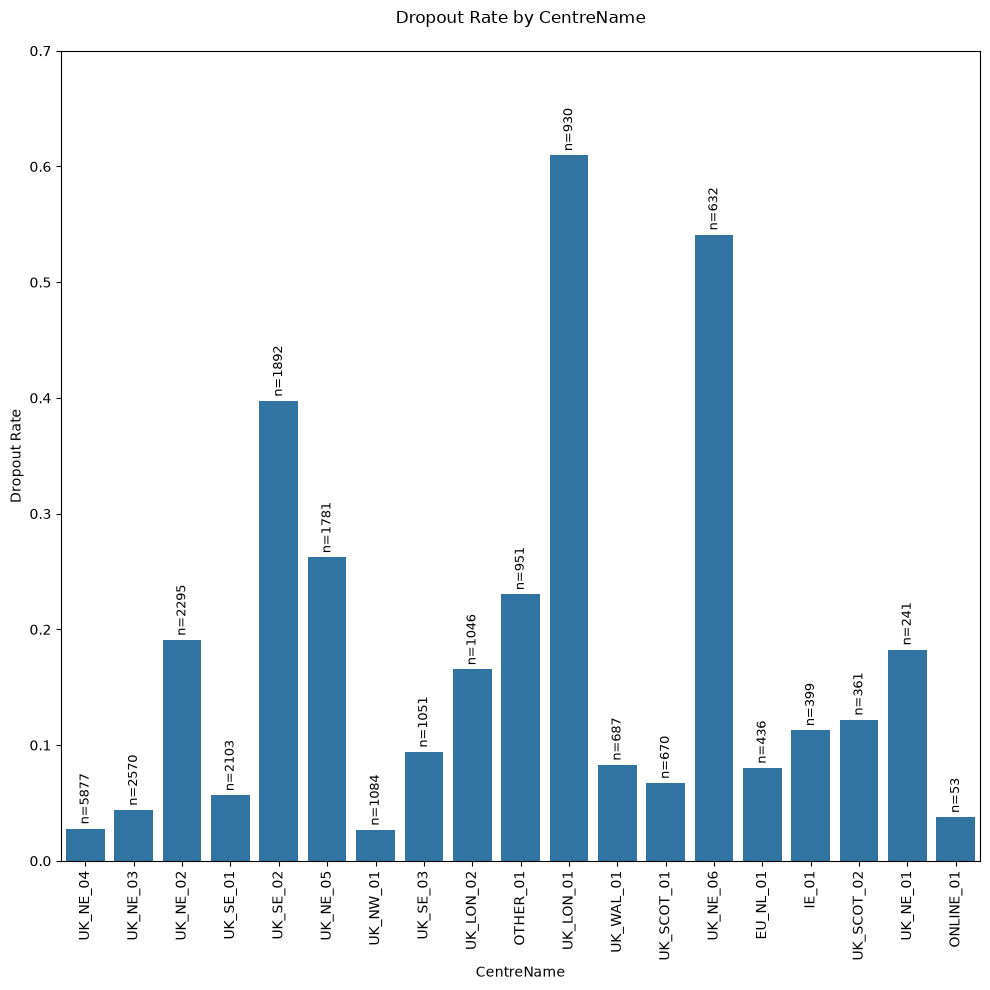

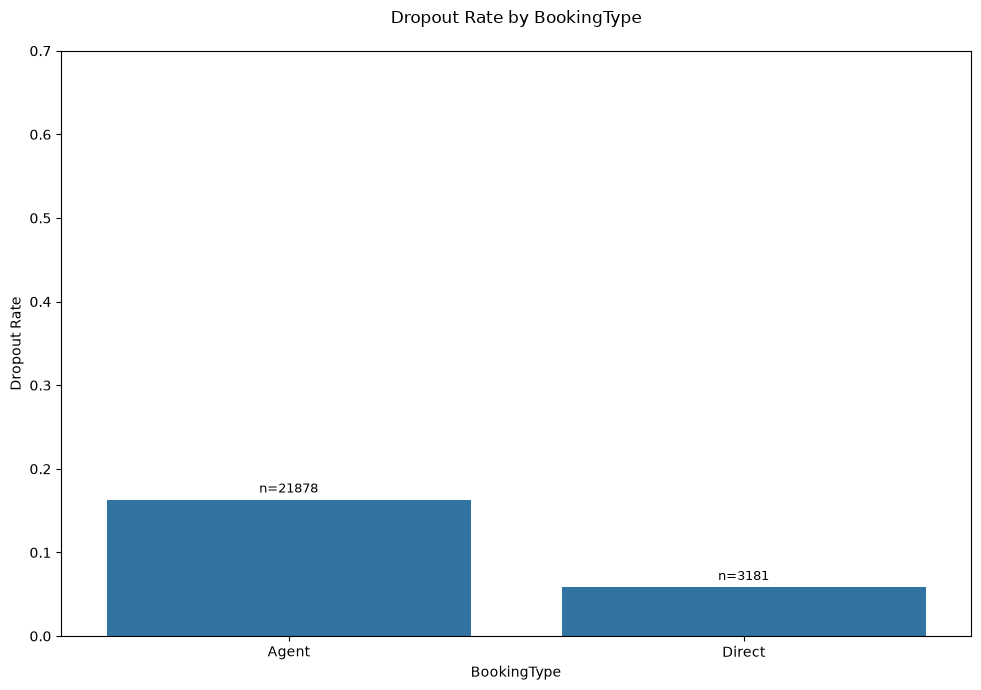

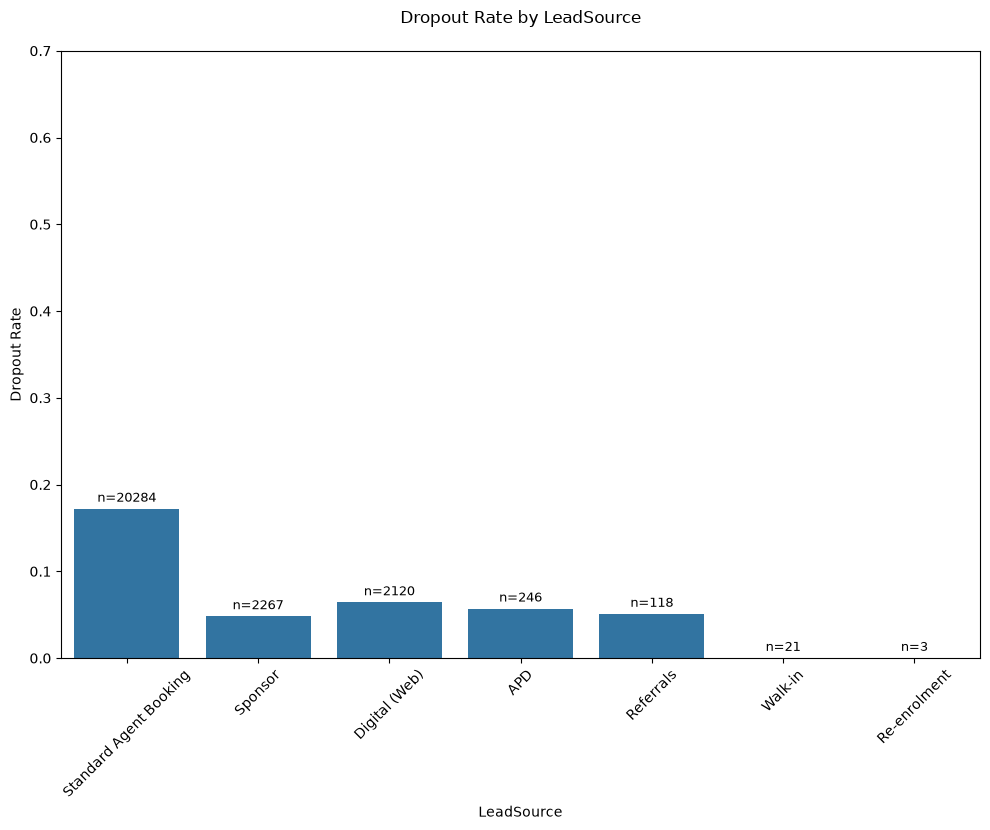

...

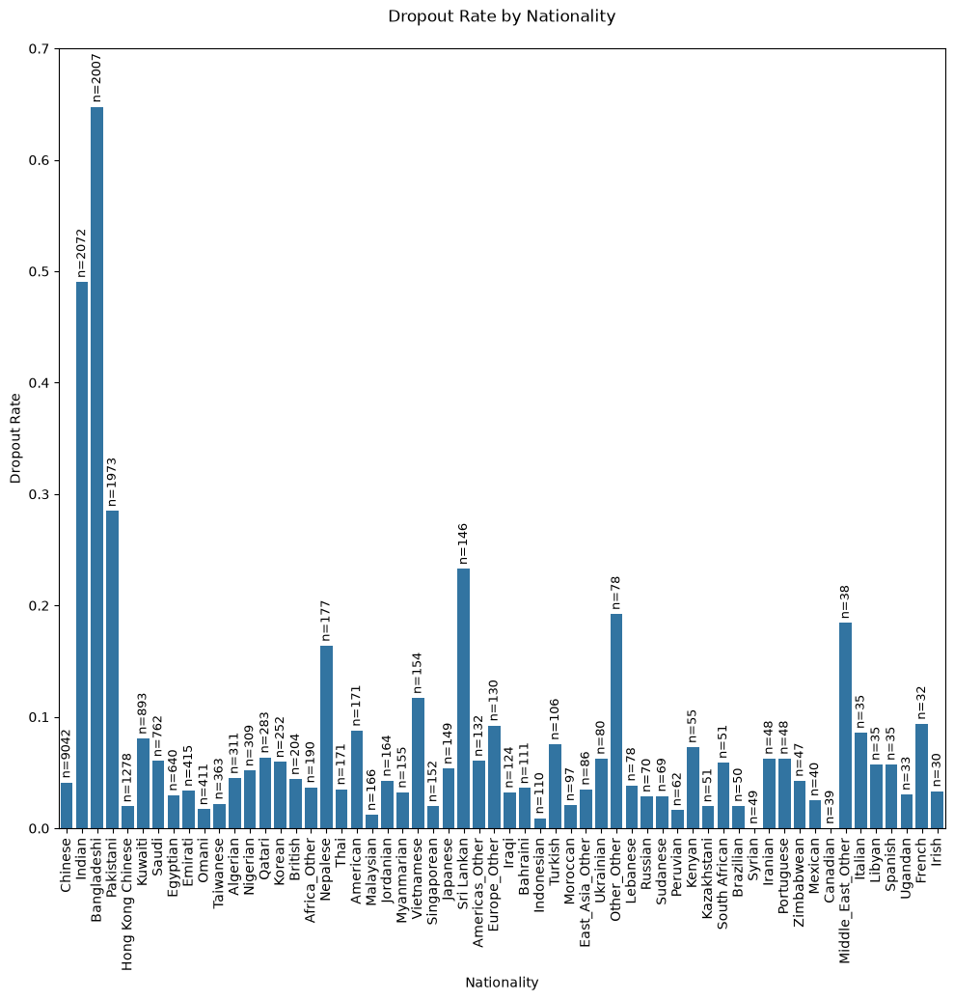

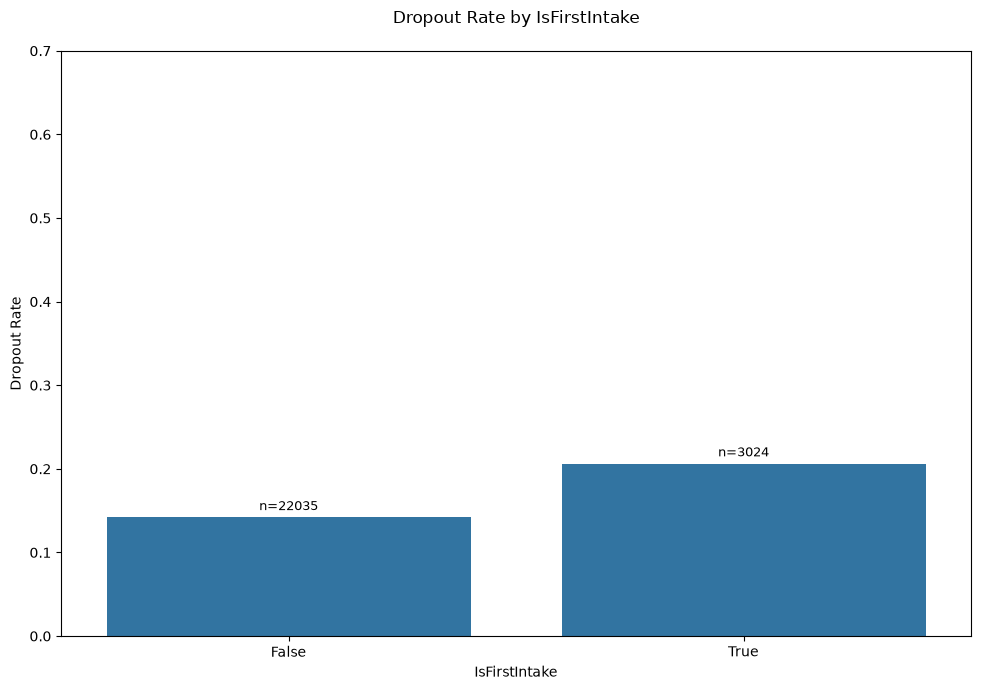

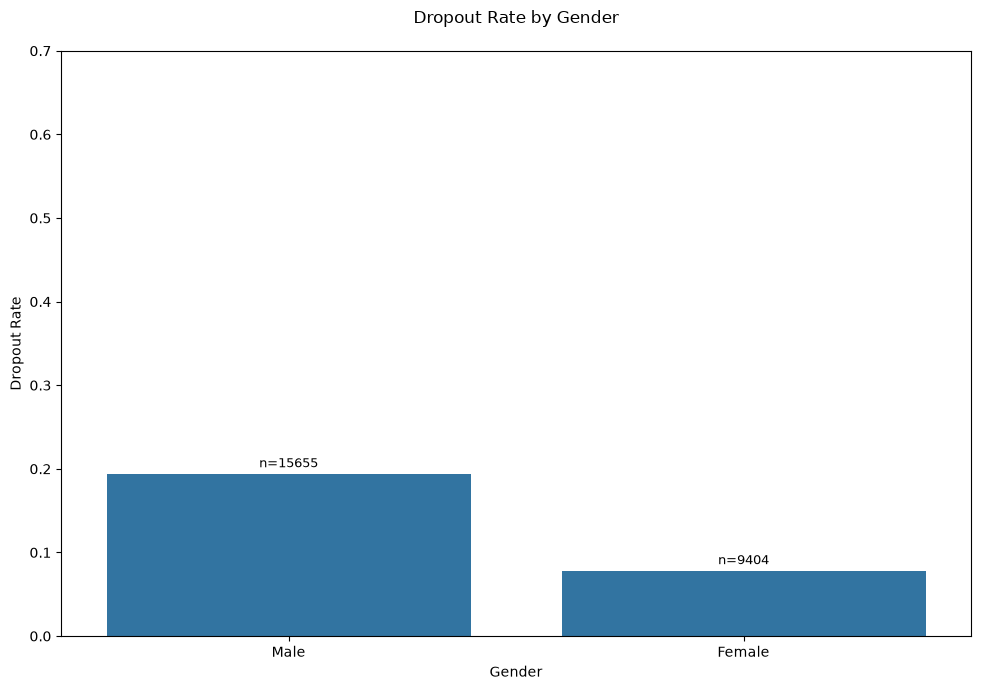

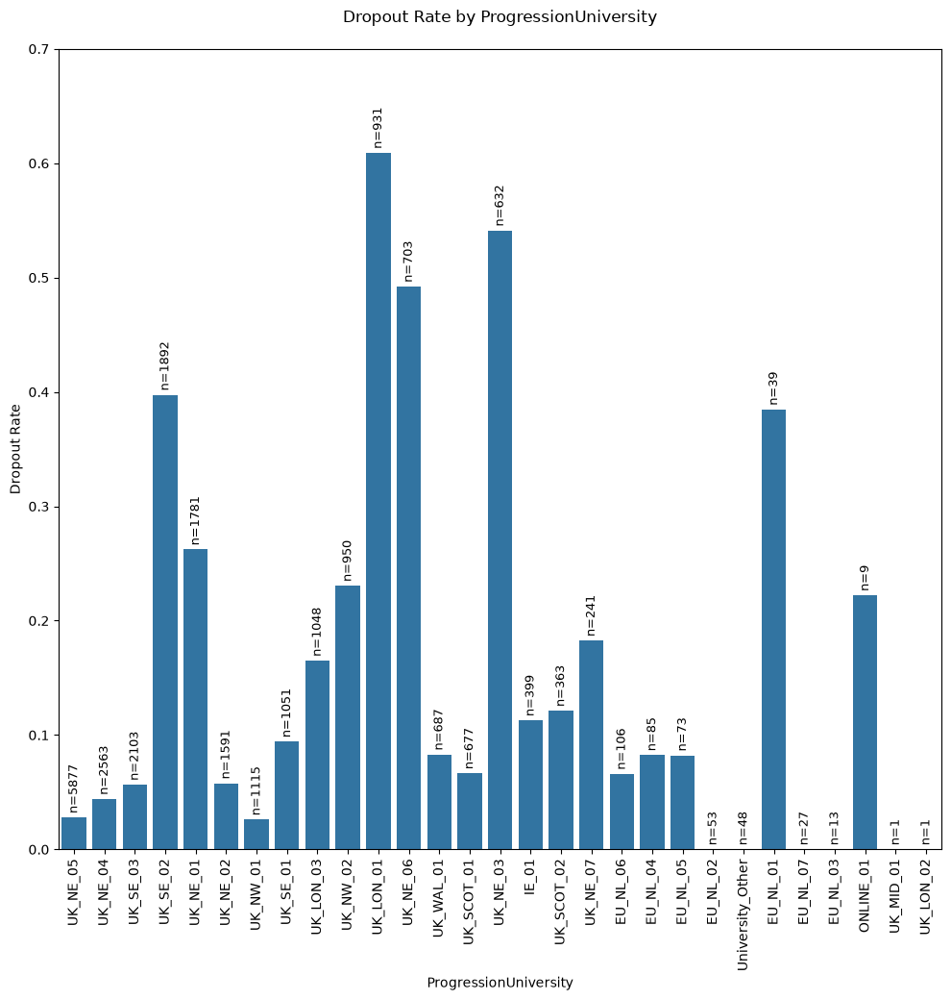

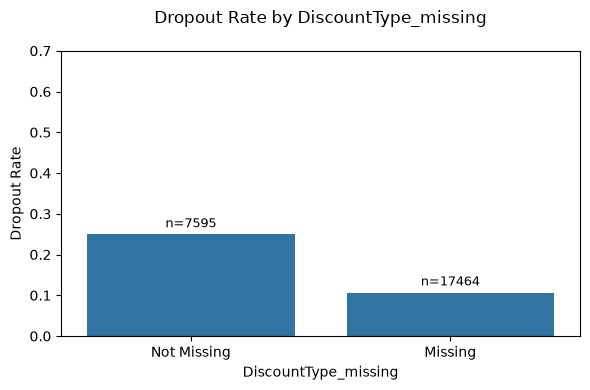

,CentreName,BookingType,LeadSource,DiscountType,Gender,Age,Nationality,academic_stage,subject_cluster,delivery_variant,IsFirstIntake,CompletedCourse,dropout,progression_degree_level,ProgressionUniversity,progression_degree_missing
0,UK_SCOT_02,Agent,Standard Agent Booking,NoDiscount,Male,27,Chinese,Pre Masters,Business_Law_Combined,standard,True,Yes,0,MSc,UK_SCOT_02,False
1,UK_SCOT_02,Agent,Standard Agent Booking,NoDiscount,Male,27,Chinese,UG Foundation Programme,Science_Health,standard,False,Yes,0,BSc,UK_SCOT_02,False
2,UK_SCOT_02,Agent,Standard Agent Booking,NoDiscount,Male,25,Chinese,International Year Two,Business_Economics_Finance,standard,False,Yes,0,MA,UK_SCOT_02,False
3,UK_SCOT_02,Agent,Standard Agent Booking,NoDiscount,Male,26,Chinese,International Year Two,Business_Economics_Finance,standard,True,Yes,0,MA,UK_SCOT_02,False
4,UK_SCOT_02,Agent,Standard Agent Booking,NoDiscount,Male,29,Chinese,Pre Masters,Business_Law_Combined,standard,True,Yes,0,MSc,UK_SCOT_02,False


,Gender,Age,IsFirstIntake,dropout,progression_degree_missing,academic_stage_Foundation Other,academic_stage_Foundation Year,academic_stage_International Foundation Year,academic_stage_International Year One,academic_stage_International Year Two,...,ProgressionUniversity_UK_NE_07,ProgressionUniversity_UK_NW_01,ProgressionUniversity_UK_NW_02,ProgressionUniversity_UK_SCOT_01,ProgressionUniversity_UK_SCOT_02,ProgressionUniversity_UK_SE_01,ProgressionUniversity_UK_SE_02,ProgressionUniversity_UK_SE_03,ProgressionUniversity_UK_WAL_01,ProgressionUniversity_University_Other
0,0,27,1,0,False,0,0,0,0,0,...,0,0,0,0,1,0,0,0,0,0
1,0,27,0,0,False,0,0,0,0,0,...,0,0,0,0,1,0,0,0,0,0
2,0,25,0,0,False,0,0,0,0,1,...,0,0,0,0,1,0,0,0,0,0
3,0,26,1,0,False,0,0,0,0,1,...,0,0,0,0,1,0,0,0,0,0
4,0,29,1,0,False,0,0,0,0,0,...,0,0,0,0,1,0,0,0,0,0


## Stage 1 - XGBoost Model 

### Baseline Model

We will define and instantiate a simple XGBOOST model, fit the model to the training dataset and visualise the loss curves.

Initial baseline parameters will be selected to provide a balance between model complexity, and computational efficiency as follows:

*Model capacity*
- A shallow tree depth (max_depth=3)
- A moderate learning rate (learning_rate=0.1) 

*Regularisation*
- Row and feature subsampling (subsample=0.8, colsample_bytree=0.8) 

The model will be trained with 100 boosting rounds (n_estimators=100) and evaluated using AUC.



Loaded verified Stage 1 baseline XGBoost model from /home/alexd/projects/student-dropout-prediction/student-dropout-prediction/models/stage_1/xgboost/baseline_model.joblib


/home/alexd/miniforge3/envs/student-dropout/lib/python3.12/pickle.py:1760: UserWarning: [16:14:36] WARNING: /__w/xgboost/xgboost/src/collective/../data/../common/error_msg.h:83: If you are loading a serialized model (like pickle in Python, RDS in R) or
configuration generated by an older version of XGBoost, please export the model by calling
`Booster.save_model` from that version first, then load it back in current version. See:

    https://xgboost.readthedocs.io/en/stable/tutorials/saving_model.html

for more details about differences between saving model and serializing.

  setstate(state)


### Baseline Performance Metrics

We will now evaluate the model against the test set using the following performance indicators:
 - Accuracy
 - Precision
 - Recall
 - AUC

A confusion matrix, ROC and Precision-Recall Curves will also be plotted.

Stage 1 XGBoost - Baseline Performance Metrics:
Accuracy:    0.8958
Precision:   0.6951
Recall:      0.5433
Specificity: 0.9580
AUC:         0.8951


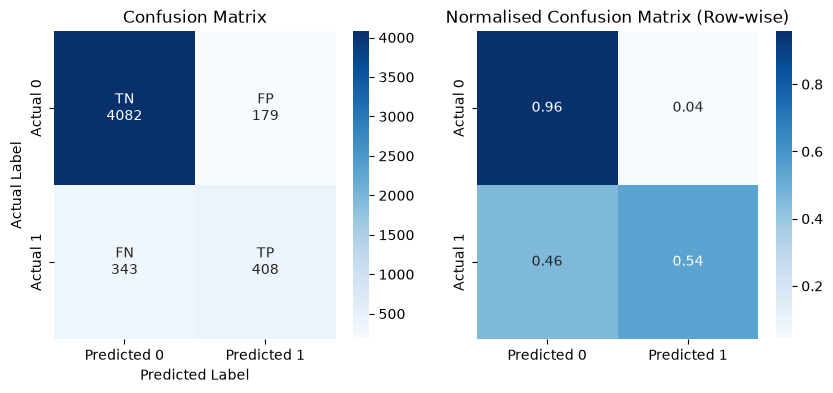

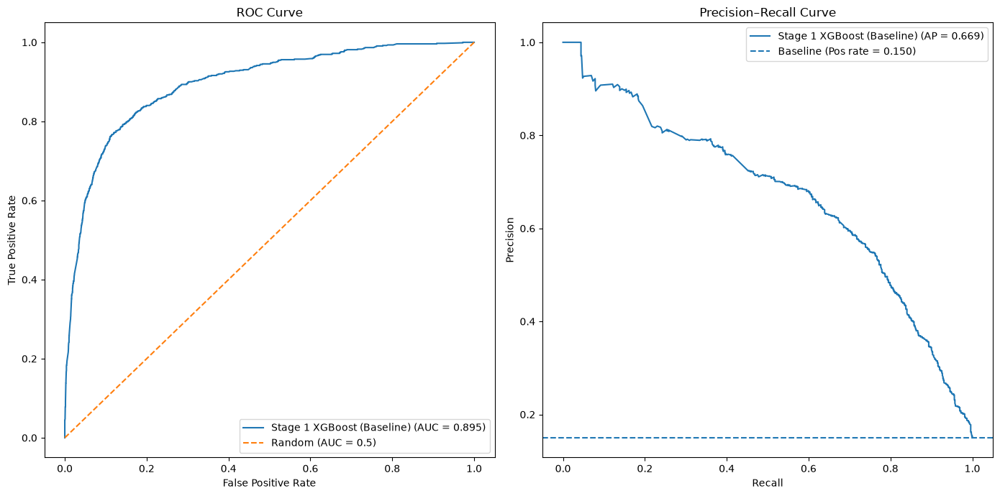

**Baseline Performance Metrics Interpretation**

---


**Accuracy = 0.8958**

Due to the class imbalance (≈85% course completions), a naive classifier that predicts all observations as non-dropouts would achieve an accuracy of:

- 4261/5012≈0.85

The model improves accuracy by around 4.6 percentage points over the trivial baseline.

**Precision = 0.6951**

When the model predicts dropout, it is correct approximately 70% of the time.

**Recall = 0.5433**

The model correctly identifies approximately 54% of students who actually drop out, meaning nearly half of dropout cases are incorrectly predicted as course completers.

**Specificity = 0.9580**

The specificity indicates that the model correctly identifies approximately 96% of completers, meaning that few completers will be incorrectly classified as at risk of dropout.

**AUC = 0.8951**

- Test AUC = 0.8951 -> reasonable performance for a baseline model
- This indicates good discrimination ability, meaning the model can reasonably distinguish between students who drop out and those who complete their course.

---

**Summary**

The baseline XGBoost model achieves moderate recall (54%) for dropout detection, meaning that just over half of students who ultimately drop out are correctly identified by the model. However, the model demonstrates very high specificity (≈96%), indicating that the majority of students who complete their course are correctly classified.

This reflects the underlying class imbalance in the dataset, where course completion is substantially more common than dropout. As a result, the model tends to favour predicting course completion, leading to missed dropout cases (false negatives).

Precision for dropout predictions is approximately 70%, indicating that when the model flags a student as at risk of dropout, this prediction is correct in the majority of cases.

As the objective is to predict dropout in order to identify at-risk students, the current classification threshold of 0.5 may not be optimal. Adjusting the decision threshold or applying further model tuning could improve recall of dropout cases, enabling more effective identification of at-risk students balanced against an acceptable false positive rate.




### Hyperparameter Tuning

The following hyperparameter ranges are centred on the baseline settings and extended to cover both lower-capacity (more regularised) and moderately higher-capacity models

Extreme values that might lead to unstable training or overfitting are avoided.


A grid over these candidate parameters would be highly computationally expensive (e.g., 8 parameters × ~5 values each ≈ 5⁸ = 390,625 combinations).

Optuna uses Bayesian optimisation to adaptively sample hyperparameters based on previous results. This approach can identify strong configurations with far fewer evaluations than exhaustive grid search or random search. It is particularly effective for gradient boosting models because their hyperparameter behaviour tends to be more predictable and less stochastic than neural network training.

Logarithmic sampling will be specified for hyperparameters whose plausible values span several orders of magnitude (e.g., learning_rate, min_child_weight, and regularisation parameters). This allows the optimisation process to explore smaller values more effectively while still considering larger values, improving the efficiency of the search.

Training time with early stopping for XGBoost is minimal (~0.5s per trained model), therefore we can afford to complete many trials. An initial value will be 2000

source                /home/alexd/projects/student-dropout-predictio...
evidence                                                completed_trial
study                                                   xgb_tabular_auc
trial                                                              1546
historical_val_auc                                             0.890342
dtype: object

colsample_bytree    0.988280
gamma               1.868997
learning_rate       0.146668
max_depth           8.000000
min_child_weight    1.107940
reg_alpha           0.019465
reg_lambda          0.030819
subsample           0.856013
Name: saved_parameters, dtype: float64

Best validation AUC: 0.8903421309872923
Best params: {'colsample_bytree': 0.9882795058818716, 'gamma': 1.8689967766791105, 'learning_rate': 0.14666797316704522, 'max_depth': 8, 'min_child_weight': 1.1079395093578468, 'reg_alpha': 0.019465311593045143, 'reg_lambda': 0.03081909706850276, 'subsample': 0.8560129261469889}
Loaded saved XGBoost trial history from /home/alexd/projects/student-dropout-prediction/student-dropout-prediction/tuning/stage_1/xgboost/trials.csv


,number,value,datetime_start,datetime_complete,duration,params_colsample_bytree,params_gamma,params_learning_rate,params_max_depth,params_min_child_weight,params_reg_alpha,params_reg_lambda,params_subsample,state
1546,1546,0.890342,2026-03-23 18:06:20.268549,2026-03-23 18:06:20.554930,0 days 00:00:00.286381,0.988280,1.868997,0.146668,8,1.107940,0.019465,0.030819,0.856013,COMPLETE
1531,1531,0.889433,2026-03-23 18:06:15.894095,2026-03-23 18:06:16.170123,0 days 00:00:00.276028,0.995321,1.748272,0.157411,8,1.135092,0.035548,0.039990,0.853834,COMPLETE
904,904,0.889133,2026-03-23 18:03:14.749614,2026-03-23 18:03:15.036541,0 days 00:00:00.286927,0.972317,1.490358,0.131159,8,1.131289,1.027244,0.020992,0.864638,COMPLETE
1933,1933,0.889003,2026-03-23 18:08:14.408262,2026-03-23 18:08:14.749445,0 days 00:00:00.341183,0.972638,1.472687,0.144236,8,1.094916,0.013008,0.036976,0.868179,COMPLETE
1095,1095,0.888957,2026-03-23 18:04:08.925630,2026-03-23 18:04:09.193536,0 days 00:00:00.267906,0.981587,1.793235,0.118471,8,1.054929,0.227856,0.025594,0.873621,COMPLETE
1940,1940,0.888925,2026-03-23 18:08:16.766494,2026-03-23 18:08:17.065816,0 days 00:00:00.299322,0.959919,1.996118,0.146996,8,1.104241,0.015993,0.056155,0.868210,COMPLETE
1607,1607,0.888903,2026-03-23 18:06:37.142466,2026-03-23 18:06:37.419647,0 days 00:00:00.277181,0.993079,1.969707,0.134481,8,1.082768,0.080645,0.061680,0.864547,COMPLETE
307,307,0.888717,2026-03-23 18:00:22.834975,2026-03-23 18:00:23.149861,0 days 00:00:00.314886,0.979325,2.106093,0.167709,8,3.357470,0.009394,0.030655,0.866691,COMPLETE
790,790,0.888677,2026-03-23 18:02:41.241797,2026-03-23 18:02:41.510280,0 days 00:00:00.268483,0.991740,1.470169,0.167141,8,1.616891,0.448322,0.013700,0.867915,COMPLETE
221,221,0.888628,2026-03-23 17:59:52.106290,2026-03-23 17:59:52.419491,0 days 00:00:00.313201,0.938084,2.574393,0.138247,8,1.190134,0.004106,0.056560,0.855808,COMPLETE


### Tuned Model

---

Hyperparameters for the best performing model are shown below and compared to the baseline model:

| Hyperparameter       | Baseline Model | Tuned Model (Optuna) | Interpretation                           |
| -------------------- | -------------- | -------------------- | ---------------------------------------- |
| **learning_rate**    | 0.10           | **0.1467**           | Faster boosting updates                  |
| **max_depth**        | 3              | **8**                | Allows more complex feature interactions |
| **min_child_weight** | –              | **1.11**             | Low constraint on leaf splits            |
| **gamma**            | –              | **1.87**             | Moderate split regularisation            |
| **subsample**        | 0.80           | **0.8560**           | Slightly more training rows per tree     |
| **colsample_bytree** | 0.80           | **0.9883**           | Uses almost all features per tree        |
| **reg_alpha (L1)**   | 0              | **0.0195**           | Light L1 regularisation                  |
| **reg_lambda (L2)**  | 1 (default)    | **0.0308**           | Very low L2 regularisation               |
| **n_estimators**     | 100            | **Early stopping**   | Adaptive boosting rounds                 |


The optimal configuration selected by Optuna uses deep trees (max_depth = 8) with moderate split regularisation (gamma ≈ 1.87) and row / feature subsampling.

The model uses a higher learning rate (≈ 0.15) combined with early stopping. Regularisation values remain low, suggesting that the tuned model relies more on tree depth, split constraints, and subsampling than on heavy L1/L2 penalties.

---

**Stability Evaluation**

A check for model stability across different random seeds will be performed before model performance metrics are evaluated.



XGBoost stability retraining is disabled.


Mean AUC and standard deviation show good model stability, with mean test AUC = 0.8983 and standard deviation = 0.00068 across the evaluated random seeds.

### Tuned Performance Metrics

We will now evaluate the model against the same performance parameters used to evaluate the baseline model.



Stage 1 XGBoost - Tuned Performance Metrics:
Accuracy:    0.8990
Precision:   0.6979
Recall:      0.5752
Specificity: 0.9561
AUC:         0.8988


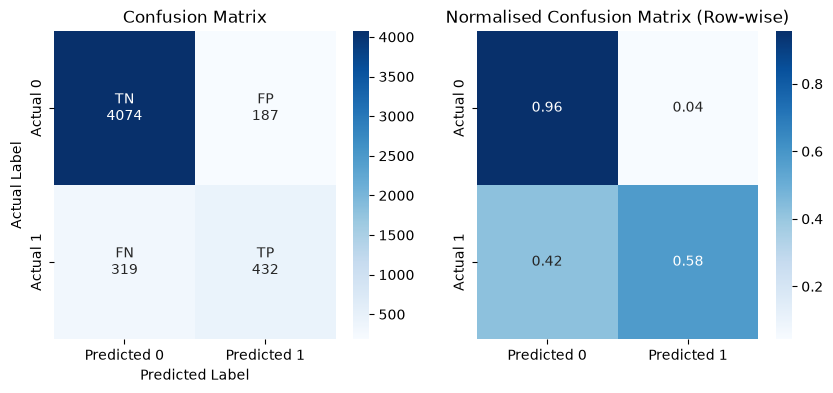

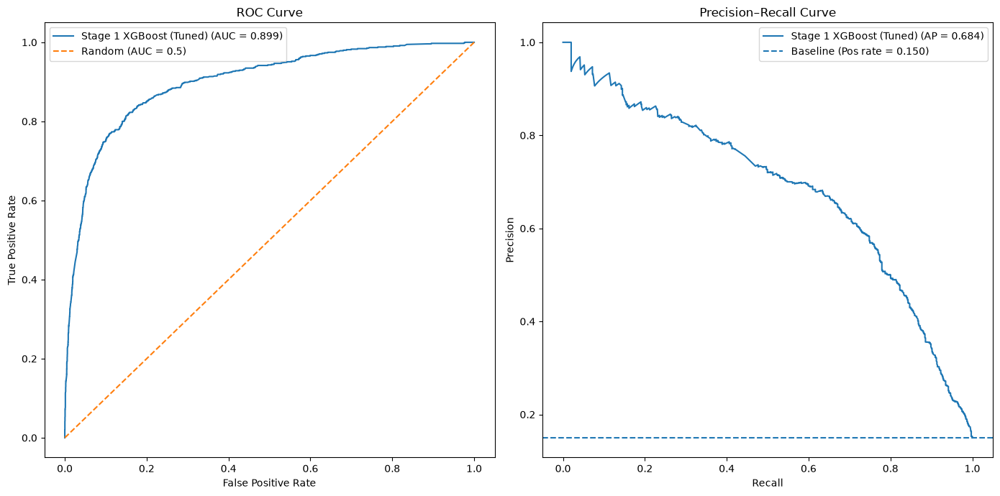

### Untuned vs Tuned Comparison

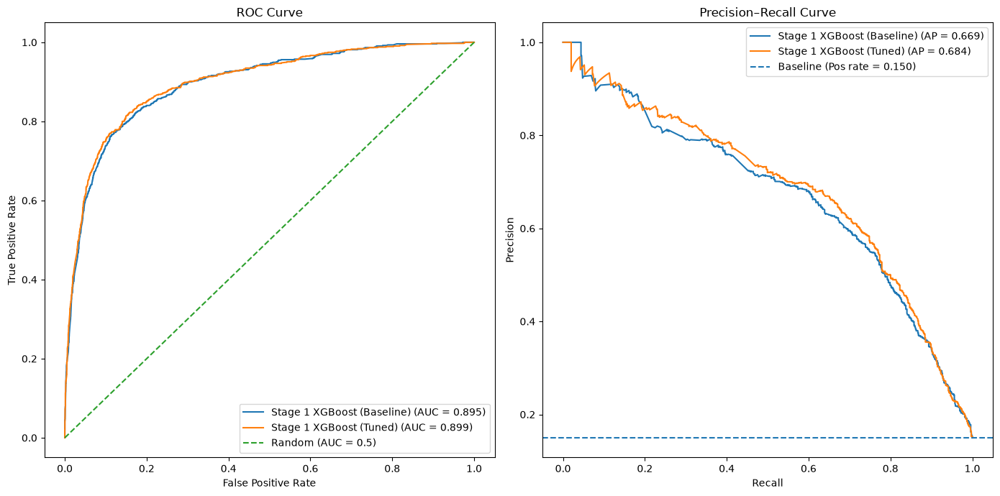

**Model Comparison (with / without Hyperparameter Tuning)**

---

The tuned model shows only small differences compared with the baseline model. A comparison is shown below:

| Metric      | Baseline   | Tuned      |
| ----------- | ---------- | ---------- |
| Accuracy    | 0.8958     | **0.8990** |
| Precision   | 0.6951     | **0.6979** |
| Recall      | 0.5433     | **0.5752** |
| Specificity | **0.9580** | 0.9561     |
| AUC         | 0.8951     | **0.8988** |


Hyperparameter tuning results in only modest changes across the evaluation metrics, suggesting that the baseline model was already capturing most of the predictive signal available in the dataset. During tuning, validation AUC plateaued at approximately 0.89, indicating that model performance may be approaching the limit achievable with the current feature set.

Validation AUC and test AUC remain very similar, with the test AUC slightly higher. This indicates that the tuned model generalises well to unseen data and does not show clear signs of overfitting.

Compared with the baseline, the tuned model achieves a small improvement in recall, precision, accuracy, and AUC, while specificity decreases slightly, indicating a small increase in false positives when predicting dropout. This behaviour is consistent with a model that is more willing to flag students as at risk in order to capture a greater proportion of true dropouts.

Overall, the tuned model provides a slightly stronger ability to identify students who may fail to complete the course. This trade-off may be acceptable, if failing to identify at-risk students (false negatives) is more costly than incorrectly flagging some students who ultimately complete the course.

---

### Feature Importance

We can now determine feature importance in respect of the trained model. 

Both feature importance and SHAP plots will be created so that we can compare how well they align and use SHAP to better understand magnitude and direction of feature influence.



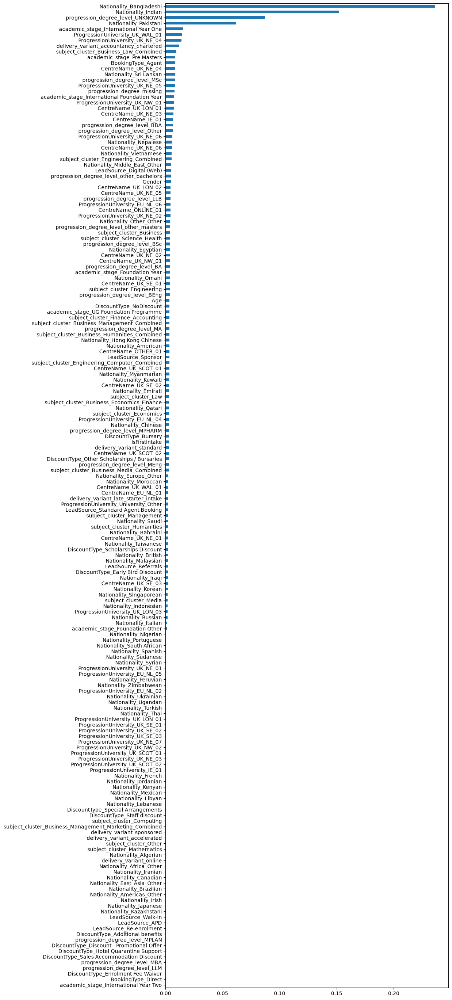

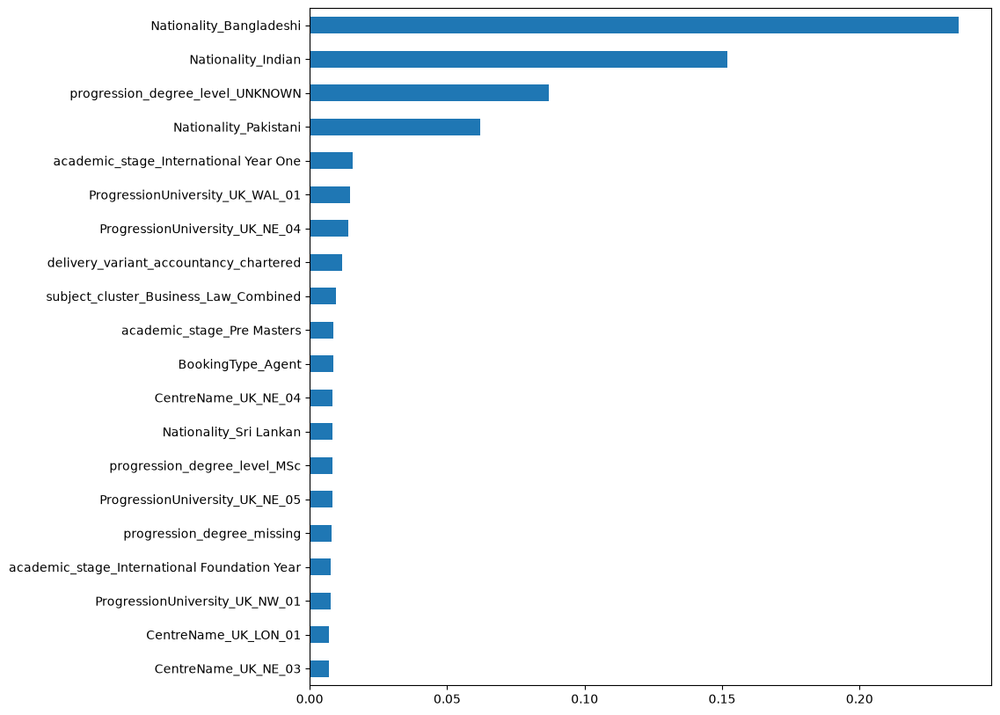

/tmp/ipykernel_214481/524827228.py:11: FutureWarning: The NumPy global RNG was seeded by calling `np.random.seed`. In a future version this function will no longer use the global RNG. Pass `rng` explicitly to opt-in to the new behaviour and silence this warning.
  shap.summary_plot(shap_values, X_test_plot, max_display=40, show=False)


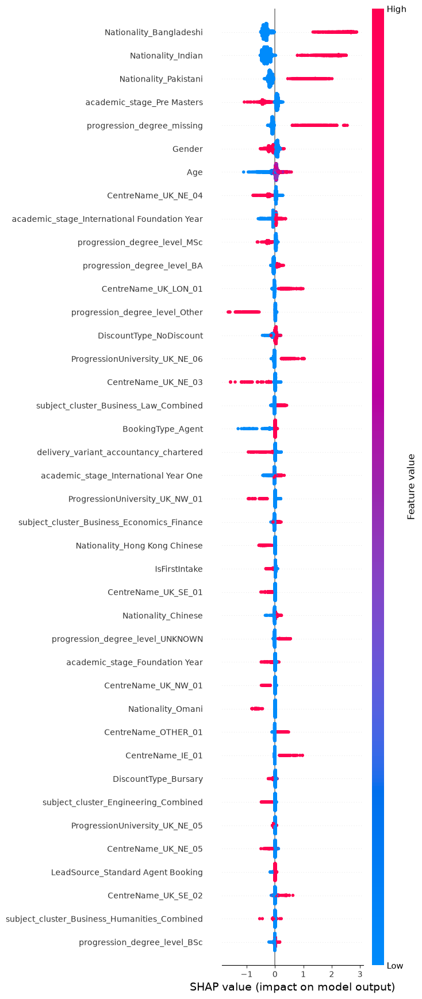

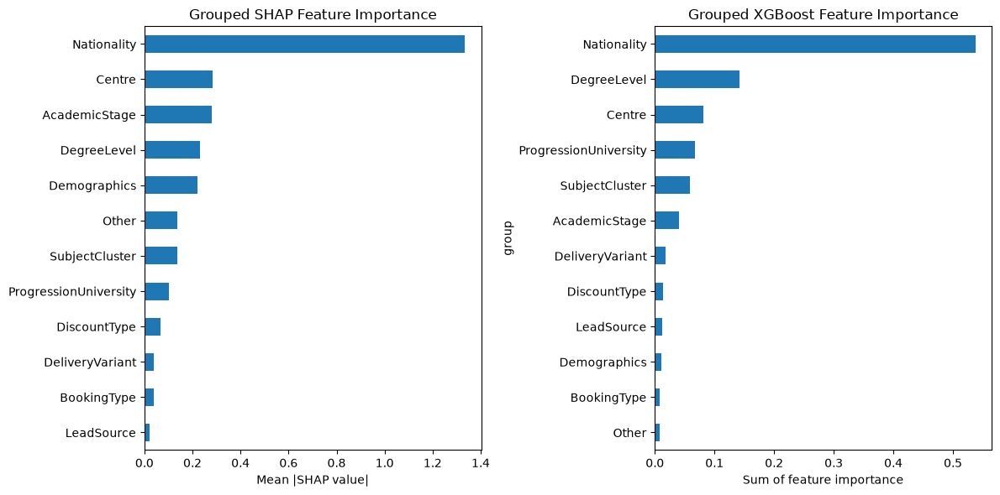

**Interpretation**

---

Feature importance analysis indicates that nationality and institutional characteristics are the most influential predictors of student progression outcomes. Specifically: 

1) **Nationality dominates the model with top features:**

Several nationality features score highly in model feature importance

2) **Institution / centre features**

Centre-related features appearing in the saved SHAP output include:

- CentreName_UK_NE_04
- CentreName_UK_LON_01
- CentreName_UK_NE_03
- CentreName_UK_SE_01

3) **Progression university features**

- This may be because some universities have stricter entry requirements, and programme difficulty differs.

4) **Academic stage variables**

- academic_stage_International Year One
- academic_stage_Pre Masters

5) **Subject cluster**

- This is expected as subject difficulty can vary significantly across fields.

NOTE: Due to one-hot encoding, importance is spread across many variables (e.g. Nationality), when in reality they represent a single variable.

Several nationality categories appear among the top predictors, indicating an association between nationality categories and dropout predictions in the supplied dataset. Institutional factors, including study centre location and progression university, also contribute strongly to predictions. Academic stage and subject cluster provide additional predictive signal, while demographic factors such as age and marketing variables such as lead source or discount type appear to have relatively low influence.

**Comparison with SHAP**

XGBoost's feature_importances_ (defaulting to gain) ranks features by their average contribution to reducing model error. However, high-cardinality features like Nationality can sometimes appear more important simply because they provide many opportunities for splits. Conversely, powerful but sparse features may have lower importance scores because their high predictive impact is limited to a small subset of records, leading to a lower average gain across the entire model ensemble.


XGBoost importance measures how variables are used to split decision trees during model training, while SHAP values measure the contribution of each feature to the final predictions. The grouped and aggregated SHAP feature importance broadly aligns with the model’s feature importance results, although it is important to note that aggregating these features should be interpreted as an approximation rather than the exact importance of the original categorical variable.

SHAP analysis agrees that nationality is the strongest predictor in the model. Academic stage and progression university also contribute meaningfully to predictions, while institutional variables such as study centre and progression university have moderate influence. Demographic features such as age have a smaller but observable effect, and appear to have a larger impact on model predictions than the model importance alone would suggest, while marketing-related variables such as lead source and discount type contribute little predictive power.

Using both metrics provides a more complete view of how features influence both model training and final predictions.

---



## Neural Network Model

### Baseline Model

We will define and instantiate a simple neural network model, fit the model to the dataset and visualise the loss curves.

A reusable model builder function will be created to support later model tuning.



I0000 00:00:1792077279.424219  214481 gpu_device.cc:2043] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 3539 MB memory:  -> device: 0, name: NVIDIA GeForce RTX 4050 Laptop GPU, pci bus id: 0000:01:00.0, compute capability: 8.9


### Loss Curves

We'll now plot the loss curves to see how the model training progresses over each epoch.

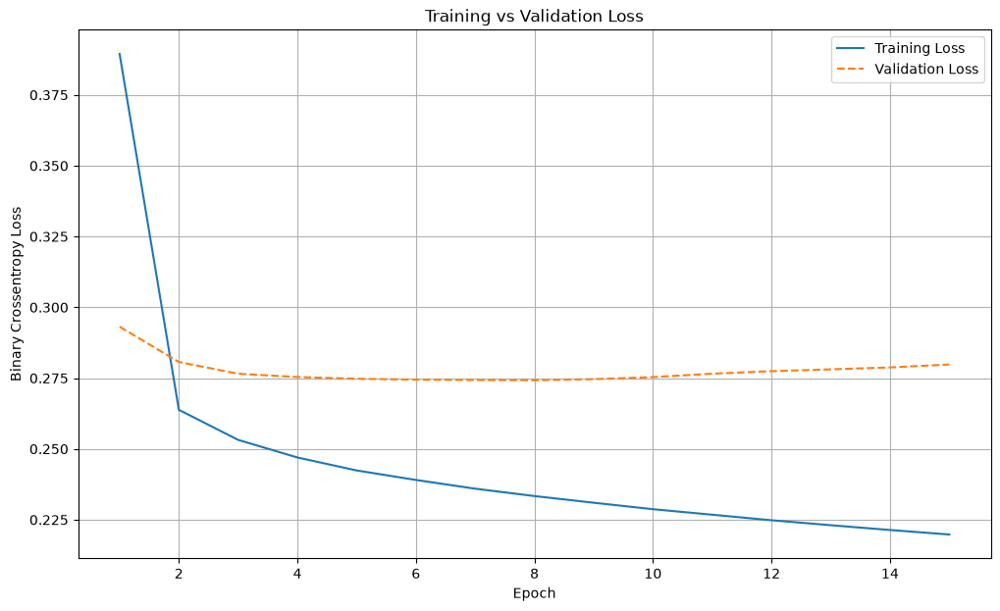

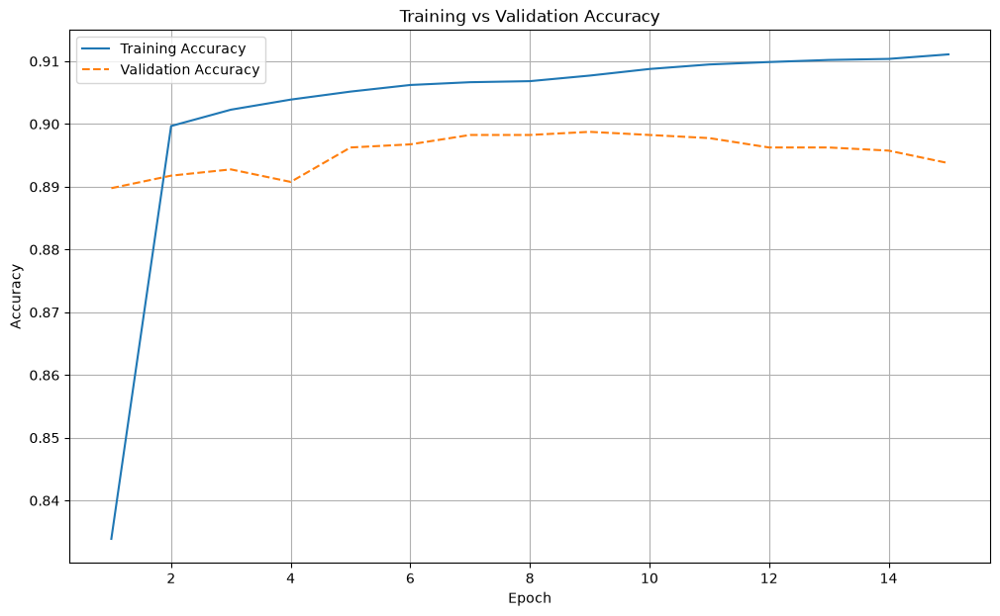

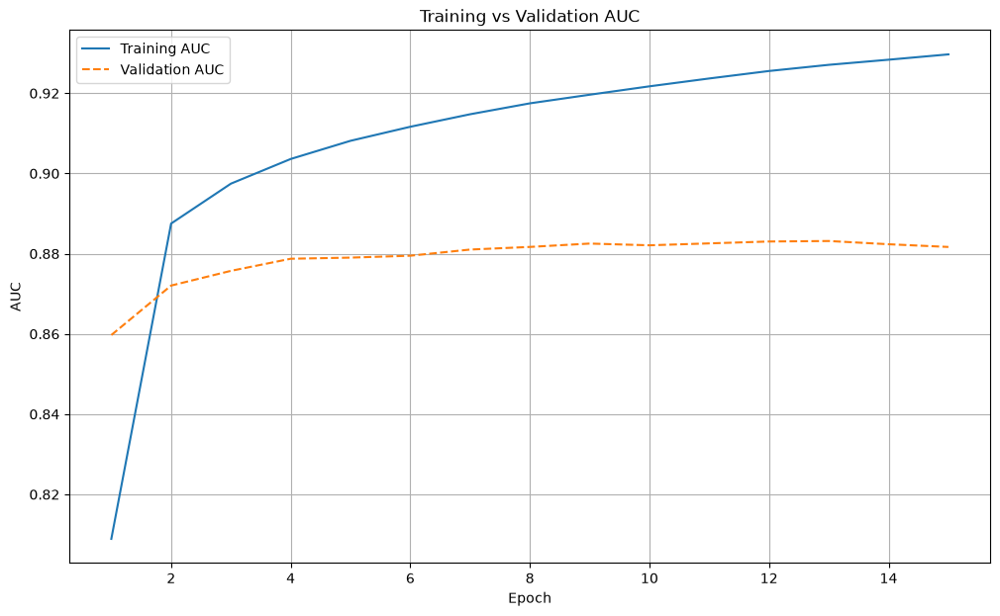

**Loss Curves Interpretation**

---

The model appears to generalise reasonably well for a simple baseline architecture (1 dense layer, 32 neurons).

Validation performance peaks around epoch 7–9, beyond that additional training improves training metrics but not validation metrics. Early stopping would be appropriate to minimise overfitting.

**Loss**

- Training loss steadily decreasing
- Validation loss decreases initially, then gradually increases past 6, indicating posibble overfitting to the training data with continued epochs
- There is no sharp divergence between curves.
- Gap between validation and training is modest.

**AUC**

- Training AUC increases steadily to ~0.93.
- Validation AUC peaks around epoch 9-10 (~0.88).


At 15 Epochs this baseline model shows signs of slight overfitting:

- Upward rise in Loss
- Slight decline in AUC
- Divergence between training and validation performance increases gradually.


This represents a valid baseline model for comparison with alternative arichecture models during Hyperparameter tuning.

---

### Baseline Performance Metrics

Performance indicators of Accuracy, precision, recall and AUC will be determined along with a confusion matrix.



I0000 00:00:1792077280.412652  214859 service.cc:153] XLA service 0x7a904802c740 initialized for platform CUDA (this does not guarantee that XLA will be used). Devices:
I0000 00:00:1792077280.412681  214859 service.cc:161]   StreamExecutor [0]: NVIDIA GeForce RTX 4050 Laptop GPU, Compute Capability 8.9 (Driver: 13.3.0; Runtime: 12.9.0; Toolkit: 12.5.0; DNN: 9.27.0)
I0000 00:00:1792077280.416923  214859 dump_mlir_util.cc:269] disabling MLIR crash reproducer, set env var `MLIR_CRASH_REPRODUCER_DIRECTORY` to enable.
I0000 00:00:1792077280.428092  214859 cuda_dnn.cc:461] Loaded cuDNN version 92700
I0000 00:00:1792077280.558614  214859 device_compiler.h:208] Compiled cluster using XLA!  This line is logged at most once for the lifetime of the process.


Stage 1 Neural Network - Baseline Performance Metrics:
Accuracy:    0.8951
Precision:   0.6692
Recall:      0.5925
Specificity: 0.9484
AUC:         0.8899


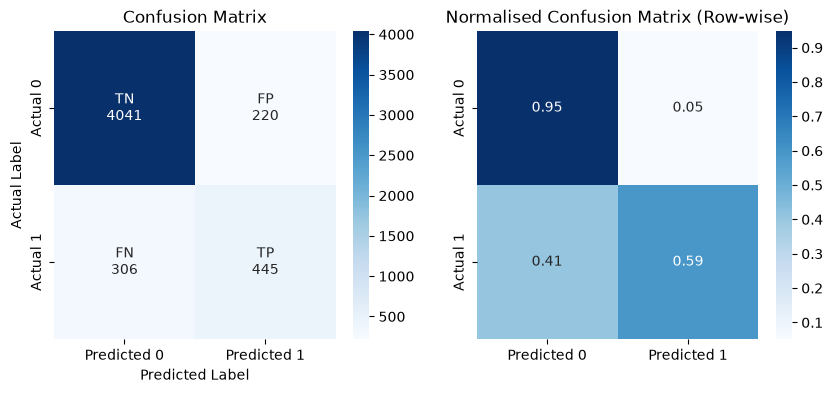

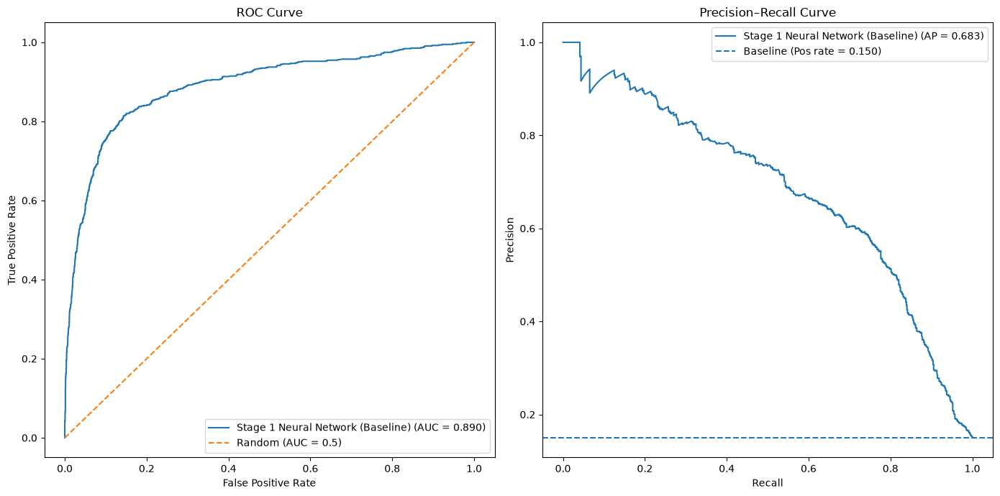

**Interpretation**

---

**Accuracy = 0.8951**

With ~15% positive rate, a trivial model that predicts all negatives would achieve:

- 4261 / 5012 ≈ 0.85

The neural network improves accuracy by ~4–5 percentage points over this baseline, indicating that the model is learning useful signal rather than relying on class imbalance.

**Precision = 0.6692**

When the model predicts a student will drop out, it is correct about 67% of the time.

This reflects the difficulty of the task, as dropout cases are relatively rare and harder to separate from completers.

**Recall = 0.5925**

The model correctly identifies about 59% of actual dropouts.

This means around 41% of at-risk students are not detected, which may limit the effectiveness of early intervention if recall is prioritised.

**Specificity = 0.9484**

The model correctly identifies approximately 95% of actual completers.

This indicates that false alarms are relatively low, so intervention effort would remain focused on a smaller group of students.


**AUC = 0.8899**

- Test AUC = 0.8899

The very small difference between validation and test performance suggests that the model is not overfitting, and generalises reasonably well to unseen data.

The ROC curve shows strong separation between classes across thresholds, and the PR curve remains well above the baseline positive rate (0.15).

**Summary**

The baseline neural network provides balanced performance, with good overall discrimination (AUC ≈ 0.89), moderate recall for dropout detection (~59%), and high specificity (~95%).

This may not be optimal if the business is willing to tolerate additional false positives in order to identify a greater proportion of at-risk students and enable earlier intervention. In such cases, the classification threshold can be adjusted to shift the balance between recall and specificity, allowing the model outputs to be aligned with business priorities without retraining the model.

---

### HyperParameter Tuning




We will now try to improve on the baseline model by exploring alternative neural-network hyperparameters using AUC as the primary selection metric.

Saved tuning artefacts are loaded by default so this public notebook can be rerun quickly. Full Keras Tuner searches are computationally expensive, so `RUN_NN_TUNING` is set to `False` by default. Set it to `True` if you want to regenerate the search results from scratch.

**Initial tuning strategy.**

---

A model will be instantiated and then trained on multiple combinations of the following initial hyperparameter search space.


NN search is disabled; reading saved search history without constructing a tuner.
Loaded saved NN tuning trials from /home/alexd/projects/student-dropout-prediction/student-dropout-prediction/tuning/stage_1/neural_network/initial_trials.csv


,units,layers,activation,optimizer,lr,dropout,l2_strength,trial_id,status,val_auc,val_precision,val_recall,val_accuracy,val_loss
0,240,3,relu,adam,0.0003,0.3,0.000100,1863,COMPLETED,0.887186,0.726087,0.556667,0.902244,0.318477
1,48,1,relu,adam,0.0010,0.4,0.000000,623,COMPLETED,0.886975,0.729858,0.513333,0.898753,0.286746
2,64,1,relu,adam,0.0003,0.4,0.000100,704,COMPLETED,0.886453,0.718615,0.553333,0.900748,0.283440
3,112,1,tanh,rmsprop,0.0010,0.3,0.000010,1672,COMPLETED,0.886318,0.703704,0.506667,0.894264,0.278514
4,112,4,tanh,adam,0.0003,0.3,0.000000,1322,COMPLETED,0.886283,0.694215,0.560000,0.897257,0.273470
5,48,1,relu,adam,0.0010,0.2,0.000010,1256,COMPLETED,0.886164,0.734884,0.526667,0.900748,0.277333
6,112,4,tanh,rmsprop,0.0003,0.1,0.000000,134,COMPLETED,0.886015,0.731959,0.473333,0.895262,0.269980
7,16,2,elu,adam,0.0010,0.0,0.000001,1255,COMPLETED,0.885854,0.746412,0.520000,0.901746,0.271988
8,256,1,relu,adam,0.0003,0.3,0.000010,1348,COMPLETED,0.885777,0.728507,0.536667,0.900748,0.280909
9,176,2,relu,adam,0.0003,0.4,0.000100,1975,COMPLETED,0.885721,0.739726,0.540000,0.902743,0.295644


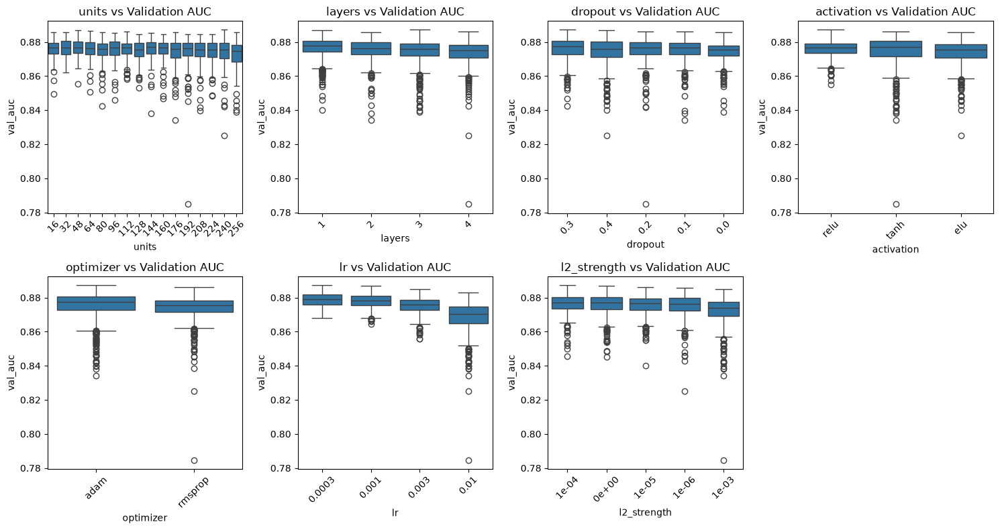

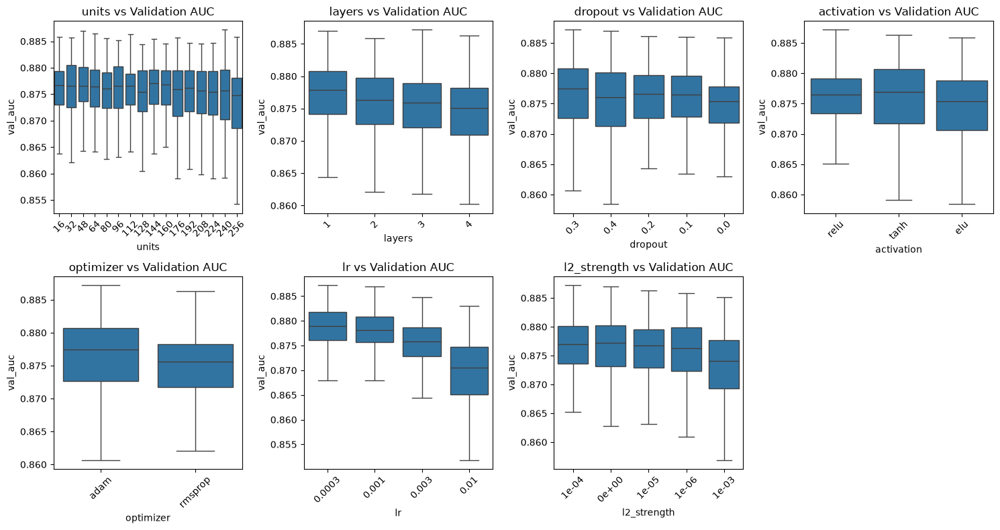

Skipping NN surrogate fitting; enable RUN_NN_SURROGATE_FITTING with trial history to run this analysis.


**Refined Tuning**

---

The box plots, SHAP plot, and tabular results provide evidence which allow us to tighten the search parameters as follows:

| Hyperparameter  | Initial Range          | Refined Range             | Combinations | Evidence Summary |
|---------------|----------------------|-------------------------|------------|----------------|
| **units**       | 16–256                 | **32–192 (step 16)**      | **11** | Similar performance across small–medium models; very large models show slightly higher variance |
| **layers**      | 1–4                    | **1–4**                   | **4**  | Performance similar across depths; no consistent benefit from deeper networks |
| **dropout**     | 0.0–0.5                | **0.0–0.4 (step 0.1)**    | **5**  | Moderate dropout gives similar or slightly better performance; extreme values not beneficial |
| **activation**  | relu, tanh, elu        | **relu, tanh**            | **2**  | ELU consistently lower median validation AUC |
| **optimizer**   | adam, rmsprop          | **adam, rmsprop**         | **2**  | Adam and RMSprop show similar performance; both retained |
| **lr**          | 1e-2, 3e-3, 1e-3, 3e-4 | **3e-4, 1e-3**            | **2**  | Higher learning rates reduce stability; lower values give higher and more consistent AUC |
| **l2_strength** | 0.0–1e-3               | **0.0, 1e-6, 1e-5, 1e-4** | **4**  | Strong regularisation reduces performance; small or zero L2 performs best |                                                                       |


Additional insight is provided by the SHAP analysis of the tuning results. The SHAP summary plot shows that learning rate, L2 regularisation strength, and network size parameters (units and layers) have the largest impact on validation AUC, while activation function and optimizer choice contribute relatively little to performance variation.

Higher learning rates and stronger regularisation are generally associated with negative SHAP values, indicating reduced model performance, whereas moderate network sizes and lower regularisation tend to produce positive contributions. This supports narrowing the search space around smaller learning rates, weaker regularisation, and mid-range model sizes.

The box plots, SHAP analysis, and tabular tuning results show that learning rate has the strongest influence on validation AUC, followed by L2 regularisation and model size parameters (units and layers). Dropout has a moderate effect, while activation function and optimizer choice have minimal impact. These results support narrowing the search space around smaller learning rates, weak regularisation, and mid-range model sizes.


---

**Resulting Search Space**

The refined search space contains approximately 7,040 possible hyperparameter combinations, reduced from the initial wide search. A random search of 200 trials will be used to sample this space, providing approximately 2.8% coverage while keeping the computational cost manageable.




NN search is disabled; reading saved search history without constructing a tuner.
Loaded saved refined NN tuning trials from /home/alexd/projects/student-dropout-prediction/student-dropout-prediction/tuning/stage_1/neural_network/trials.csv


,units,layers,activation,optimizer,lr,dropout,l2_strength,trial_id,status,val_auc,val_precision,val_recall,val_accuracy,val_loss
0,48,1,relu,adam,0.0010,0.2,0.000001,127,COMPLETED,0.886695,0.737089,0.523333,0.900748,0.274924
1,144,3,tanh,adam,0.0003,0.4,0.000000,185,COMPLETED,0.886557,0.703390,0.553333,0.898254,0.273876
2,80,1,relu,adam,0.0003,0.1,0.000001,58,COMPLETED,0.886118,0.727679,0.543333,0.901247,0.275596
3,112,3,relu,adam,0.0003,0.4,0.000000,73,COMPLETED,0.885882,0.721030,0.560000,0.901746,0.274986
4,160,2,tanh,adam,0.0003,0.1,0.000100,18,COMPLETED,0.885881,0.710407,0.523333,0.896758,0.297938
5,176,4,tanh,adam,0.0010,0.4,0.000000,41,COMPLETED,0.885657,0.722222,0.520000,0.898254,0.271641
6,128,4,tanh,adam,0.0003,0.4,0.000001,179,COMPLETED,0.885587,0.689922,0.593333,0.899252,0.278000
7,64,2,relu,adam,0.0010,0.3,0.000001,70,COMPLETED,0.885238,0.742424,0.490000,0.898254,0.282524
8,96,3,tanh,adam,0.0010,0.2,0.000010,104,COMPLETED,0.885238,0.705882,0.560000,0.899252,0.274832
9,192,3,tanh,adam,0.0003,0.4,0.000000,68,COMPLETED,0.885227,0.715517,0.553333,0.900249,0.273817



**Refined Hyperparameter Tuning Results**

The best AUC score from the initial hyperparameter RandomSearch has not been improved.

Across both tuning stages, the strongest models consistently fall within a narrow performance band of approximately 0.882–0.887 validation AUC. 

**Best Models - Evaluation**

It is important to note that wide range of model architectures appear within the ~0.882–0.887 AUC range. Small differences in validation AUC may reflect stochastic training variation rather than increased model performance. We will attempt to further evaluate model performance and stability as follows:

***Select the top 5 configurations and retrain each:***

- 3 different random seeds + original SEED value to validate repeatability
- batch size = 64
- same early stopping criteria
- same train/validation split

We will compute:

- mean validation AUC
- standard deviation

This may provide a more robust estimate of model performance and identify architectures that are both high performing and stable across training runs.

Top performing hyperparameter combinations from both searches:


,units,layers,activation,optimizer,lr,dropout,l2_strength,trial_id,status,val_auc,val_precision,val_recall,val_accuracy,val_loss,source
0,240,3,relu,adam,0.0003,0.3,0.000100,1863,COMPLETED,0.887186,0.726087,0.556667,0.902244,0.318477,initial
1,48,1,relu,adam,0.0010,0.4,0.000000,623,COMPLETED,0.886975,0.729858,0.513333,0.898753,0.286746,initial
2000,48,1,relu,adam,0.0010,0.2,0.000001,127,COMPLETED,0.886695,0.737089,0.523333,0.900748,0.274924,refined
2001,144,3,tanh,adam,0.0003,0.4,0.000000,185,COMPLETED,0.886557,0.703390,0.553333,0.898254,0.273876,refined
2,64,1,relu,adam,0.0003,0.4,0.000100,704,COMPLETED,0.886453,0.718615,0.553333,0.900748,0.283440,initial


,config_idx,units,layers,activation,optimizer,lr,dropout,l2_strength,seed_scores,mean_val_auc,std_val_auc
0,1,240,3,relu,adam,0.0003,0.3,0.000100,"[0.8823665976524353, 0.8796314001083374, 0.876...",0.879654,0.002206
2,3,48,1,relu,adam,0.0010,0.2,0.000001,"[0.8805649280548096, 0.8744985461235046, 0.875...",0.876929,0.002619
1,2,48,1,relu,adam,0.0010,0.4,0.000000,"[0.8794153928756714, 0.8739805221557617, 0.875...",0.876272,0.002299
3,4,144,3,tanh,adam,0.0003,0.4,0.000000,"[0.8719482421875, 0.8660722970962524, 0.865916...",0.867979,0.002807
4,5,64,1,relu,adam,0.0003,0.4,0.000100,"[0.8695513010025024, 0.8678142428398132, 0.864...",0.867446,0.001887


### Tuned Model

---

Stability tests were performed by training each candidate configuration using multiple random seeds.
The results are shown below:

| Model        | Units | Layers | Activation | Optimizer | LR     | Dropout | L2   | Mean Val AUC | Std    |
| ------------ | ----- | ------ | ---------- | --------- | ------ | ------- | ---- | ------------ | ------ |
| **Baseline** | 32    | 1      | relu       | adam      | 0.001  | 0.0     | 0.0  | ~0.87–0.88   | —      |
| Config_idx 1 | 240   | 3      | relu       | adam      | 0.0003 | 0.3     | 1e-4 | **0.8797**   | 0.0022 |
| Config_idx 3 | 48    | 1      | relu       | adam      | 0.001  | 0.2     | 1e-6 | 0.8769       | 0.0026 |
| Config_idx 2 | 48    | 1      | relu       | adam      | 0.001  | 0.4     | 0.0  | 0.8763       | 0.0023 |
| Config_idx 4 | 144   | 3      | tanh       | adam      | 0.0003 | 0.4     | 0.0  | 0.8680       | 0.0028 |
| Config_idx 5 | 64    | 1      | relu       | adam      | 0.0003 | 0.4     | 1e-4 | 0.8674       | 0.0019 |


The tuned neural network configurations achieved similar validation AUC values across several architectures, with differences of only a few thousandths between the top models.
However, one configuration consistently achieved the highest mean validation AUC while maintaining low variance across random seeds.

The best-performing model used a moderately large network with three hidden layers, a low learning rate, moderate dropout, and weak L2 regularisation.
This aligns with the earlier tuning analysis, which indicated that lower learning rates, moderate regularisation, and mid-to-large network sizes tend to produce the most reliable performance.

Because this configuration provides both the highest validation AUC and stable convergence across seeds, it was selected as the final tuned neural network model.

Therefore, the final chosen model parameters are:

| Model        | Units | Layers | Activation | Optimizer | LR     | Dropout | L2   | Mean Val AUC | Std    |
| ------------ | ----- | ------ | ---------- | --------- | ------ | ------- | ---- | ------------ | ------ |
| Config_idx 1 | 240   | 3      | relu       | adam      | 0.0003 | 0.3     | 1e-4 | **0.8797**   | 0.0022 |


---

Model loaded from /home/alexd/projects/student-dropout-prediction/student-dropout-prediction/models/stage_1/neural_network/tuned_model_config_1.keras for config 1


### Tuned Model Performance Metrics

We will now evaluate the model against the same performance parameters used to evaluate the baseline model.

Stage 1 Neural Network - Tuned Performance Metrics:
Accuracy:    0.8986
Precision:   0.7063
Recall:      0.5539
Specificity: 0.9594
AUC:         0.8978


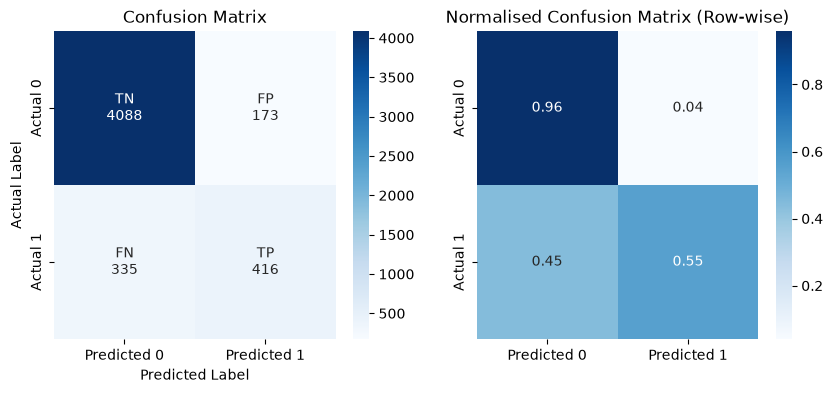

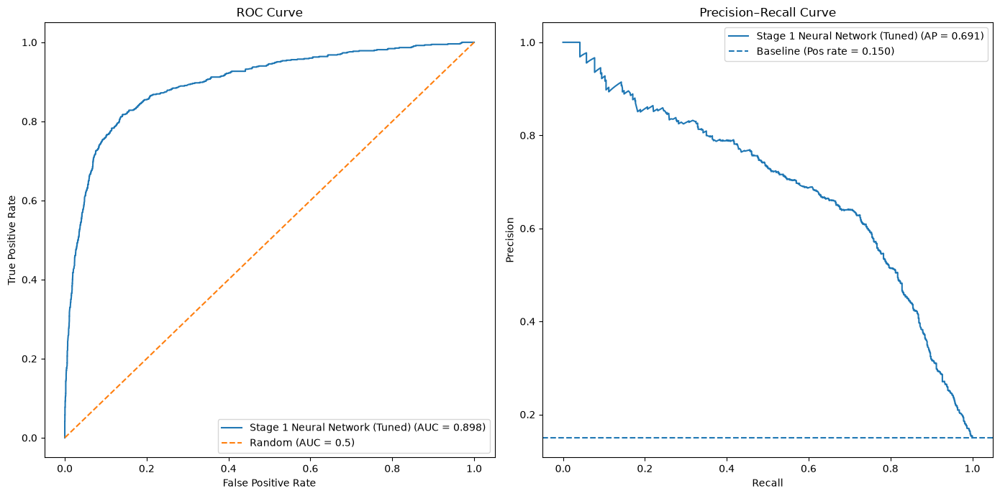

### Untuned vs Tuned Comparison

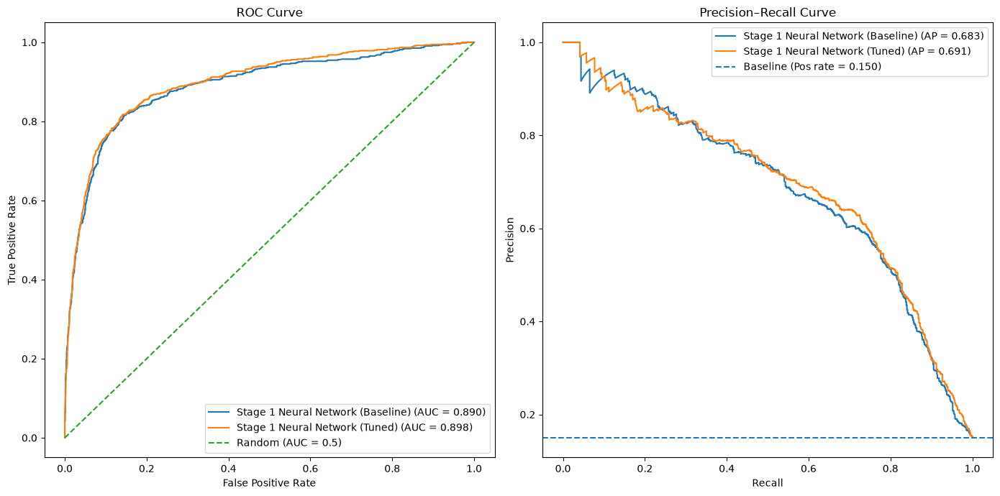

**Model Comparison (with / without Hyperparameter Tuning)**

---

The tuned neural network performs very similarly to the baseline model, with only small differences across evaluation metrics.

| Metric      | Baseline | Tuned |
|-----------|----------|--------|
| Accuracy    | 0.8951 | **0.8986** |
| Precision   | 0.6692 | **0.7063** |
| Recall      | **0.5925** | 0.5539 |
| Specificity | 0.9484 | **0.9594** |
| AUC         | 0.8899 | **0.8979** |

Hyperparameter tuning results in only a minor change in overall model performance. Validation AUC during tuning was approximately 0.88–0.89, and the final test AUC values are very similar, indicating that the tuned model generalises well but does provide a small improvement over the baseline on AUC, accuracy, precision, and specificity.

The ROC curves for the baseline and tuned models almost overlap, showing that tuning does not materially change the model’s ability to separate dropout and completion cases. The Precision–Recall curve shows only a small difference between the two models.

The tuned model increases precision and specificity, meaning fewer false positives, but this comes at the cost of a small reduction in recall, with slightly fewer dropout cases correctly identified. This indicates that the tuned model makes more conservative predictions while maintaining similar overall discrimination.

Overall, hyperparameter tuning results in only a marginal change in performance for the Stage 1 neural network.

---



In [2]:
_run_stage('01_stage_1_data_and_modelling.ipynb')


/home/alexd/miniforge3/envs/student-dropout/lib/python3.12/site-packages/nbformat/validator.py:434: MissingIDFieldWarning: Cell is missing an id field, this will become a hard error in future nbformat versions. You may want to use `normalize()` on your notebooks before validations (available since nbformat 5.1.4). Previous versions of nbformat are fixing this issue transparently, and will stop doing so in the future.
  _validate(nbdict, ref, version, version_minor, relax_add_props)


# Student Dropout Prediction - Stage 2


## Colab / Local Setup

Local execution still works from the cloned repo in VS Code / WSL.

In Google Colab, start each new runtime by cloning the repo, optionally enabling Google Drive-backed artifacts, and then running the setup cell below.

```bash
!git clone <repo-url> /content/student-dropout-prediction
%cd /content/student-dropout-prediction
!pip install -r requirements.txt
```

Set `USE_GOOGLE_DRIVE_ARTIFACTS = True` in the setup cell if you want models, tuning outputs, reports, and demo artifacts to persist across Colab sessions.


Running in Colab: False
Artifact mode: local_repo
Project root: /home/alexd/projects/student-dropout-prediction/student-dropout-prediction
Working directory: /home/alexd/projects/student-dropout-prediction/student-dropout-prediction/notebooks
Loaded Stage 2 public dataset from /home/alexd/projects/student-dropout-prediction/student-dropout-prediction/data/processed/Stage_2_public.csv; cache writes disabled.


**Stage 2: Pre-processing instructions**

- Remove any columns not useful in the analysis (LearnerCode).
- Remove columns with categorical features with high cardinality (use >200 unique values, as a guideline for this data set).
- Remove columns with >50% data missing.
- Perform ordinal encoding for ordinal data.
- Perform one-hot encoding for all other categorical data.
- Choose how to engage with missing values, which can be done in one of two ways for this project:
  *   Impute the rows with appropriate values.
  *   Remove rows with missing values but ONLY in cases where rows with missing values are minimal: <2% of the overall data.



,CentreName,LearnerCode,BookingType,LeadSource,DiscountType,Gender,Age,Nationality,CourseLevel,academic_stage,subject_cluster,delivery_variant,IsFirstIntake,CompletedCourse,dropout,progression_degree_level,ProgressionUniversity,AuthorisedAbsenceCount,UnauthorisedAbsenceCount
0,UK_SCOT_02,5471702600,Agent,Standard Agent Booking,NaN,Male,27,Chinese,Pre-Masters,Pre Masters,Business_Law_Combined,standard,True,Yes,0,MSc,UK_SCOT_02,NaN,NaN
1,UK_SCOT_02,5798287286,Agent,Standard Agent Booking,NaN,Male,27,Chinese,Foundation,UG Foundation Programme,Science_Health,standard,False,Yes,0,BSc,UK_SCOT_02,93.0,5.0
2,UK_SCOT_02,5073159875,Agent,Standard Agent Booking,NaN,Male,25,Chinese,International Year Two,International Year Two,Business_Economics_Finance,standard,False,Yes,0,MA,UK_SCOT_02,92.0,6.0
3,UK_SCOT_02,9006902202,Agent,Standard Agent Booking,NaN,Male,26,Chinese,International Year Two,International Year Two,Business_Economics_Finance,standard,True,Yes,0,MA,UK_SCOT_02,67.0,15.0
4,UK_SCOT_02,1792089712,Agent,Standard Agent Booking,NaN,Male,29,Chinese,Pre-Masters,Pre Masters,Business_Law_Combined,standard,True,Yes,0,MSc,UK_SCOT_02,NaN,NaN


## Data Inspection

First we'll review the data and perform any data cleanse or pre-processing.

### Comparison with Stage 1 Data

Stage 2 data is known to be the original Stage 1 dataset with the addition of attendance metrics, including authorised absence and unauthorised absence counts.

EDA and feature engineering have already been completed on stage_1_data, so we will verify the following:

- Columns that do not match those in the Stage 1 dataset
- Any differences in index-aligned rows for the columns common to both datasets

If there are no differences between the original Stage 1 columns and the corresponding columns in Stage 2, then EDA can be focused on the newly added columns only.

Rows that differ: 0
New Columns in Stage 2:
 ['AuthorisedAbsenceCount', 'UnauthorisedAbsenceCount']
<class 'pandas.DataFrame'>
RangeIndex: 25059 entries, 0 to 25058
Data columns (total 2 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   AuthorisedAbsenceCount    24851 non-null  float64
 1   UnauthorisedAbsenceCount  24851 non-null  float64
dtypes: float64(2)
memory usage: 391.7 KB
Datatypes: 
None



There are two new columns: 

- AuthorisedAbsenceCount (float64)
- UnauthorisedAbsenceCount (float64)

All other columns match stage 1 data exactly, therefore we will focus EDA on the two new columns only and then add them to the stage 1 data post encoding if they are kept.

### Data Quality Checks

We will perform basic data quality checks, view the dataframe metadata to determine assigned datatypes, and determine the size of the dataset.

Data quality checks (numeric fields):

- Missing data checks
- Count of unique values
- Count of null rows



Data quality check (1) detect null values in columns:
                          null_count  null_pct
AuthorisedAbsenceCount           208      0.83
UnauthorisedAbsenceCount         208      0.83


Data quality check (2) unique values in each column:
                          distinct_count  distinct_pct
AuthorisedAbsenceCount               190          0.76
UnauthorisedAbsenceCount             258          1.03

Number of rows where both new columns are null: 208 (0.83%)


**Initial data quality checks interpretation**

---

***Data Summary***

- 25059 records
- All columns match the Stage 1 dataset, with the addition of two new columns:
    - AuthorisedAbsenceCount
    - UnauthorisedAbsenceCount                            


***Null values in the fields:***

New fields have 208 (0.83%) null values:

- AuthorisedAbsenceCount
- UnauthorisedAbsenceCount   

These are on the same row, so the values are highly likely represent missing data for the records in question 

***Missing Data***

As these rows represent only 0.83% of the dataset, we could either remove them or impute values.

We may also create a new feature missing_absence_data to flag rows where this information is not available.

We will examine the feature distributions and the relationship between missingness and the target variable before deciding on the appropriate course of action.

--

### Missing Data Analysis

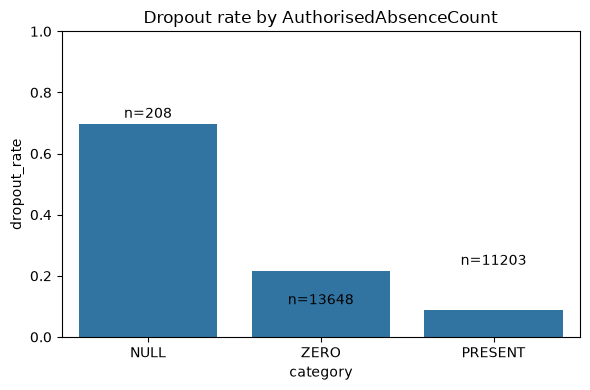

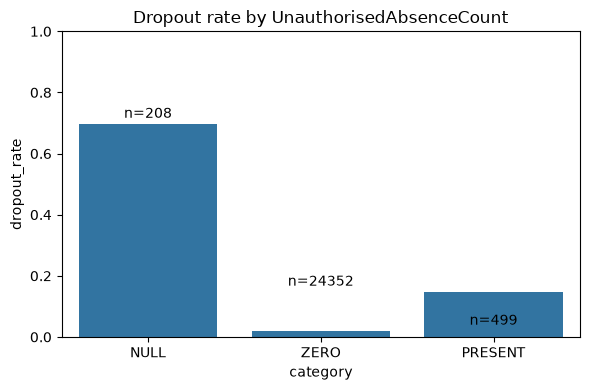


### Exploratory Data Analysis

Generate descriptive statistics and visualise the data to explore patterns, distributions, and trends in the data.

### Descriptive Statistics

We will now generate descriptive statistics (including percentile values for all numeric columns in the dataset), and document any insights this provides about the data.

,count,mean,std,min,5%,25%,50%,75%,95%,max
AuthorisedAbsenceCount,24851.0,15.120639,28.918253,0.0,0.0,0.0,1.0,15.0,76.0,292.0
UnauthorisedAbsenceCount,24851.0,40.491892,39.029384,0.0,2.0,12.0,29.0,56.0,120.0,343.0
dropout,25059.0,0.149806,0.356889,0.0,0.0,0.0,0.0,0.0,1.0,1.0


**Visualise the data**

Visualise the numeric data with box-plots and histograms to further understand the data patterns, distributions, and trends.



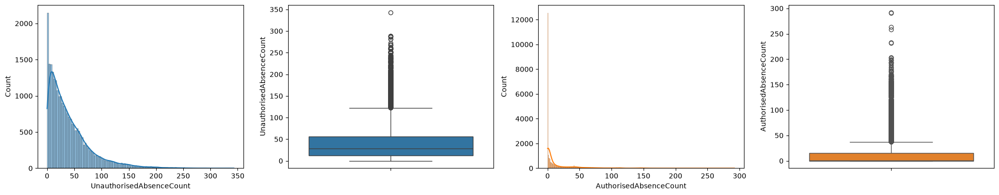

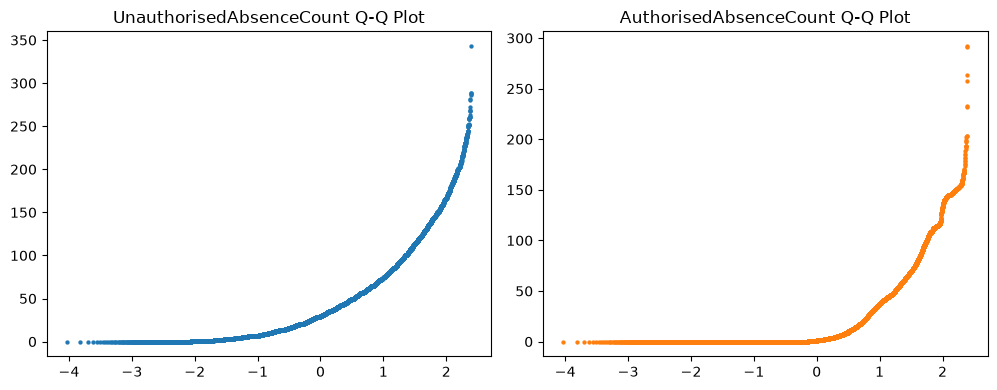

### EDA Review & Feature Engineering Decisions

**AuthorisedAbsenceCount**

- The distribution is highly right-skewed, with a median of 1 absence and 25% of students having no authorised absences.
- The mean (15.1) is substantially higher than the median, indicating the presence of a small number of very large values.
- The 95th percentile is 76, while the maximum reaches 292, suggesting the presence of a long tail of high-absence cases.
    - This may be indicative of disengaged or at-risk students.

**UnauthorisedAbsenceCount**

- Unauthorised absences show a much higher central tendency, with a median of 29 and a mean of 40.5.
- The distribution is again right-skewed, with the 95th percentile at 120 and a maximum of 343.
- Compared to authorised absences, unauthorised absences appear to be more common and more widely spread

The histograms and Q-Q plots confirm the right skew and presence of outliers representing a small number of students with high absence counts.

- Boxplots show many outliers, but these appear to represent genuine observations rather than data errors.
- Q-Q plots confirm that both variables deviate substantially from normality, with heavy positive skew.

Both features indicate that most students have relatively low absence counts, while a small number have very high values.

**Missing Data**

Missing absence counts show a strong association with dropout, indicating that missingness itself carries predictive signal. Records lacking absence data exhibit substantially higher dropout rates.

The rows containing missing absence values should not be removed and an imputation strategy will be implemented which:

- Ensures nulls are replaced by an appropriate value to permit model training and evaluation
- Encodes the missingness 

Absence counts exhibit right-skewed distributions, but values are not so extreme as to mandate transformation. For simplicity, no transformation will be applied, and features will be standardised prior to neural network training.

## Pre-Processing

### Imputation

To preserve the missing value signal we will add a single feature absence_values_missing. This will be set based on the AuthorisedAbsenceCount / UnauthorisedAbsenceCount values::

- Both values null: 1
- Both values not-null: 0

As both values are either present or missing simultaneously, a single absence_values_missing feature is sufficient.

- A zero placeholder value will be imputed for null values

The resultant feature interpretation is shown below:

| absence_values_missing | AuthorisedAbsenceCount | Meaning   |
| --------------- | ---------- | --------- |
| 0               | 5          | real      |
| 0               | 0          | real zero |
| 1               | 0          | missing   |


### Encoding

***Not required***: The new columns are either already binary encoded (absence_values_missing), or numeric count values; therefore no additional encoding is required.

As we are adding these features to the pre-processed Stage 1 data, the new features can be appended to the Stage 1 data frame saved earlier, after encoding but before scaling.


### Scaling

We could consider using RobustScaler as it is more robust to outliers, however to preserve consistency and comparability between models in the previous stage we will continue to use StandardScaler.

The combined post-encoding Stage 1 data and the new Stage 2 features must be scaled to account for the additional AuthorisedAbsenceCount / UnauthorisedAbsenceCount features prior to neural network training and evaluation.


Stage 2 dataset shape: (25059, 178)


## Train / validation / test split

We will create a train, test, and validation data set. Training set split 80-20, with 10% of the training set used as validation.

As the target is imbalanced we will use stratified split.

We also create scaled versions of the feature matrices for neural network training, as neural networks rely on gradient-based optimisation and are sensitive to differences in feature scale

,Gender,Age,IsFirstIntake,dropout,progression_degree_missing,academic_stage_Foundation Other,academic_stage_Foundation Year,academic_stage_International Foundation Year,academic_stage_International Year One,academic_stage_International Year Two,...,ProgressionUniversity_UK_SCOT_01,ProgressionUniversity_UK_SCOT_02,ProgressionUniversity_UK_SE_01,ProgressionUniversity_UK_SE_02,ProgressionUniversity_UK_SE_03,ProgressionUniversity_UK_WAL_01,ProgressionUniversity_University_Other,UnauthorisedAbsenceCount,AuthorisedAbsenceCount,absence_values_missing
0,0,27,1,0,False,0,0,0,0,0,...,0,1,0,0,0,0,0,0.0,0.0,1
1,0,27,0,0,False,0,0,0,0,0,...,0,1,0,0,0,0,0,5.0,93.0,0
2,0,25,0,0,False,0,0,0,0,1,...,0,1,0,0,0,0,0,6.0,92.0,0
3,0,26,1,0,False,0,0,0,0,1,...,0,1,0,0,0,0,0,15.0,67.0,0
4,0,29,1,0,False,0,0,0,0,0,...,0,1,0,0,0,0,0,0.0,0.0,1


## Stage 2 XGBoost Model

A new XGBoost model will be trained and evaluated on the updated dataset using the best-performing hyperparameters identified during Stage 1. Model performance will then be compared with the Stage 1 results.

A new model is required because the feature set has changed, resulting in different input dimensionality.

Baseline parameters: {'colsample_bytree': 0.9882795058818716, 'gamma': 1.8689967766791105, 'learning_rate': 0.14666797316704522, 'max_depth': 8, 'min_child_weight': 1.1079395093578468, 'reg_alpha': 0.019465311593045143, 'reg_lambda': 0.03081909706850276, 'subsample': 0.8560129261469889}


### Baseline Model

We will now evaluate the model against the test set using the following performance indicators:
 - Accuracy
 - Precision
 - Recall
 - AUC

A confusion matrix, ROC and Precision-Recall Curves will also be plotted.

These will be compared against model performance from the model when used with stage 1 data

### Baseline Performance Metrics

Stage 1 XGBoost - Tuned Performance Metrics:
Accuracy:    0.8990
Precision:   0.6979
Recall:      0.5752
Specificity: 0.9561
AUC:         0.8988

XGBoost Stage 1 (Tuned) Confusion Matrix:


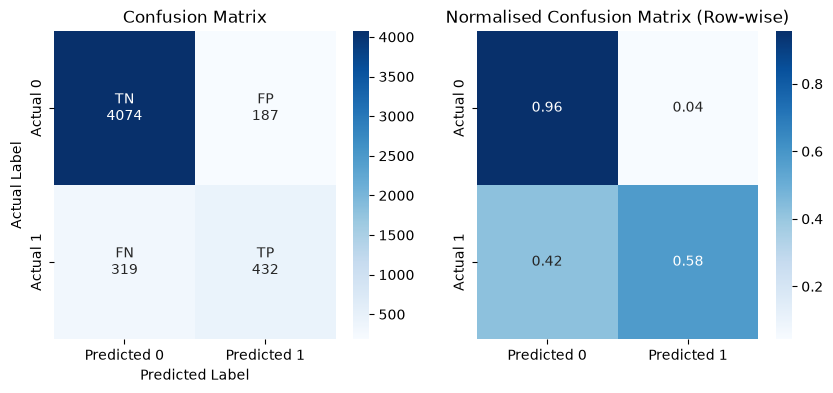

Stage 2 XGBoost - Baseline Performance Metrics:
Accuracy:    0.9162
Precision:   0.7674
Recall:      0.6325
Specificity: 0.9662
AUC:         0.9307

XGBoost Stage 2 (Baseline) Confusion Matrix:


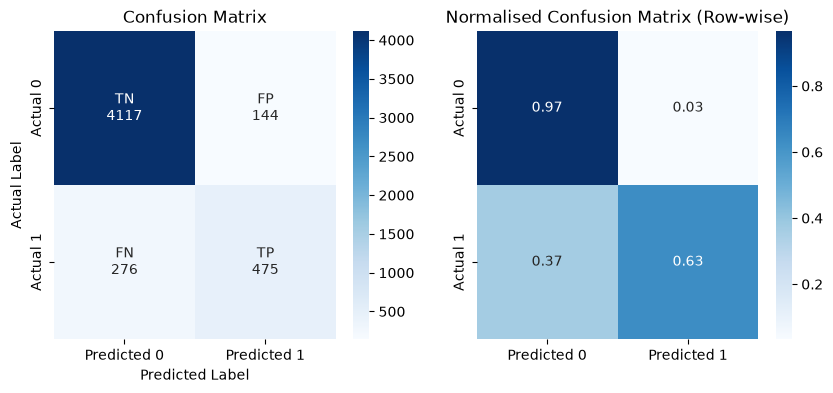

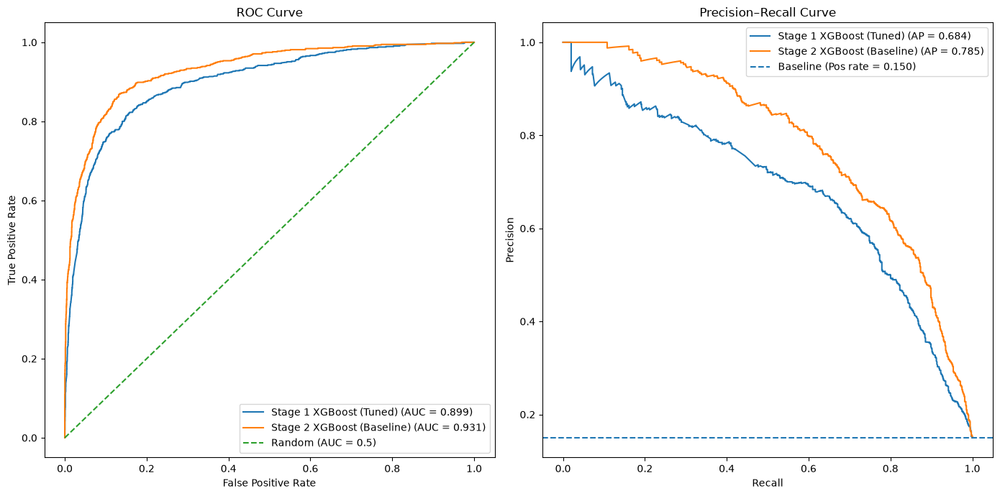


**Comparison - XGBoost Stage 1 Data (Tuned) vs XGBoost Stage 2 Data (Baseline)**

---

AUC increases from 0.8988 to 0.9307, indicating a clear improvement in the model’s ability to separate students who drop out from those who complete across all decision thresholds. This is visible in the ROC curve, where the Stage 2 curve consistently lies above the Stage 1 curve, resulting in a larger area under the curve.


| Metric      | Stage 2 | Stage 1 | Change   | Business Interpretation                                                                                                        |
| ----------- | ------- | ------- | -------- | ------------------------------------------------------------------------------------------------------------------------------ |
| TP          | 475     | 432     | ↑ better | More students who will drop out are correctly identified, improving the ability to target early intervention.                  |
| FN          | 276     | 319     | ↓ better | Fewer at-risk students are missed, reducing the chance of failing to provide support where needed.                             |
| FP          | 144     | 187     | ↓ better | Fewer students who will complete are incorrectly flagged as at risk, reducing unnecessary intervention effort.                 |
| TN          | 4117    | 4074    | ↑ better | More students who will complete are correctly identified, improving overall classification reliability.                        |
| Recall      | 0.6325 | 0.5752 | ↑ better | A higher proportion of actual dropouts are detected, improving the effectiveness of early warning systems.                     |
| Specificity | 0.9662 | 0.9561 | ↑ better | Most students who will complete are correctly recognised, meaning intervention resources remain focused on genuine risk cases. |


The precision–recall curve also shows a clear improvement, demonstrating that the Stage 2 model is able to detect more dropout cases while maintaining strong precision. This indicates that the increase in recall is not achieved at the cost of excessive false positives.

When the Stage 1 tuned model is compared with the Stage 2 baseline model, performance improves across all key metrics. This suggests that the additional Stage 2 features provide meaningful predictive information rather than simply increasing model complexity.

The improvement in performance is consistent with the introduction of the absence-related variables, which are likely to be strong indicators of student disengagement. These features allow the model to identify behavioural patterns associated with dropout, leading to better detection of at-risk students without increasing false alarms.

Overall, the results show that the performance gain between Stage 1 and Stage 2 is primarily driven by the addition of new features rather than changes in model tuning, demonstrating the importance of feature engineering in improving predictive performance.

---

### Hyperparameter Tuning

The search space previously used for the Stage 1 model is summarised below alongside the current Stage 2 baseline, which carries forward Stage 1’s selected final parameters.


| Hyperparameter          |  Search range     |    Baseline | Justification                                                                                          |
| ----------------------- |  ---------------- | ----------: | -------------------------------------------------------------------------------------------------------- |
| learning_rate         |  **0.01 – 0.20**  | 0.1467 | Covers slower and faster boosting updates around the carried-forward learning rate|
| max_depth             |  **3 – 8**        | 8 | Baseline uses depth 8; range explores shallower trees through to baseline depth    |
| min_child_weight      |  **1 – 12**       | 1.1079 | Controls minimum leaf weight; higher values regularise and can improve generalisation.                   |
| gamma                 |  **0 – 5**        | 1.8690 | Penalises splits; encourages simpler trees when >0.                                                      |
| subsample             |  **0.60 – 1.00**  | 0.8560 | Row sampling regularisation; includes baseline and stronger/weaker regularisation.                       |
| colsample_bytree      |  **0.60 – 1.00**  | 0.9883 | Feature sampling regularisation; includes baseline and explores more/less feature subsampling.           |
| reg_alpha             |  **1e-8 – 10**    | 0.0195 | L1 regularisation; small/medium values can help on wide tabular data.                |
| reg_lambda           |  **1e-2 – 50**    | 0.0308 | L2 regularisation; explores both weaker and much stronger penalty.                                       |
| n_estimators          |  **3000 (fixed)** |         100 | Not tuned directly; set high and use early stopping to find effective number of trees.                   |
| early_stopping_rounds |  **30 (fixed)**   |           – | Limits further training when validation AUC stops improving and replaces manual 'n_estimators' tuning.                                          |


If tuning is enabled, Optuna with Bayesian optimisation uses this search space to maintain consistency and comparability with the Stage 1 tuning process. The current final model uses the saved Stage 2 configuration with validation-AUC early stopping; the baseline uses 100 estimators without early stopping.

Rebuilt model validation AUC: 0.9284926686217009
Historical saved tuning AUC: None
Selected parameters: {'colsample_bytree': 0.601, 'reg_lambda': 4.74, 'subsample': 0.754, 'max_depth': 8, 'min_child_weight': 1.15, 'gamma': 0.27, 'learning_rate': 0.119, 'reg_alpha': 0.0052}
No scored Stage 2 XGBoost trial history is available. Saved parameter summaries and rebuilt evaluation metrics are reported separately.


### Tuned Model 

Hyperparameters for the current final model, using the saved Stage 2 configuration, are shown below and compared to the baseline model:

| Hyperparameter       | Stage 2 Baseline (Stage 1 Selected Final) | Stage 2 Final  | Interpretation                                                                            |
| -------------------- | -------------------------------- | -------------- | ----------------------------------------------------------------------------------------- |
| **learning_rate**    | 0.1467 | **0.119**      | Lower learning rate in Stage 2 suggests more gradual boosting with the larger feature set |
| **max_depth**        | 8 | **8**          | Tree depth is unchanged between the baseline and final configurations                 |
| **min_child_weight** | 1.1079 | **1.15**       | Both models allow small leaf weights, enabling fine-grained splits                        |
| **gamma**            | 1.8690 | **0.27**       | Lower gamma indicates less split penalty, suggesting clearer signal in Stage 2 features   |
| **subsample**        | 0.8560 | **0.754**      | More row subsampling in Stage 2 provides stronger regularisation                          |
| **colsample_bytree** | 0.9883 | **0.601**      | Increased feature subsampling helps control overfitting with the wider feature set        |
| **reg_alpha (L1)**   | 0.0195 | **0.0052**     | Stage 2 uses weaker L1 regularisation                                          |
| **reg_lambda (L2)**  | 0.0308 | **4.74**       | Much stronger L2 regularisation, likely due to the increased number of features           |
| **n_estimators**     | 100; no early stopping | Maximum 3,000; early stopping | Final uses validation-AUC early stopping with patience 30; predictions use 79 rounds |


Because Stage 1’s selected final parameters were reused as the baseline for Stage 2, the differences shown above compare that configuration with the saved Stage 2 final configuration. Overall, the changes in hyperparameters are moderate.

### Tuned Model Evaluation

We will now evaluate the model against the same performance parameters used to evaluate the stage 1 model.


Stage 2 XGBoost - Baseline Performance Metrics:
Accuracy:    0.9162
Precision:   0.7674
Recall:      0.6325
Specificity: 0.9662
AUC:         0.9307

Stage 2 XGBoost Baseline Confusion Matrix:


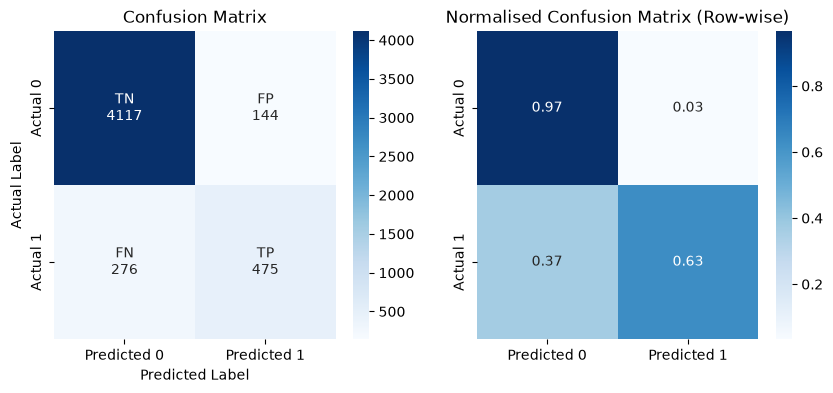

Stage 2 XG Boost - Tuned Performance Metrics:
Accuracy:    0.9142
Precision:   0.7627
Recall:      0.6205
Specificity: 0.9660
AUC:         0.9326

Stage 2 XGBoost Tuned Confusion Matrix:


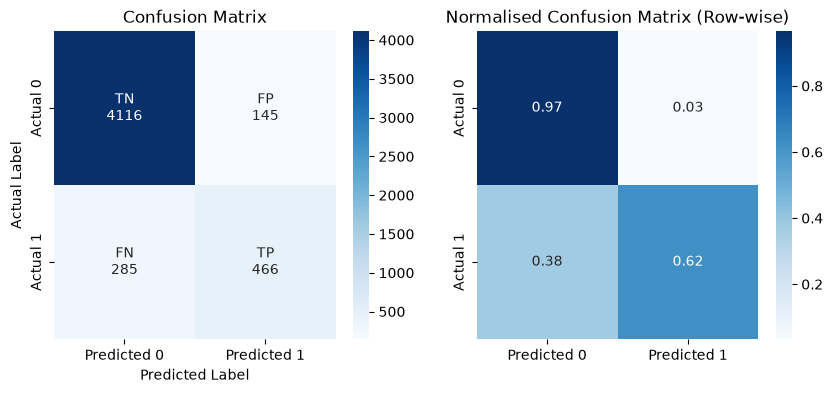

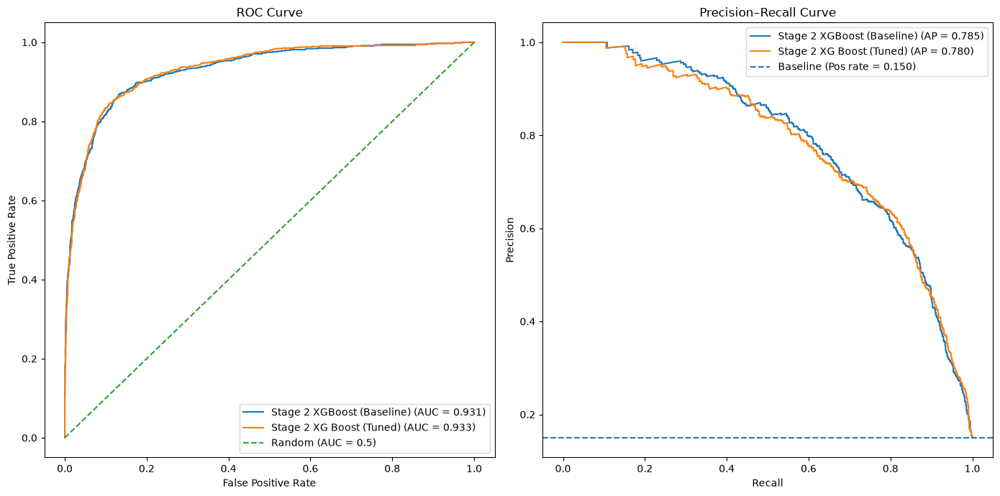

### Stage 2 XGBoost Baseline vs Final Comparison

The Stage 2 tuned XGBoost model performs almost identically to the Stage 2 baseline model, with only very small differences across all evaluation metrics.

| Metric      | Baseline   | Tuned      |
| ----------- | ---------- | ---------- |
| Accuracy    | **0.9162** | 0.9142     |
| Precision   | **0.7674** | 0.7627     |
| Recall      | **0.6325** | 0.6205     |
| Specificity | **0.9662** | 0.9660     |
| AUC         | 0.9307     | **0.9326** |


The saved Stage 2 configuration produces only a small increase in test AUC, from 0.9307 to 0.9326, compared with the baseline carrying forward the selected Stage 1 configuration. Accuracy, precision and recall decrease slightly, while specificity remains almost unchanged.

The ROC and Precision–Recall curves for the baseline and tuned models are nearly indistinguishable, with the tuned model lying only slightly above the baseline across some thresholds. This confirms that tuning does not materially change the model’s classification behaviour.

Recall decreases slightly, while specificity remains almost unchanged. These small differences accompany the marginal decrease in accuracy and precision despite the very small increase in AUC.

Overall, these results indicate that the main performance improvement observed in Stage 2 comes from the addition of new features rather than from further hyperparameter tuning. The Stage 1 tuned configuration already provided a strong starting point, and retuning on the expanded dataset yields only minimal gains.

### Feature Importance

We will now review feature importance with the addition of the new features.

Both feature importance and SHAP plots will be created so that we can compare how well they align and use SHAP to better understand magnitude and direction of feature influence.


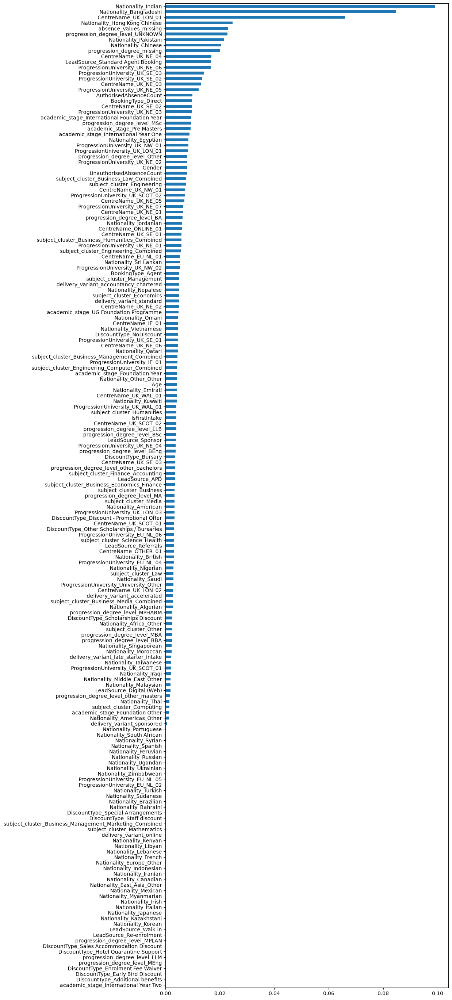

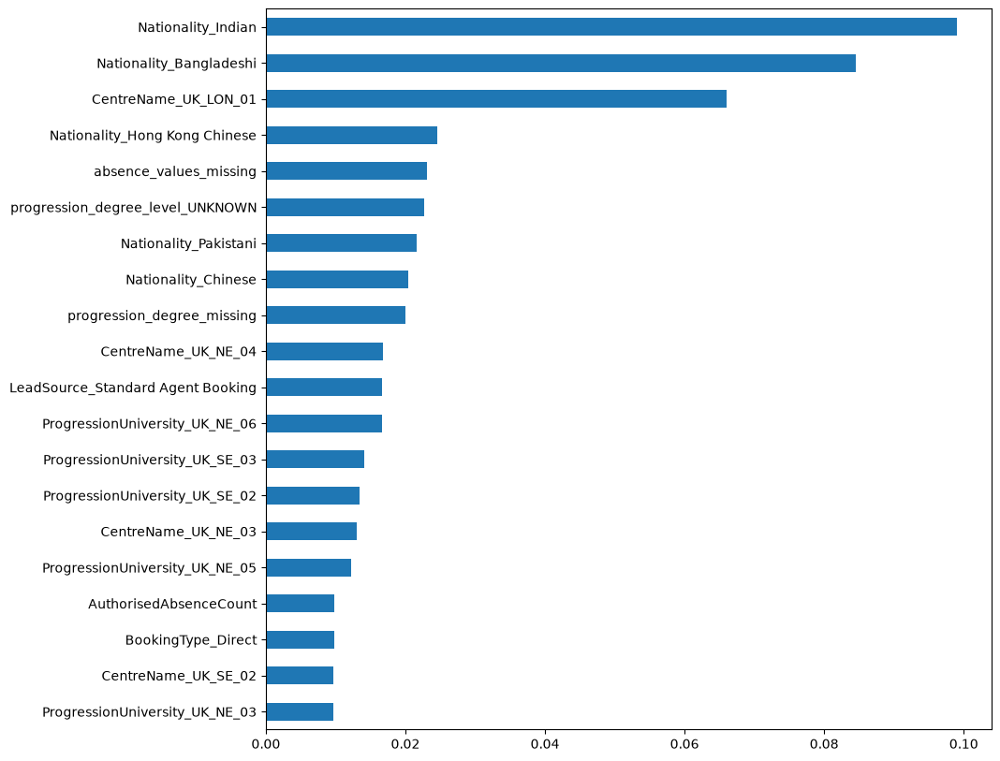

/tmp/ipykernel_214481/2892323881.py:14: Pandas4Warning: The copy keyword is deprecated and will be removed in a future version. Copy-on-Write is active in pandas since 3.0 which utilizes a lazy copy mechanism that defers copies until necessary. Use .copy() to make an eager copy if necessary.
  X_test_plot = X_test.astype(float, copy=True)


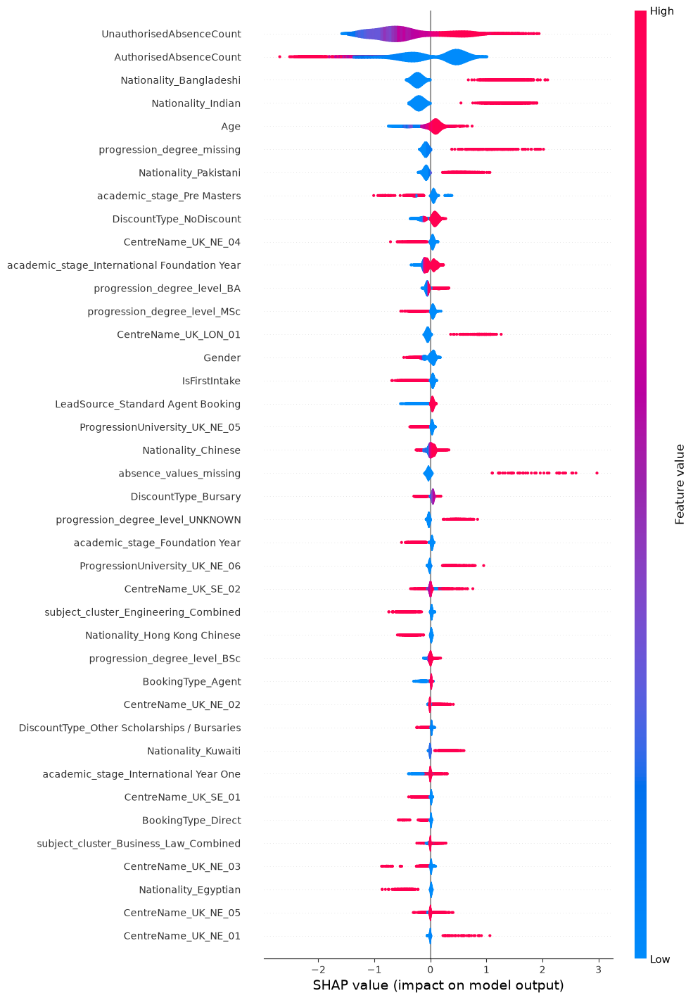

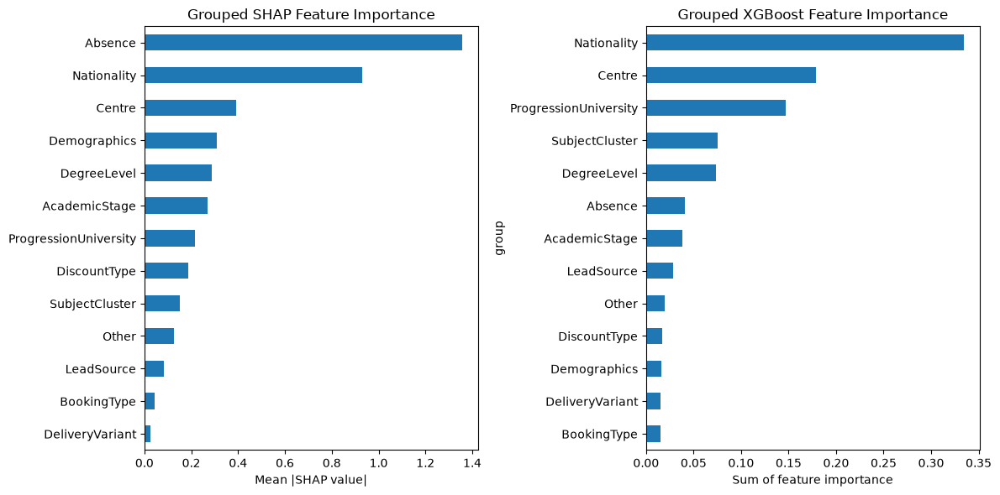

**Interpretation**

SHAP importance indicates that absence-related features provide the strongest contribution to model predictions. This suggests that attendance behaviour is the most informative predictor of dropout, and explains the significant improvement in model performance following the addition of these features.



## Stage 2 Neural Network Model

A new Neural Network model will be trained and evaluated on the updated dataset using the best-performing hyperparameters identified during Stage 1. Model performance will then be compared with the Stage 1 results.

A new model is required because the feature set has changed, resulting in different input dimensionality.

Stage 2 formerly read Stage 1 refined best_params.json (48 units, 1 layer). This rebuilt baseline uses Stage 1 selected final stability configuration 1 (240 units, 3 ReLU layers), checked against initial_best_params.json.
Baseline parameters: {'units': 240, 'layers': 3, 'activation': 'relu', 'optimizer': 'adam', 'lr': 0.0003, 'dropout': 0.3, 'l2_strength': 0.0001}


### Baseline Model

We will now evaluate the model against the test set using the following performance indicators:
 - Accuracy
 - Precision
 - Recall
 - AUC

A confusion matrix, ROC and Precision-Recall Curves will also be plotted.

These will be compared against model performance from the model when used with stage 1 data.

### Baseline Performance Metrics

Stage 1 Neural Network - Tuned Performance Metrics:
Accuracy:    0.8986
Precision:   0.7063
Recall:      0.5539
Specificity: 0.9594
AUC:         0.8978

Stage 1 Neural Network Tuned Confusion Matrix:


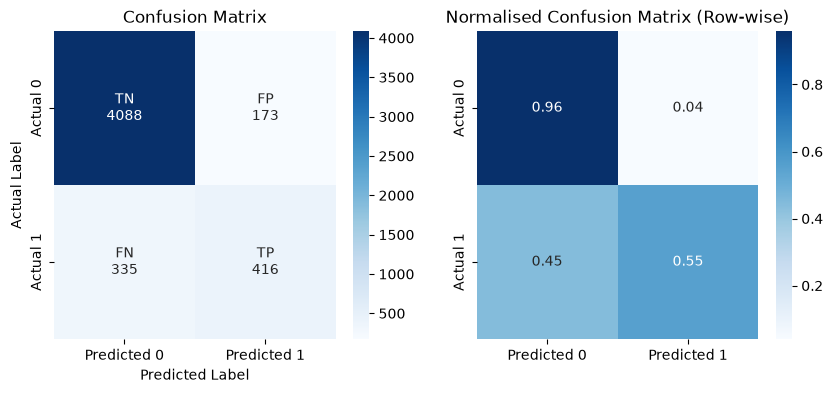

Stage 2 Neural Network - Baseline Performance Metrics:
Accuracy:    0.9084
Precision:   0.7378
Recall:      0.6032
Specificity: 0.9622
AUC:         0.9187

Stage 2 Neural Network Baseline Confusion Matrix:


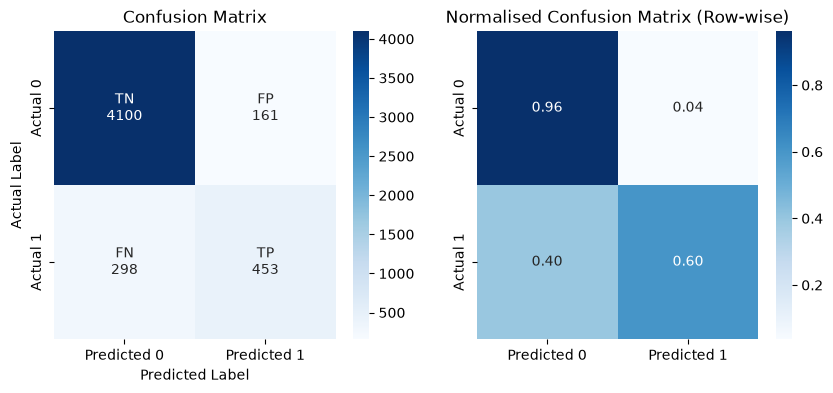

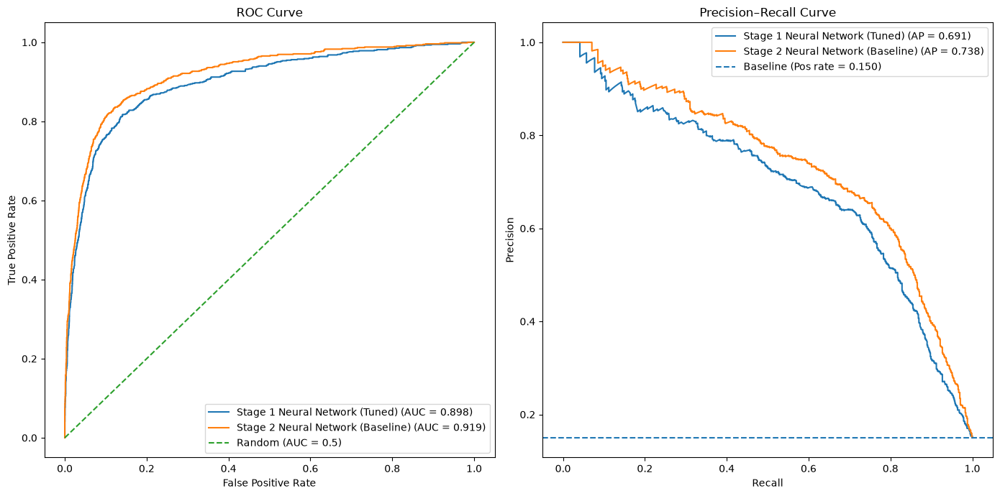

**Comparison of Neural Network Stage 1 (Tuned) vs Neural Network Stage 2 (Baseline)**

---

AUC increases from 0.8979 to 0.9187, indicating improved ability of the model to separate students who drop out from those who complete across all decision thresholds. This is reflected in the ROC curve, where the Stage 2 curve lies consistently above the Stage 1 curve, resulting in a larger area under the curve and improved overall discrimination.

| Metric      | Stage 2 | Stage 1 | Change     | Business Interpretation                                                                                                        |
| ----------- | ------- | ------- | ---------- | ------------------------------------------------------------------------------------------------------------------------------ |
| TP          | 453     | 416     | ↑ better   | More students who will drop out are correctly identified, improving the ability to target early intervention.                  |
| FN          | 298     | 335     | ↓ better   | Fewer at-risk students are missed, reducing the chance of failing to provide support where needed.                             |
| FP          | 161     | 173     | ↓ better   | Fewer students who will complete are incorrectly flagged as at risk, reducing unnecessary intervention effort.                 |
| TN          | 4100    | 4088    | ↑ better   | More students who will complete are correctly identified, improving overall classification reliability.                        |
| Recall      | 0.6032 | 0.5539 | ↑ better   | A higher proportion of actual dropouts are detected, improving the effectiveness of early warning systems.                     |
| Specificity | 0.9622 | 0.9594 | ↑ slightly | Most students who will complete are correctly recognised, meaning intervention resources remain focused on genuine risk cases. |


The precision–recall curve also shows an improvement, indicating that the model is able to identify more dropout cases while maintaining strong precision. This suggests that the increase in recall is not achieved at the cost of excessive false positives, which is important in an intervention setting where unnecessary alerts may increase workload.

As with the XGBoost model, retraining the Stage 1 tuned architecture on the Stage 2 dataset leads to improved performance. This indicates that the additional Stage 2 features provide useful predictive signal rather than simply increasing model complexity.

The magnitude of the improvement is slightly smaller than that observed for XGBoost, but the direction of change is consistent, confirming that the performance gain is primarily driven by the additional Stage 2 features rather than changes to the neural network architecture.

---


### Hyperparameter Tuning

Saved tuning artefacts are loaded by default so this notebook can be rerun quickly. Stage 2 neural-network tuning is computationally expensive, so `RUN_NN_TUNING` is set to `False` by default. Set it to `True` only if you want to rerun the RandomSearch workflow and refresh the saved files under `tuning/stage_2/neural_network/`.

Since the Stage 2 dataset introduces additional predictive features but does not fundamentally change the neural-network modelling framework, hyperparameter tuning remains focused on the refined search space identified during Stage 1.


NN hyperparameter surrogate fitting is disabled.


The historical surrogate-analysis summary reports that learning rate, L2 regularisation strength, and network size (units and layers) have the strongest influence on model performance, with dropout having a smaller but still noticeable effect. Activation function and optimiser choice have comparatively little impact.

The underlying trial-level evidence is unavailable, so these findings describe the historical surrogate analysis rather than the current model evaluations. The reported direction and relative importance of these effects are consistent with the earlier tuning stage and motivated retaining the refined hyperparameter search space.

NN tuning is disabled; reading saved evidence only.
No genuine completed Stage 2 refined-search trial history is available. The saved parameter summary is reported separately.
{'best_val_auc': 0.9091, 'best_params': {'units': 160, 'layers': 3, 'activation': 'relu', 'optimizer': 'adam', 'lr': 0.001, 'dropout': 0.3, 'l2_strength': 0.0}}


**Refined Hyperparameter Tuning Results**

The historical search summary reports validation AUC increasing from approximately 0.9101 to 0.9171. The strongest configurations fall within a relatively narrow performance band of approximately 0.914–0.917.

The underlying trial-level evidence is unavailable; these recorded validation values are historical summaries, not current model evaluations. They do not establish an improvement on the test set, where the current final model performs very similarly to the baseline.

**Top 5 Neural Network Models – Evaluation**

Small differences in validation AUC may reflect stochastic training variation rather than increased model performance. As in Stage 1, the historical summary describes the following approach to evaluating model performance and stability:

***Select the top 5 configurations and retrain each:***

- 3 different random seeds + original SEED value to validate repeatability
- batch size = 64
- same early stopping criteria
- same train/validation split

The proposed measures were:

- mean validation AUC
- standard deviation

This may provide a more robust estimate of model performance and identify architectures that are both high performing and stable across training runs.

Top performing hyperparameter combinations from both searches:


,trial_id,status,val_auc,units,layers,activation,optimizer,lr,dropout,l2_strength


No verified Stage 2 stability history; no retraining or replacement rows generated.
Final fixed model: documented Stage 2 NN configuration 3.


### Tuned Model

The historical stability summary for the Stage 2 neural network records the following results. The underlying seed-level evidence is unavailable, and these values are distinct from the current model evaluations:

| Model        | Units | Layers | Activation | Optimizer | LR    | Dropout | L2   | Mean Val AUC | Std    |
|------------|-------|--------|------------|-----------|-------|---------|------|-------------|--------|
| Config_idx 3 | 160 | 3 | relu | adam | 0.001 | 0.3 | 0.0 | **0.9091** | **0.0006** |
| Config_idx 1 | 48  | 1 | tanh | adam | 0.001 | 0.2 | 0.0 | 0.9087 | 0.0059 |
| Config_idx 4 | 128 | 2 | relu | adam | 0.001 | 0.4 | 0.0 | 0.9062 | 0.0016 |
| Config_idx 2 | 176 | 3 | relu | adam | 0.0003 | 0.4 | 1e-4 | 0.9017 | 0.0008 |
| Config_idx 5 | 96  | 4 | relu | adam | 0.0003 | 0.3 | 0.0 | 0.8997 | 0.0009 |

Within this summary, the configuration with 160 units and 3 hidden layers has the highest recorded mean validation AUC and lowest recorded standard deviation. The current final Stage 2 model follows this documented configuration.

Both the selected Stage 1 and Stage 2 architectures use three ReLU hidden layers. The Stage 2 configuration reduces the number of units per layer from 240 to 160 and increases the learning rate from 0.0003 to 0.001. Dropout remains at 0.3, while L2 regularisation is removed.

Therefore, the final chosen model parameters are:

| Model | Units | Layers | Activation | Optimizer | LR | Dropout | L2 |
|-------|--------|--------|------------|-----------|------|---------|------|
| Final Stage 2 NN | 160 | 3 | relu | adam | 0.001 | 0.3 | 0.0 |


### Tuned Model Evaluation

**Performance Metrics**

We will now evaluate the model against the same performance parameters used to evaluate the stage 1 model.





Final parameters: {'units': 160, 'layers': 3, 'activation': 'relu', 'optimizer': 'adam', 'lr': 0.001, 'dropout': 0.3, 'l2_strength': 0.0}
Rebuilt validation metrics: {'accuracy': 0.9132169576059851, 'precision': 0.771551724137931, 'recall': 0.5966666666666667, 'specificity': 0.9689149560117302, 'auc': 0.9130048875855327}
Historical evidence: {'interpretation': 'Other historical training runs; not new evaluation metrics.', 'stability_mean_val_auc': 0.9091, 'stability_std_val_auc': 0.0006, 'raw_stability_row': ['Config_idx 3', '160', '3', 'relu', 'adam', '0.001', '0.3', '0.0', '0.9091', '0.0006'], 'raw_test_rows': {'accuracy': [['Accuracy', '0.9074', '0.9094']], 'precision': [['Precision', '0.7396', '0.7583']], 'recall': [['Recall', '0.5899', '0.5806']], 'specificity': [['Specificity', '0.9634', '0.9674']], 'auc': [['AUC', '0.9118', '0.9220']]}, 'stability_source_cell_id': 'b6b68dde', 'test_metrics': {'accuracy': 0.9094, 'precision': 0.7583, 'recall': 0.5806, 'specificity': 0.9674, 'auc'

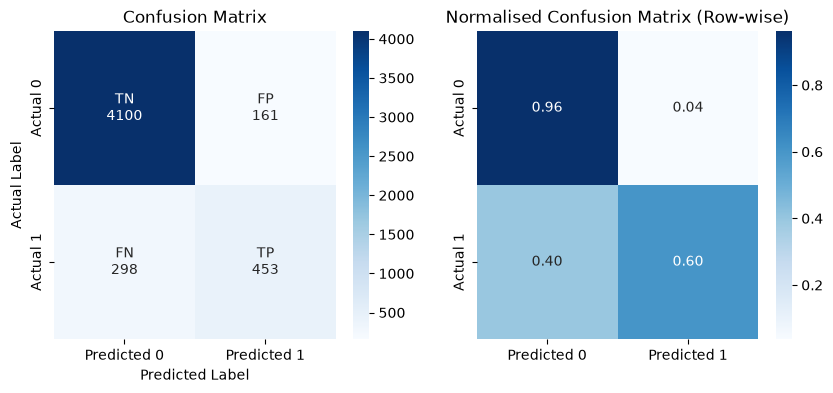

Stage 2 Neural Network - Tuned Performance Metrics:
Accuracy:    0.9076
Precision:   0.7345
Recall:      0.6005
Specificity: 0.9617
AUC:         0.9183

Stage 2 Neural Network Tuned Confusion Matrix:


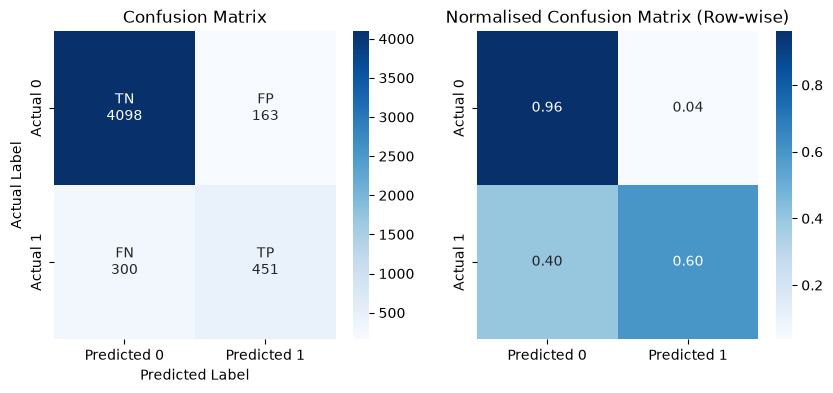

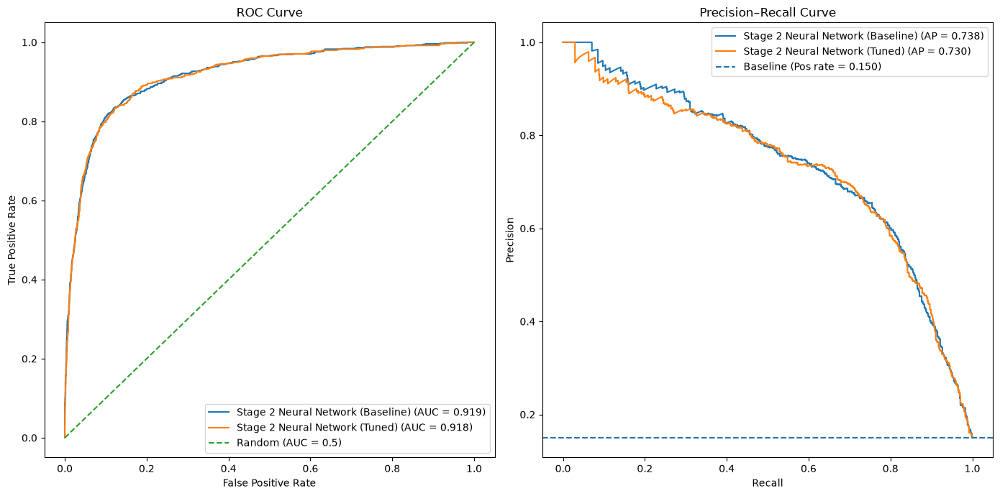

### Stage 2 Neural Network Baseline vs Final Comparison

The baseline and final Stage 2 neural networks achieve very similar performance on the test set. The baseline is marginally stronger across all five metrics, although the differences are small.

| Metric | Baseline | Final |
|---|---:|---:|
| Accuracy | 0.9084 | 0.9076 |
| Precision | 0.7378 | 0.7345 |
| Recall | 0.6032 | 0.6005 |
| Specificity | 0.9622 | 0.9617 |
| AUC | 0.9187 | 0.9182 |


The final configuration does not improve the balance between identifying dropout cases and avoiding false positives at the 0.5 classification threshold. Precision, recall and specificity all decrease slightly, while AUC remains almost unchanged.

These results provide no evidence of a meaningful performance improvement from the Stage 2 configuration over the baseline. Both configurations benefit from the additional absence-related features, with the improvement over Stage 1 much larger than the difference between the two Stage 2 models.

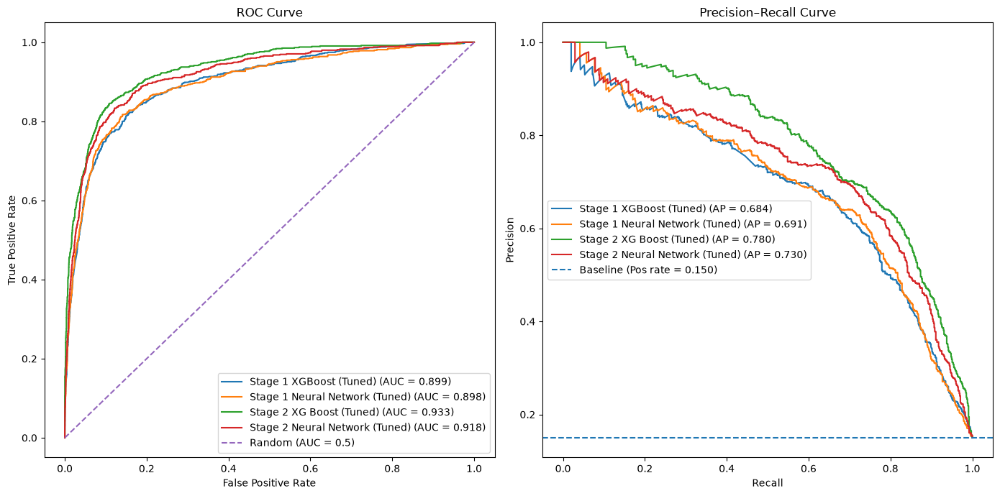

## Stage 2 Model Comparison

### Performance Metrics Comparison (Stage 1 vs Stage 2)

| Model | Dataset | Accuracy | Precision | Recall | Specificity | AUC |
|---|---|---:|---:|---:|---:|---:|
| XGBoost | Stage 1 | 0.8990 | 0.6979 | 0.5752 | 0.9561 | 0.8988 |
| XGBoost | Stage 2 | 0.9142 | 0.7627 | 0.6205 | 0.9660 | 0.9326 |
| Neural Network | Stage 1 | 0.8986 | 0.7063 | 0.5539 | 0.9594 | 0.8978 |
| Neural Network | Stage 2 | 0.9076 | 0.7345 | 0.6005 | 0.9617 | 0.9182 |


**Interpretation**

---

The table compares the selected final models from each stage, so both the feature sets and model configurations differ. The earlier baseline comparisons carry forward the Stage 1 hyperparameters to examine the effect of adding the Stage 2 features.

Both XGBoost and the neural network show clear performance improvements when trained on the Stage 2 dataset, with higher AUC, recall, and precision compared with Stage 1. This indicates that the additional Stage 2 variables provide useful predictive information. In particular, the absence-related features appear to be strong indicators of lower student engagement, improving the models’ ability to identify dropout cases while maintaining high specificity.

Across both stages, XGBoost achieves the highest overall performance, with the strongest AUC and recall on the Stage 2 dataset. This suggests that the tree-based model is better able to exploit the additional features introduced in Stage 2. The neural network also benefits from the richer dataset, but the improvement is smaller.

Overall, the improvement from Stage 1 to Stage 2 is primarily driven by the addition of new predictive features rather than changes to model structure. The results also show that XGBoost provides slightly better generalisation performance than the neural network for this dataset, making it the strongest candidate for the final model.

---


### Effect of Stage 2 Hyperparameter Tuning

The Stage 2 baseline models carry forward the selected Stage 1 hyperparameters. Comparing these with the final Stage 2 configurations shows whether further optimisation provides additional benefit.

For XGBoost, the final configuration produces a small increase in test AUC, from 0.9307 to 0.9326. At the 0.5 classification threshold, however, accuracy, precision and recall decrease slightly, while specificity remains almost unchanged. The higher AUC therefore does not translate into improved classification at this threshold.

For the neural network, the final configuration performs marginally below the baseline across all five metrics. Test AUC changes from 0.9187 to 0.9182, providing no evidence of a meaningful improvement.

Overall, the main performance gain in Stage 2 comes from the additional absence-related features. Further hyperparameter optimisation provides little practical benefit in these evaluations.

In [3]:
_run_stage('02_stage_2_data_and_modelling.ipynb')


/home/alexd/miniforge3/envs/student-dropout/lib/python3.12/site-packages/nbformat/validator.py:434: MissingIDFieldWarning: Cell is missing an id field, this will become a hard error in future nbformat versions. You may want to use `normalize()` on your notebooks before validations (available since nbformat 5.1.4). Previous versions of nbformat are fixing this issue transparently, and will stop doing so in the future.
  _validate(nbdict, ref, version, version_minor, relax_add_props)


# Student Dropout Prediction - Stage 3


## Colab / Local Setup

Local execution still works from the cloned repo in VS Code / WSL.

In Google Colab, start each new runtime by cloning the repo, optionally enabling Google Drive-backed artifacts, and then running the setup cell below.

```bash
!git clone <repo-url> /content/student-dropout-prediction
%cd /content/student-dropout-prediction
!pip install -r requirements.txt
```

Set `USE_GOOGLE_DRIVE_ARTIFACTS = True` in the setup cell if you want models, tuning outputs, reports, and demo artifacts to persist across Colab sessions.


Running in Colab: False
Artifact mode: local_repo
Project root: /home/alexd/projects/student-dropout-prediction/student-dropout-prediction
Working directory: /home/alexd/projects/student-dropout-prediction/student-dropout-prediction/notebooks
Loaded Stage 3 public dataset from /home/alexd/projects/student-dropout-prediction/student-dropout-prediction/data/processed/Stage_3_public.csv; cache writes disabled.


**Stage 3: Pre-processing instructions**

- Remove any columns not useful in the analysis (LearnerCode).
- Remove columns with categorical features with high cardinality (use >200 unique values, as a guideline for this data set).
- Remove columns with >50% data missing.
- Perform ordinal encoding for ordinal data.
- Perform one-hot encoding for all other categorical data.
- Choose how to engage with rows that have missing values, which can be done in one of two ways for this project:
  *   Impute the rows with appropriate values.
  *   Remove rows with missing values but ONLY in cases where rows with missing values are minimal: <2% of the overall data.






,CentreName,LearnerCode,BookingType,LeadSource,DiscountType,Gender,Age,Nationality,CourseLevel,academic_stage,...,IsFirstIntake,CompletedCourse,dropout,progression_degree_level,ProgressionUniversity,AuthorisedAbsenceCount,UnauthorisedAbsenceCount,AssessedModules,FailedModules,PassedModules
0,UK_SCOT_02,5471702600,Agent,Standard Agent Booking,NaN,Male,27,Chinese,Pre-Masters,Pre Masters,...,True,Yes,0,MSc,UK_SCOT_02,NaN,NaN,4.0,0.0,4.0
1,UK_SCOT_02,5798287286,Agent,Standard Agent Booking,NaN,Male,27,Chinese,Foundation,UG Foundation Programme,...,False,Yes,0,BSc,UK_SCOT_02,93.0,5.0,7.0,0.0,7.0
2,UK_SCOT_02,5073159875,Agent,Standard Agent Booking,NaN,Male,25,Chinese,International Year Two,International Year Two,...,False,Yes,0,MA,UK_SCOT_02,92.0,6.0,8.0,0.0,8.0
3,UK_SCOT_02,9006902202,Agent,Standard Agent Booking,NaN,Male,26,Chinese,International Year Two,International Year Two,...,True,Yes,0,MA,UK_SCOT_02,67.0,15.0,8.0,0.0,8.0
4,UK_SCOT_02,1792089712,Agent,Standard Agent Booking,NaN,Male,29,Chinese,Pre-Masters,Pre Masters,...,True,Yes,0,MSc,UK_SCOT_02,NaN,NaN,4.0,0.0,4.0


## Data Inspection

First we'll review the data and perform any data cleanse or pre-processing.

### Comparison with Stage 2 Data

Stage 3 data is known to be the original Stage 2 dataset with the addition of attendance metrics, academic metrics, including passed and failed modules.

EDA and feature engineering have already been completed on stage_1_data, and stage_2_data so we will verify the following:

- Columns that do not match those in the Stage 2 dataset
- Any differences in index-aligned rows for the columns common to both datasets

If there are no differences between the original Stage 2 columns and the corresponding columns in Stage 3, then EDA can be focused on the newly added columns only.

Rows that differ: 0
New Columns in Stage 3:
 ['AssessedModules', 'FailedModules', 'PassedModules']
<class 'pandas.DataFrame'>
RangeIndex: 25059 entries, 0 to 25058
Data columns (total 3 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   AssessedModules  22828 non-null  float64
 1   FailedModules    22828 non-null  float64
 2   PassedModules    22828 non-null  float64
dtypes: float64(3)
memory usage: 587.4 KB
Datatypes: 
None



There are three new columns: 

- AssessedModules (float64)
- FailedModules   (float64)
- PassedModules   (float64)

All other columns match stage 2 data exactly, therefore we will focus EDA on the two new columns only and then add them to the stage 2 data post encoding if they are kept.

### Data Quality Checks

We will perform basic data quality checks, view the dataframe metadata to determine assigned datatypes, and determine the size of the dataset.

Data quality checks (numeric fields):

- Missing data checks
- Count of unique values
- Count of null rows


Data quality check (1) detect null values in columns:
                 null_count  null_pct
AssessedModules        2231       8.9
FailedModules          2231       8.9
PassedModules          2231       8.9


Data quality check (2) unique values in each column:
                 distinct_count  distinct_pct
FailedModules                11          0.04
AssessedModules              12          0.05
PassedModules                12          0.05

Number of rows where all new columns are null: 2231 (8.90%)



**Initial Data Quality Check**

---

**Data summary**

- 25,059 records
- All columns from Stage 2 are present, with three additional fields:
  - `AssessedModules`
  - `FailedModules`
  - `PassedModules`

**Null values in the new fields**

All three new assessment fields have 2,231 null values (8.9% of the dataset), and the nulls occur on the same rows. This strongly suggests missing assessment data rather than true zero values.

**Missing-data approach**

Because these rows represent a relatively small share of the dataset, we will test simple imputation and preserve the missingness signal explicitly through a dedicated indicator feature.

We will examine the feature distributions and the relationship between missingness and the target variable before finalising the preprocessing approach.

---

### Missing Data Analysis


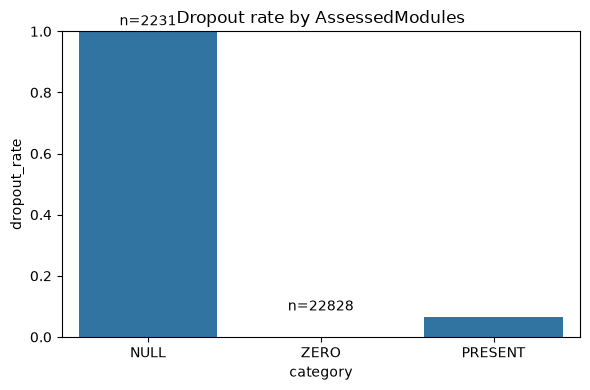

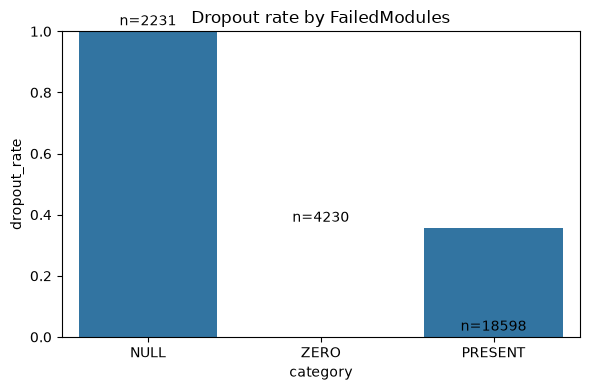

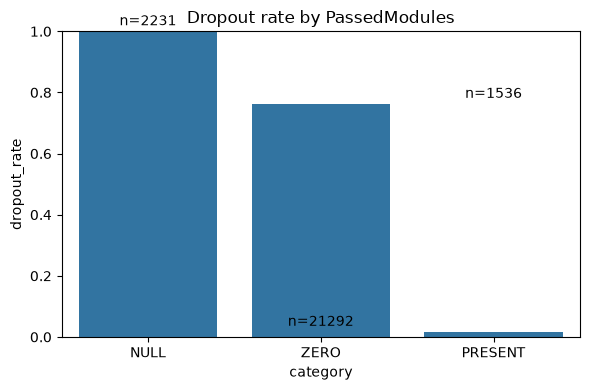

### Exploratory Data Analysis

Generate descriptive statistics and visualise the data to explore patterns, distributions, and trends in the data.

**Descriptive Statistics**

We will now generate descriptive statistics (including percentile values for all numeric columns in the dataset), and document any insights this provides about the data.

,count,mean,std,min,5%,25%,50%,75%,95%,max
AssessedModules,22828.0,6.090328,1.811116,1.0,4.0,4.0,6.0,7.0,9.0,12.0
FailedModules,22828.0,0.507447,1.304677,0.0,0.0,0.0,0.0,0.0,4.0,10.0
PassedModules,22828.0,5.582881,2.361530,0.0,0.0,4.0,6.0,7.0,9.0,11.0
dropout,25059.0,0.149806,0.356889,0.0,0.0,0.0,0.0,0.0,1.0,1.0


**Visualise the data**

Visualise the numeric data with box-plots and histograms to further understand the data patterns, distributions, and trends.


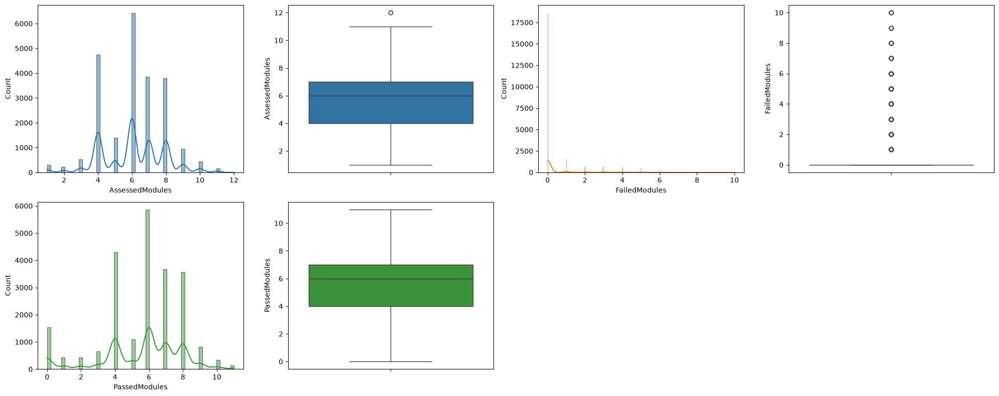

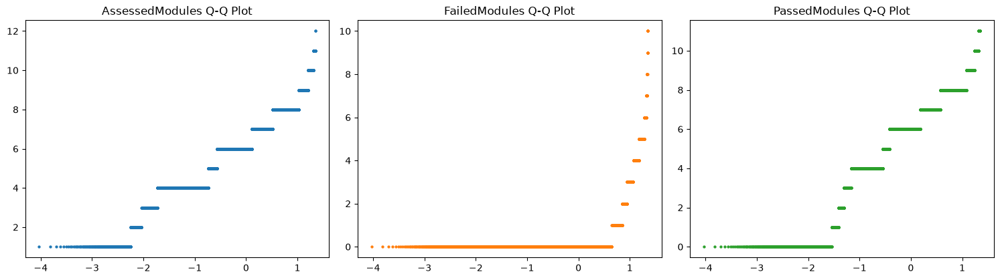

**Interpretation**

---

**AssessedModules**

- The number of assessed modules is tightly distributed, with a median of 6 and an interquartile range of 4 to 7.
- The minimum value is 1 and the maximum is 12, indicating a bounded range.
- The mean (6.09) is close to the median, suggesting a roughly symmetric distribution with limited skew.
- The histogram confirms that most students are assessed on between 4 and 8 modules, with relatively few extreme values.

**PassedModules**

- PassedModules shows a similar distribution to AssessedModules, with a median of 6 and a mean of 5.58.
- The lower quartile is 4 and the upper quartile is 7, indicating that most students pass the majority of assessed modules.
- The minimum of 0 and maximum of 11 suggest that some students fail all modules, while others pass nearly all.

**FailedModules**

- FailedModules is highly right-skewed, with a median of 0 and the 75th percentile also equal to 0.
- This indicates that most students do not fail any modules.
- The mean (0.51) is higher than the median due to a small number of students with multiple failed modules.
- The histogram and boxplot confirm strong zero inflation with a small number of extreme values.

These characteristics suggest that failure-related features are likely to contain strong predictive signal for dropout.

**Missing Data**

Module count values contain a substantial number of missing records, and missingness shows a very strong association with dropout.

Records where module counts are missing exhibit extremely high dropout rates compared to records where module data is present. This indicates that missingness itself carries predictive information and should not be ignored.

Removing these rows would discard a large proportion of the dataset and remove informative signal, therefore the rows will be retained and missingness will be encoded explicitly.

---

## Pre-Processing

### Imputation

To preserve the missing-value signal, a single feature module_values_missing will be created based on the AssessedModules / PassedModules / FailedModules values.

This feature will be defined as follows:

- All values null → 1  
- Values present → 0  

As the module fields are missing simultaneously, a single missingness indicator is sufficient.

Null values in the module count fields will be imputed with zero to allow model training while preserving the missingness signal.

The resulting feature interpretation is shown below:

| module_values_missing | FailedModules | Meaning   |
|----------------------|--------------|-----------|
| 0                    | 2            | real      |
| 0                    | 0            | real zero |
| 1                    | 0            | missing   |


### Encoding

***Not required***  
The new columns are numeric count values or binary indicators, therefore no additional encoding is required.

As these features are being added to the previously processed Stage 2 data, the new columns can be appended to the Stage 2 feature set after encoding but before scaling.


### Scaling

The module count features are bounded integer values with moderate range and do not require transformation.

However, scaling is required for neural network training to ensure comparable feature magnitudes.

StandardScaler will be retained to maintain consistency with previous stages and allow direct comparison between models.  
The combined Stage 1, Stage 2, and module features must therefore be scaled prior to neural network training and evaluation.

Stage 3 dataset shape: (25059, 182)


## Train / validation / test split

We will create a train, test, and validation data set. Training set split 80-20, with 10% of the training set used as validation.

As the target is imbalanced we will use stratified split.

We also create scaled versions of the feature matrices for neural network training, as neural networks rely on gradient-based optimisation and are sensitive to differences in feature scale

,Gender,Age,IsFirstIntake,dropout,progression_degree_missing,academic_stage_Foundation Other,academic_stage_Foundation Year,academic_stage_International Foundation Year,academic_stage_International Year One,academic_stage_International Year Two,...,ProgressionUniversity_UK_SE_03,ProgressionUniversity_UK_WAL_01,ProgressionUniversity_University_Other,UnauthorisedAbsenceCount,AuthorisedAbsenceCount,absence_values_missing,AssessedModules,FailedModules,PassedModules,module_values_missing
0,0,27,1,0,False,0,0,0,0,0,...,0,0,0,0.0,0.0,1,4.0,0.0,4.0,0
1,0,27,0,0,False,0,0,0,0,0,...,0,0,0,5.0,93.0,0,7.0,0.0,7.0,0
2,0,25,0,0,False,0,0,0,0,1,...,0,0,0,6.0,92.0,0,8.0,0.0,8.0,0
3,0,26,1,0,False,0,0,0,0,1,...,0,0,0,15.0,67.0,0,8.0,0.0,8.0,0
4,0,29,1,0,False,0,0,0,0,0,...,0,0,0,0.0,0.0,1,4.0,0.0,4.0,0


## Stage 3 XGBoost Model

### Baseline Model

A new XGBoost model will be trained and evaluated on the updated dataset using the best-performing hyperparameters identified during Stage 2. Model performance will then be compared with the Stage 2 results.

A new model is required because the feature set has changed, resulting in different input dimensionality.

Baseline parameters: {'colsample_bytree': 0.601, 'reg_lambda': 4.74, 'subsample': 0.754, 'max_depth': 8, 'min_child_weight': 1.15, 'gamma': 0.27, 'learning_rate': 0.119, 'reg_alpha': 0.0052}


### Baseline Performance Metrics

We will now evaluate the model against the test set using the following performance indicators:
 - Accuracy
 - Precision
 - Recall
 - AUC

A confusion matrix, ROC and Precision-Recall Curves will also be plotted.

These will be compared against model performance from the model when used with stage 2 data

Stage 2 XG Boost - Tuned Performance Metrics:
Accuracy:    0.9142
Precision:   0.7627
Recall:      0.6205
Specificity: 0.9660
AUC:         0.9326

Stage 2 XGBoost Tuned Confusion Matrix:


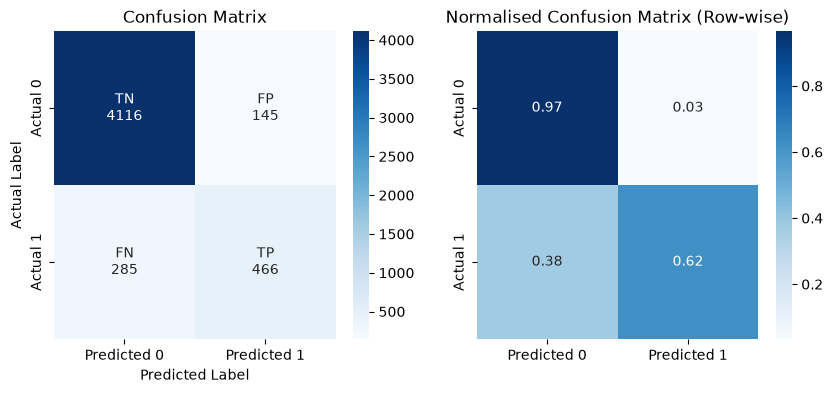

Stage 3 XG Boost - Baseline Performance Metrics:
Accuracy:    0.9884
Precision:   0.9766
Recall:      0.9454
Specificity: 0.9960
AUC:         0.9989

Stage 3 XGBoost Baseline Confusion Matrix:


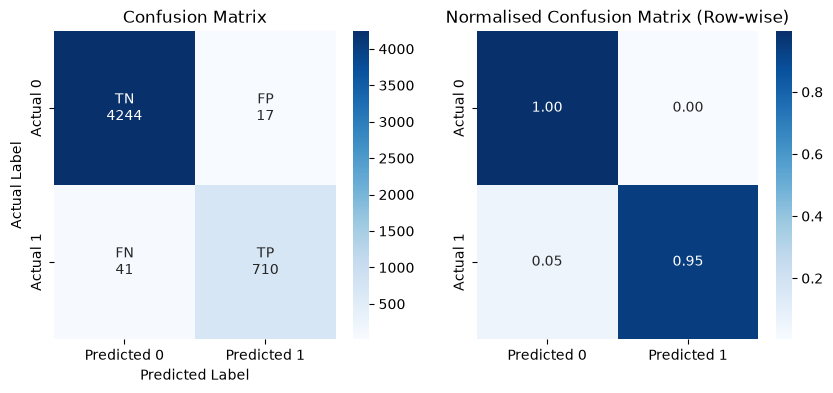

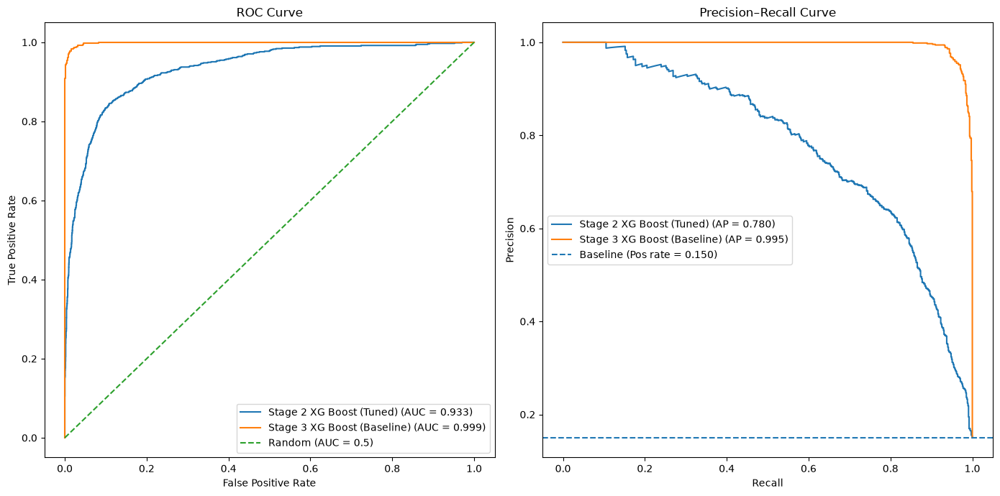

Comparison of XGBoost Stage 2 (Tuned) vs XGBoost Stage 3 (Baseline)

Model performance improves substantially when the Stage 2 tuned model is compared with the model trained on the Stage 3 dataset. AUC increases from 0.9326 to 0.9989, indicating that the model is able to almost perfectly separate students who drop out from those who complete. This is visible in the ROC curve, where the Stage 3 curve lies very close to the top-left corner, showing very high overall discrimination.

| Metric      | Stage 3 | Stage 2 | Change   | Business Interpretation                                                                                  |
| ----------- | ------- | ------- | -------- | -------------------------------------------------------------------------------------------------------- |
| TP          | 710     | 466     | ↑ better | More actual dropout cases in the supplied dataset are correctly identified. |
| FN          | 41      | 285     | ↓ better | Fewer actual dropout cases in the supplied dataset are missed.                     |
| FP          | 17      | 145     | ↓ better | Far fewer students who will complete are incorrectly flagged, reducing unnecessary intervention effort.  |
| TN          | 4244    | 4116    | ↑ better | Almost all students who will complete are correctly recognised.                                          |
| Recall      | 0.9454 | 0.6205 | ↑ better | The model identifies most dropout cases in the supplied dataset.             |
| Specificity | 0.9960 | 0.9660 | ↑ better | Nearly all non-dropout students in the supplied dataset are correctly classified.  |


The Precision–Recall curve also shows a very large improvement, with precision remaining close to 1.0 across most recall values. This indicates that the increase in recall is not achieved by increasing false positives, but by the model having access to much stronger predictive information.

The magnitude of the improvement is far larger than any change observed through hyperparameter tuning, indicating that the performance gain is primarily due to the additional features introduced in the Stage 3 dataset rather than changes to the model configuration.

The large increase in performance suggests that the Stage 3 variables contain information that is highly predictive of the final outcome, allowing the model to distinguish almost perfectly between students who complete and those who drop out.

Overall, the results show that the additional Stage 3 features provide extremely strong predictive signal, leading to near-perfect classification performance.


### Hyperparameter Tuning

Hyperparameters will now be tuned using the same search space previously used for the Stage 1 and 2 model, as summarised below.

Optuna with Bayesian optimisation will be used again to maintain consistency and comparability with the Stage 1 and 2 tuning process.

New fixed-configuration rebuild; not reproduction of historical trial 1798.
Rebuilt model validation AUC: 0.9995014662756598
Historical saved tuning AUC: None
Selected parameters: {'colsample_bytree': 0.612, 'reg_lambda': 0.064, 'subsample': 0.932, 'max_depth': 8, 'min_child_weight': 1.18, 'gamma': 0.67, 'learning_rate': 0.2, 'reg_alpha': 2e-08}
No scored Stage 3 XGBoost trial history is available. Saved parameter summaries and rebuilt evaluation metrics are reported separately.


### Tuned Model

The selected Stage 3 XGBoost parameters are shown below and compared with the Stage 2 parameters used for the baseline.

| Hyperparameter       | Stage 2 Tuned (Stage 3 Baseline) | Stage 3 Tuned  | Interpretation                                                                              |
| -------------------- | -------------------------------- | -------------- | ------------------------------------------------------------------------------------------- |
| **learning_rate**    | 0.119                            | **0.200**      | Higher learning rate in Stage 3 allows faster convergence due to stronger predictive signal |
| **max_depth**        | 8                                | **8**          | Tree depth unchanged, suggesting the previous structure was already sufficient              |
| **min_child_weight** | 1.15                             | **1.18**       | Similar leaf constraints, indicating stable splits already achieved                         |
| **gamma**            | 0.27                             | **0.67**       | Higher split penalty reduces unnecessary splits when features are highly predictive         |
| **subsample**        | 0.754                            | **0.932**      | Less subsampling in Stage 3 allows the model to use more data per tree                      |
| **colsample_bytree** | 0.601                            | **0.612**      | Feature sampling similar, indicating no need for strong feature regularisation              |
| **reg_alpha (L1)**   | 0.0052                           | **0.00000002** | L1 regularisation almost removed, suggesting sparsity control is no longer required         |
| **reg_lambda (L2)**  | 4.74                             | **0.064**      | Much lower L2 regularisation, suggesting the Stage 3 features provide cleaner separation - the model does not need strong regularisation because the features already separate the classes well       |
| **n_estimators**     | 100                   | Maximum 3,000; early stopping | Baseline uses 100 rounds. Final predictions use 38 rounds selected by validation AUC.  |


Only moderate changes to the hyperparameters are observed between the Stage 2 tuned configuration and the Stage 3 tuned model. Tree depth remains unchanged, indicating that the existing model structure was already sufficient to capture the relationships in the data.

The most notable differences are the increase in learning rate and the large reduction in L2 regularisation. The lower regularisation suggests that the Stage 3 features provide a much clearer separation between dropout and non-dropout cases, allowing the model to fit the data without requiring strong constraints to prevent overfitting.

Overall, the relatively small changes in hyperparameters confirm that the performance improvement in Stage 3 is primarily driven by the additional engineered features rather than by extensive hyperparameter optimisation.


### Tuned Model Evaluation

**Performance Metrics**

We will now evaluate the model against the same performance parameters used to evaluate the stage 2 model.

Stage 3 XG Boost - Baseline Performance Metrics:
Accuracy:    0.9884
Precision:   0.9766
Recall:      0.9454
Specificity: 0.9960
AUC:         0.9989

Stage 3 XGBoost Baseline Confusion Matrix:


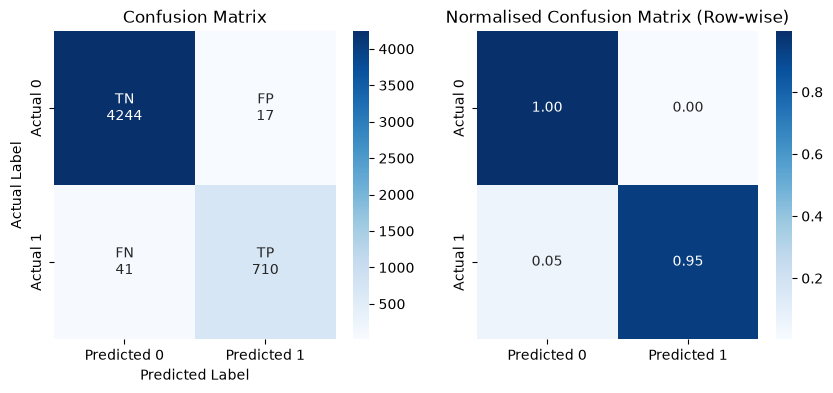

Stage 3 XG Boost - Tuned Performance Metrics:
Accuracy:    0.9886
Precision:   0.9819
Recall:      0.9414
Specificity: 0.9969
AUC:         0.9989

Stage 3 XGBoost Tuned Confusion Matrix:


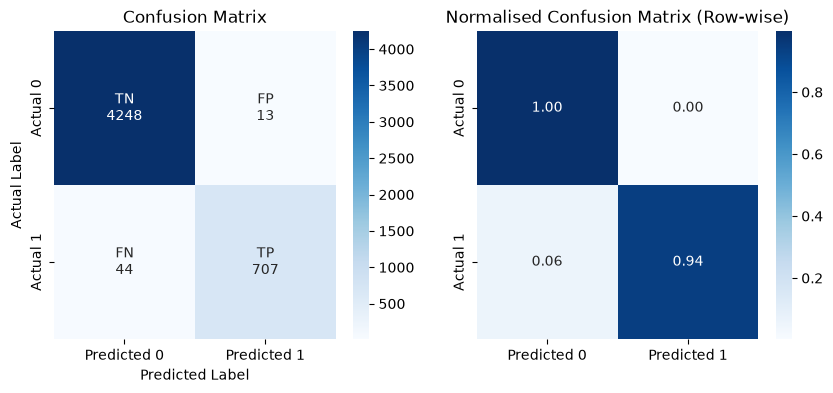

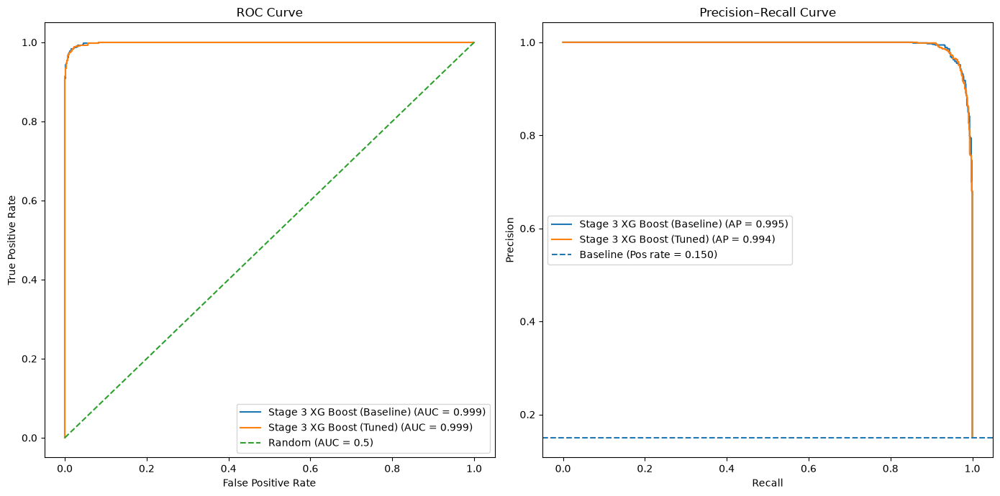

### Stage 3 XGBoost Baseline vs Final Comparison

The baseline and final Stage 3 XGBoost models achieve very similar performance. Both distinguish strongly between dropout and completion cases, with little change after applying the Stage 3 hyperparameters.

| Metric | Baseline | Final |
| ----------- | -------- | -------- |
| Accuracy | 0.9884 | 0.9886 |
| Precision | 0.9766 | 0.9819 |
| Recall | 0.9454 | 0.9414 |
| Specificity | 0.9960 | 0.9969 |
| AUC | 0.998945 | 0.998851 |

The final configuration produces slightly higher precision and specificity, while recall decreases. At the 0.5 classification threshold, fewer students who complete are incorrectly flagged as at risk, but slightly more students who drop out are missed.

AUC remains almost identical and is slightly lower for the final model. The small increase in accuracy therefore reflects a change in the precision–recall trade-off rather than an improvement in overall discrimination. Which configuration is preferable would depend on the relative importance of identifying dropout cases versus avoiding unnecessary interventions.

The difference between configurations is much smaller than the improvement observed when moving from Stage 2 to Stage 3. This supports the conclusion that the additional assessment-related features provide the main performance gain, with the Stage 2 hyperparameters already producing strong results on the richer dataset.


### Feature Importance

We will now review feature importance with the addition of the new features.

Both feature importance and SHAP plots will be created so that we can compare how well they align and use SHAP to better understand magnitude and direction of feature influence.

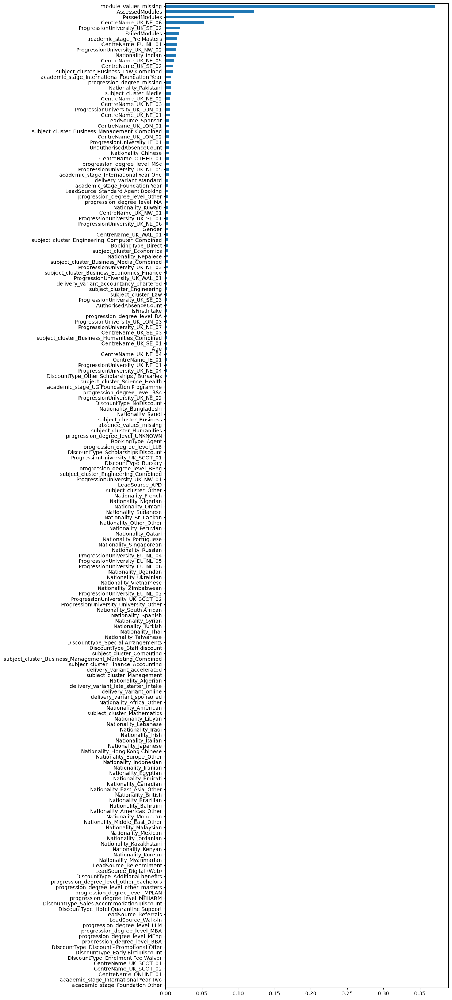

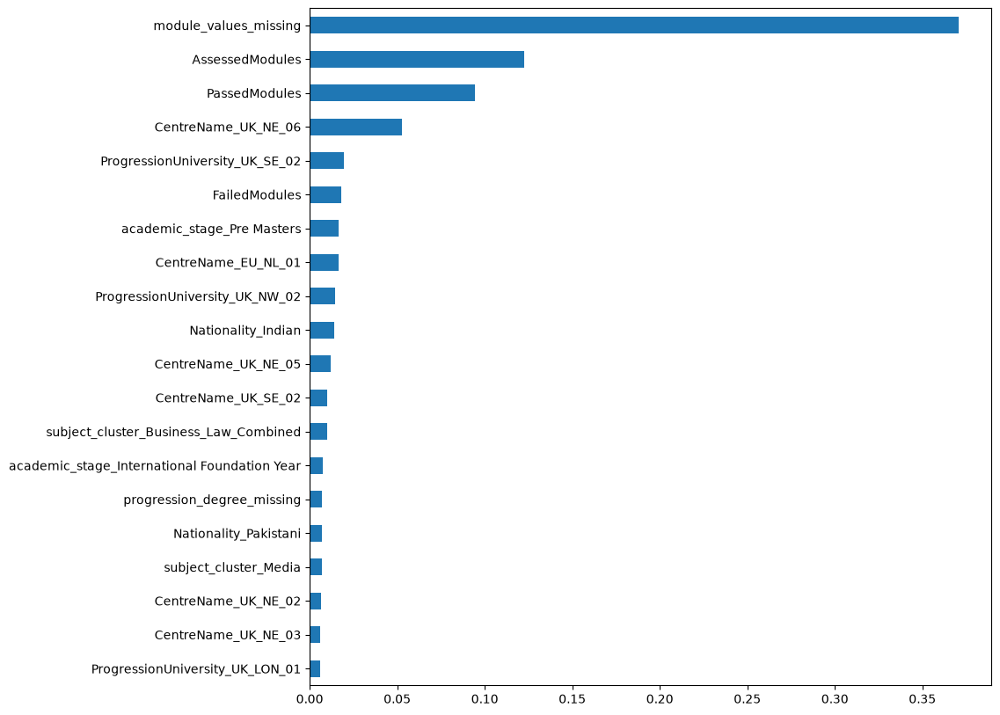

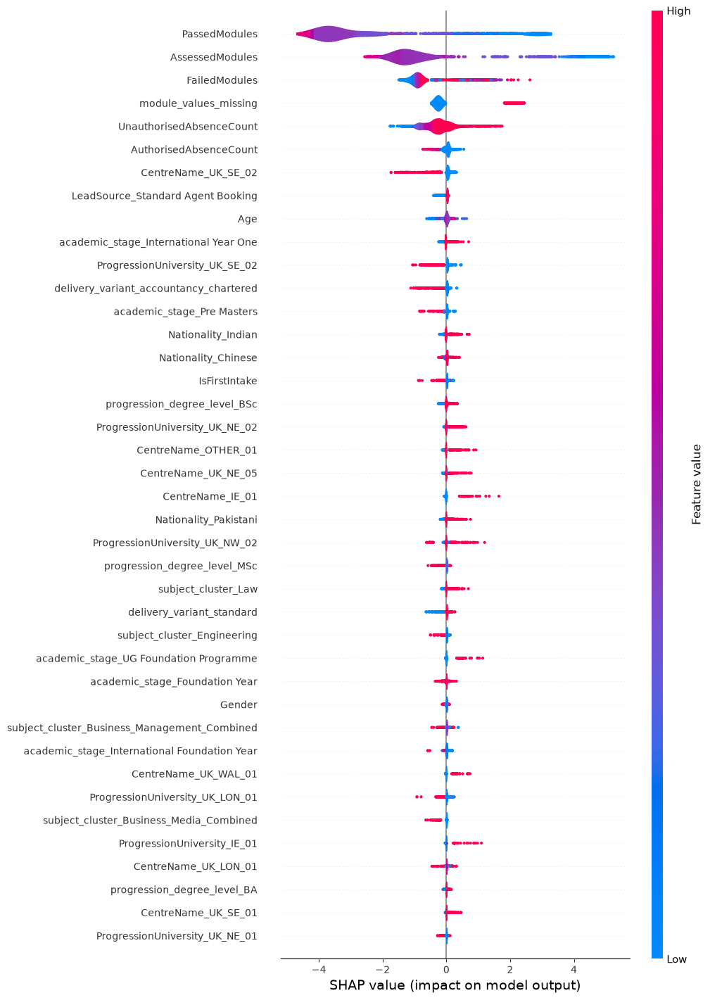

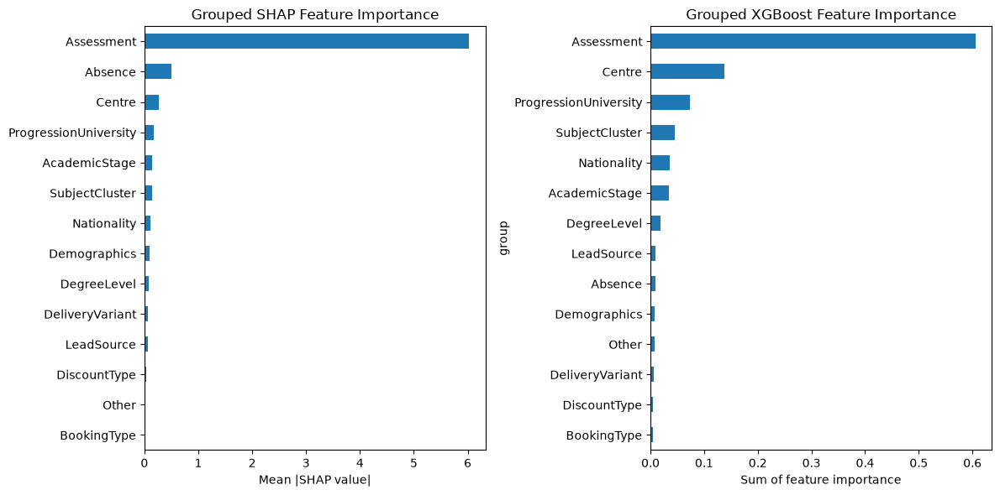

**Interpretation**

SHAP importance indicates that the new assessment-related features provide the strongest contribution to model predictions by a large margin. This suggests that assessment performance is the most informative predictor of dropout in the Stage 3 dataset, and explains the substantial improvement in model performance following the addition of these variables. 

The difference between the two importance measures highlights that assessment features have both strong per-sample influence and strong global predictive power across the dataset. Unlike the absence features in Stage 2, which affected a smaller number of students, the assessment variables provide a clear and consistent signal for most observations.

This explains why the Stage 3 model achieves near-perfect performance, as the additional features allow the model to distinguish between students who drop out and those who complete with very high confidence.

## Stage 3 Neural Network Model

### Baseline Model

A new Neural Network model will be trained and evaluated on the updated dataset using the best-performing hyperparameters identified during Stage 2. Model performance will then be compared with the Stage 2 results.

A new model is required because the feature set has changed, resulting in different input dimensionality.

Stage 3 NN baseline uses Stage 2 selected final parameters: {'units': 160, 'layers': 3, 'activation': 'relu', 'optimizer': 'adam', 'lr': 0.001, 'dropout': 0.3, 'l2_strength': 0.0}


### Baseline Performance Metrics

We will now evaluate the model against the test set using the following performance indicators:
 - Accuracy
 - Precision
 - Recall
 - AUC

A confusion matrix, ROC and Precision-Recall Curves will also be plotted.

These will be compared against the performance of the Stage 2 final neural network on the Stage 2 data.

Stage 2 Neural Network - Tuned Performance Metrics:
Accuracy:    0.9076
Precision:   0.7345
Recall:      0.6005
Specificity: 0.9617
AUC:         0.9183

Stage 2 Neural Network Tuned Confusion Matrix:


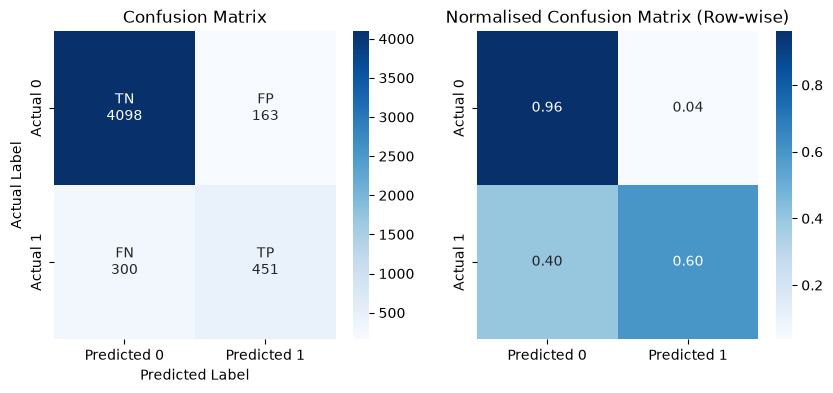

Stage 3 Neural Network - Baseline Performance Metrics:
Accuracy:    0.9850
Precision:   0.9815
Recall:      0.9174
Specificity: 0.9969
AUC:         0.9981

Stage 3 Neural Network Baseline Confusion Matrix:


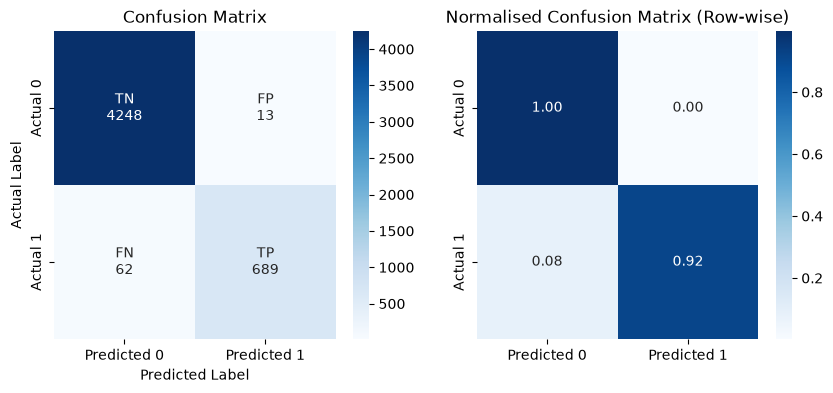

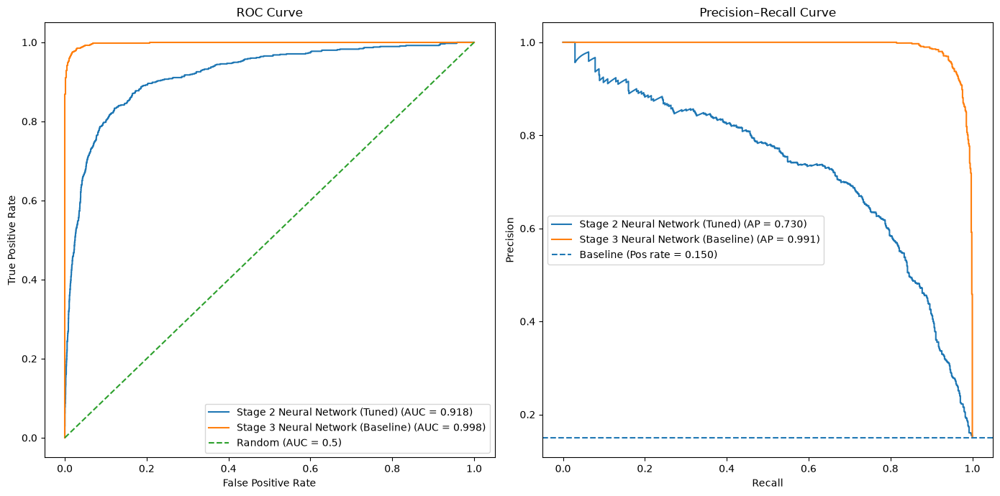


**Comparison of Neural Network Stage 2 (Tuned) vs Neural Network Stage 3 (Baseline)**

---

AUC increases from 0.9182 to 0.9981, indicating a very large improvement in the model’s ability to separate students who drop out from those who complete across all decision thresholds. This is reflected in the ROC curve, where the Stage 3 curve lies much closer to the top-left corner than the Stage 2 curve, resulting in near-perfect discrimination.


| Metric      | Stage 3 | Stage 2 | Change   | Business Interpretation                                                                                                    |
| ----------- | ------- | ------- | -------- | -------------------------------------------------------------------------------------------------------------------------- |
| TP          | 689     | 451     | ↑ better | More actual dropout cases in the supplied dataset are correctly identified. |
| FN          | 62      | 300     | ↓ better | Fewer actual dropout cases in the supplied dataset are missed..                                  |
| FP          | 13      | 163     | ↓ better | Fewer students who will complete are incorrectly flagged as at risk, reducing unnecessary intervention effort.             |
| TN          | 4248    | 4098    | ↑ better | More students who will complete are correctly identified, improving overall classification reliability.                    |
| Recall      | 0.9174 | 0.6005 | ↑ better | A much higher proportion of actual dropout cases in the supplied dataset are identified.  |
| Specificity | 0.9969 | 0.9617 | ↑ better | Almost all non-dropout students in the supplied dataset are correctly classified.              |


As with the XGBoost model, when the Stage 2 tuned architecture is evaluated using the Stage 3 dataset, performance improves dramatically compared with evaluation on the Stage 2 data.

The magnitude of the improvement is far larger than any change observed through hyperparameter tuning, confirming that the performance gain is primarily due to the additional Stage 3 features rather than changes to the neural network architecture.

Overall, the Stage 3 variables provide extremely strong predictive signal, allowing the neural network to achieve near-perfect classification performance, similar to the behaviour observed with the XGBoost model.

---


### Hyperparameter Tuning

Saved tuning artefacts are loaded by default so this notebook can be rerun quickly. Stage 3 neural-network tuning is computationally expensive, so `RUN_NN_TUNING` is set to `False` by default. Set it to `True` only if you want to rerun the RandomSearch workflow and refresh the saved files under `tuning/stage_3/neural_network/`.

The Stage 3 dataset introduces a small number of additional features, but the overall structure of the problem remains similar to Stage 2. For consistency, the neural-network tuning workflow continues to use the refined search space from the earlier stages.


NN tuning is disabled; no tuner is constructed.
No verified completed Stage 3 NN search history is available.
Fixed final configuration evidence: {'parameters': {'units': 160, 'layers': 2, 'activation': 'tanh', 'optimizer': 'adam', 'lr': 0.001, 'dropout': 0.1, 'l2_strength': 1e-05}, 'sources': [{'path': 'tuning/stage_3/neural_network/best_params.json', 'sha256': '45a1cd6ebfa084ab14c4614f4f215b1573ef2d1c2a2f39077c1b8bae15ec8a3a'}, {'path': 'tuning/stage_3/neural_network/trials.csv', 'sha256': 'e8516b7e53d1f562ff2a08632260035f73b760ecfa45022d0f703fde313c6de5'}, {'path': 'notebooks/03_stage_3_data_and_modelling.ipynb', 'cell_id': '24573ac8', 'source_sha256': '36486e61a94487992262d37311aa0c5819313fa835ab8c1b1d72f150a4f09069'}], 'historical_scores': {'summary_val_auc': 0.9993, 'interpretation': 'Summary of another historical run; not a genuine trial record.', 'documented_trial_id': '053', 'trial_identity_verified': False, 'documented_val_auc': 0.9993}, 'configuration_identity': 'documented_

**Refined Hyperparameter Tuning Results**

---

The historical Stage 3 search summary reports validation AUC close to 1.0. The underlying trial-level and seed-level evidence is unavailable, so this summary does not establish verified trial rankings or model stability and is distinct from the current model evaluations.

---

### Tuned Model

The final neural network configuration follows the documented parameters associated with historical trial 053; its original trial identity is unverified. The validation AUC of 0.9993 below is the recorded historical summary value, not the current final model’s evaluation.

| Model        | Units | Layers | Activation | Optimizer | LR     | Dropout | L2      | Val AUC |
|------------|-------|--------|-----------|----------|--------|---------|---------|---------|
| Trial 053  | 160   | 2      | tanh      | adam     | 0.0010 | 0.1     | 0.00001 | 0.9993  |


### Tuned Model Evaluation

**Performance Metrics**

We will now evaluate the model against the same performance parameters used to evaluate the stage 2 model.

Selected final NN parameters: {'units': 160, 'layers': 2, 'activation': 'tanh', 'optimizer': 'adam', 'lr': 0.001, 'dropout': 0.1, 'l2_strength': 1e-05}
New validation metrics: {'accuracy': 0.9920199501246882, 'precision': 0.9896551724137931, 'recall': 0.9566666666666667, 'specificity': 0.9982404692082112, 'auc': 0.9991417399804498}
Selected Stage 3 final neural-network parameters:


,units,layers,activation,optimizer,lr,dropout,l2_strength
0,160,2,tanh,adam,0.001,0.1,0.00001


Stage 3 Neural Network - Baseline Performance Metrics:
Accuracy:    0.9850
Precision:   0.9815
Recall:      0.9174
Specificity: 0.9969
AUC:         0.9981

Stage 3 Neural Network Baseline Confusion Matrix:


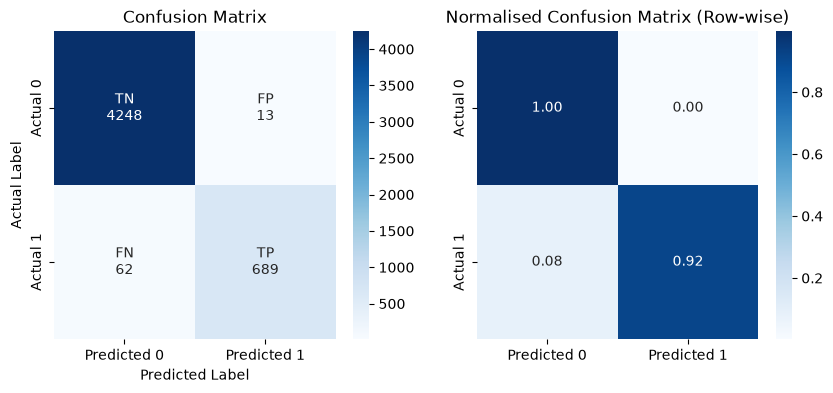

Stage 3 Neural Network - Tuned Performance Metrics:
Accuracy:    0.9870
Precision:   0.9738
Recall:      0.9387
Specificity: 0.9955
AUC:         0.9986

Stage 3 Neural Network Tuned Confusion Matrix:


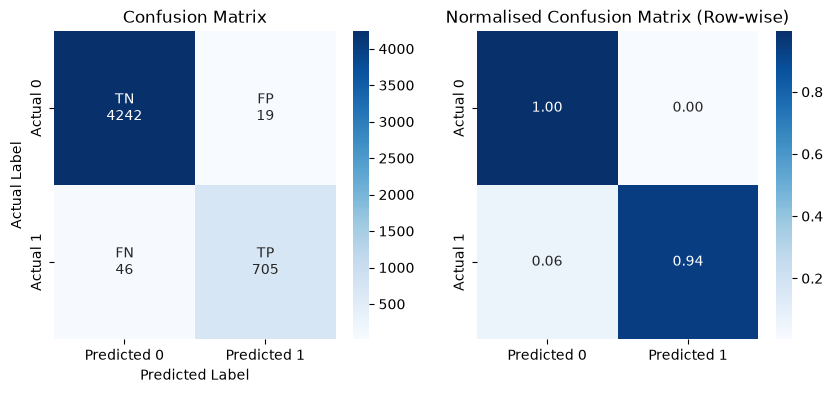

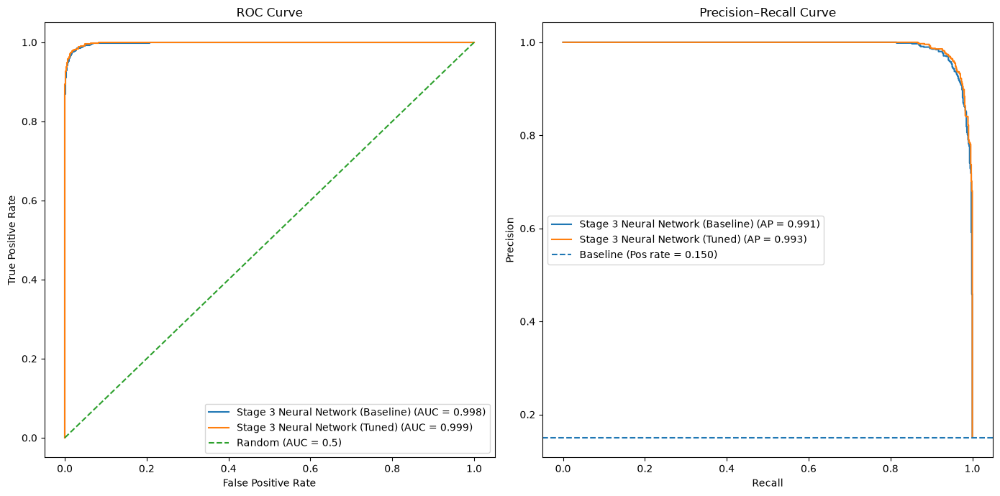

### Stage 3 Neural Network Baseline vs Final Comparison

Both Stage 3 neural networks achieve very high test performance. The final configuration increases test AUC from approximately 0.9981 to 0.9986, while accuracy increases from approximately 98.5% to 98.7%.

| Metric | Baseline | Final |
| ----------- | -------- | -------- |
| Accuracy | 0.9850 | 0.9870 |
| Precision | 0.9815 | 0.9738 |
| Recall | 0.9174 | 0.9387 |
| Specificity | 0.9969 | 0.9955 |
| AUC | 0.9981 | 0.9986 |

These results indicate a small improvement in discrimination and accuracy. The difference is much smaller than the improvement observed when moving from Stage 2 to Stage 3, supporting the conclusion that the additional assessment-related features provide the main performance gain.


## Stage 3 Model Comparison

### Performance Metrics Comparison (Stage 2 vs Stage 3)

Comparison of the results of the XGBoost and Neural network models on the Stage 3 dataset Vs the Stage 2 dataset

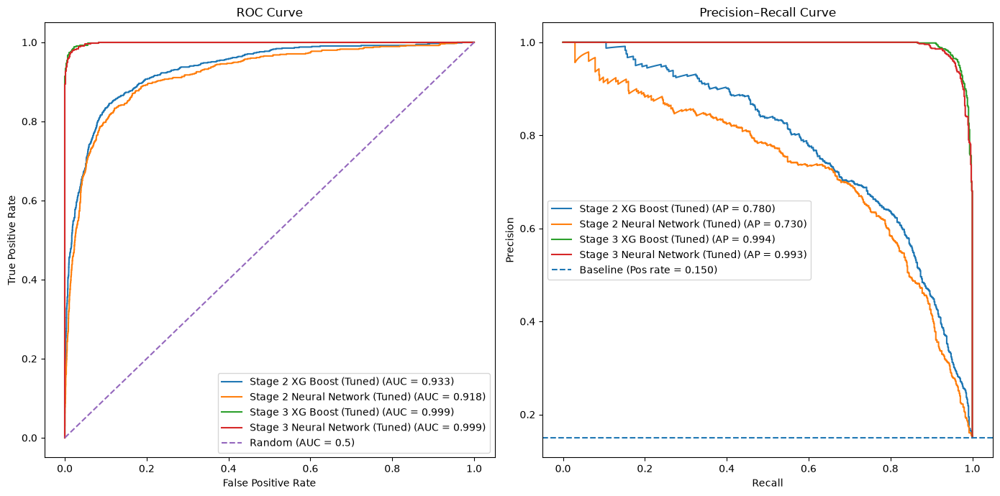




| Model | Dataset | Accuracy | Precision | Recall | Specificity | AUC |
| -------------- | ------- | -------- | --------- | ------ | ----------- | ------ |
| XGBoost | Stage 2 | 0.9142 | 0.7627 | 0.6205 | 0.9660 | 0.9326 |
| XGBoost | Stage 3 | **0.9886** | **0.9819** | **0.9414** | **0.9969** | **0.9989** |
| Neural Network | Stage 2 | 0.9076 | 0.7345 | 0.6005 | 0.9617 | 0.9182 |
| Neural Network | Stage 3 | **0.9870** | **0.9738** | **0.9387** | **0.9955** | **0.9986** |


**Interpretation**

---

The table compares the selected final models from Stages 2 and 3. Both the feature sets and model configurations differ. The earlier baseline comparisons carry forward the Stage 2 hyperparameters to examine the effect of adding the Stage 3 features.

Both XGBoost and the neural network show a very large improvement when trained on the Stage 3 dataset. Accuracy, precision, recall, specificity, and AUC all increase substantially for both models, indicating that the additional features introduced in Stage 3 provide very strong predictive information.

In particular, both models become much better at identifying dropout cases in the supplied dataset while still maintaining extremely high specificity, with few students who complete incorrectly classified as dropout cases.

XGBoost achieves the highest overall performance on the Stage 3 dataset, with slightly higher test AUC and accuracy than the neural network. The ROC and Precision–Recall curves also show that the XGBoost model lies marginally outside the neural network across most thresholds. This suggests that the tree-based model is able to exploit the additional Stage 3 features slightly more effectively.

Overall, the results show that the major improvement in performance comes from the additional engineered features introduced in Stage 3 rather than from changes to the model architecture. Once these highly informative variables are included, both models perform extremely well, with XGBoost showing a small but consistent advantage in predictive accuracy.

---

### Effect of Stage 3 Hyperparameter Tuning

The Stage 3 baseline models carry forward the selected Stage 2 hyperparameters. Comparing these with the final Stage 3 configurations shows whether further optimisation provides additional benefit.

For XGBoost, test AUC remains effectively unchanged, moving from 0.998945 to 0.998851. At the 0.5 classification threshold, the final configuration slightly increases precision and specificity while reducing recall. This represents a small classification trade-off rather than an improvement in overall discrimination.

For the neural network, the final configuration slightly improves test AUC, from approximately 0.9981 to 0.9986, and accuracy, from approximately 98.5% to 98.7%.

Overall, the differences between configurations are small compared with the improvement observed when moving from Stage 2 to Stage 3. The additional assessment-related features provide the main performance gain, with further optimisation offering limited benefit in these evaluations.

# Stage 1, 2, 3 Tuned Model Comparison

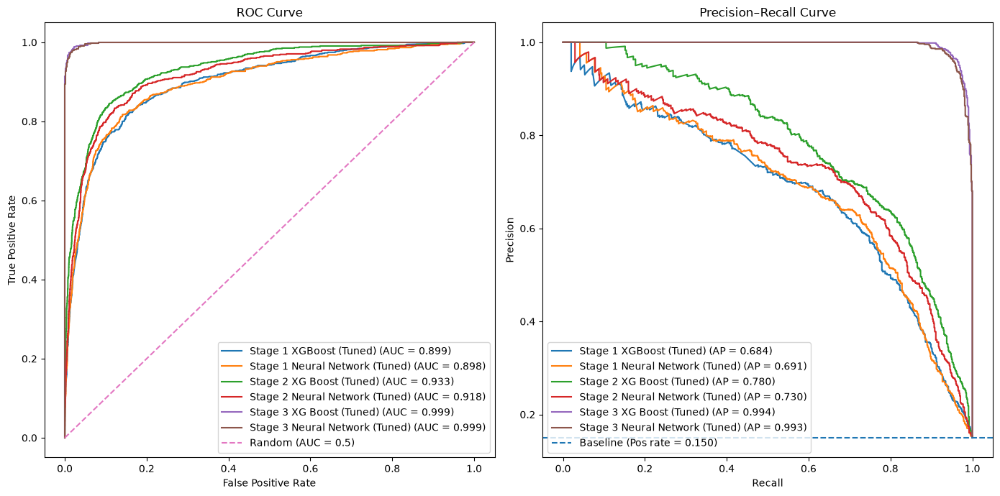

model_id,stage,model_type,model_name,accuracy,precision,recall,specificity,auc
1,Stage 1,XGBoost,Baseline,0.895850,0.695060,0.543276,0.957991,0.895078
2,Stage 1,XGBoost,Tuned,0.899042,0.697900,0.575233,0.956114,0.898815
3,Stage 1,Neural Network,Baseline,0.895052,0.669173,0.592543,0.948369,0.889853
4,Stage 1,Neural Network,Tuned,0.898643,0.706282,0.553928,0.959399,0.897849
5,Stage 2,XGBoost,Baseline,0.916201,0.767367,0.632490,0.966205,0.930712
6,Stage 2,XG Boost,Tuned,0.914206,0.762684,0.620506,0.965970,0.932614
7,Stage 2,Neural Network,Baseline,0.908420,0.737785,0.603196,0.962215,0.918734
8,Stage 2,Neural Network,Tuned,0.907622,0.734528,0.600533,0.961746,0.918251
9,Stage 3,XG Boost,Baseline,0.988428,0.976616,0.945406,0.996010,0.998945
10,Stage 3,XG Boost,Tuned,0.988627,0.981944,0.941411,0.996949,0.998851


stage,model_type,model_name,n_estimators,max_depth,learning_rate,subsample,colsample_bytree,gamma,min_child_weight,reg_alpha,reg_lambda,epochs,batch_size,units,layers,dropout,l2_strength,lr,optimiser,activation,earlystopping,config_idx,optimizer,seed_scores,mean_val_auc,std_val_auc
Stage 1,Neural Network,Baseline,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,50.0,64.0,32.0,1.0,0.0,0.00000,0.0010,adam,relu,"{'monitor': 'val_auc', 'mode': 'max', 'patience': 5, 'restore_best_weights': True, 'min_delta': 0.0001}",NaN,NaN,NaN,NaN,NaN
Stage 1,Neural Network,Tuned,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,240.0,3.0,0.3,0.00010,0.0003,NaN,relu,NaN,1.0,adam,"[0.8823665976524353, 0.8796314001083374, 0.8769629001617432]",0.879654,0.002206
Stage 1,XGBoost,Baseline,100.0,3.0,0.100000,0.800000,0.80000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Stage 1,XGBoost,Tuned,NaN,8.0,0.146668,0.856013,0.98828,1.868997,1.10794,1.946531e-02,0.030819,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Stage 2,Neural Network,Baseline,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,240.0,3.0,0.3,0.00010,0.0003,NaN,relu,NaN,NaN,adam,NaN,NaN,NaN
Stage 2,Neural Network,Tuned,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,160.0,3.0,0.3,0.00000,0.0010,NaN,relu,NaN,NaN,adam,NaN,NaN,NaN
Stage 2,XG Boost,Tuned,NaN,8.0,0.119000,0.754000,0.60100,0.270000,1.15000,5.200000e-03,4.740000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Stage 2,XGBoost,Baseline,NaN,8.0,0.146668,0.856013,0.98828,1.868997,1.10794,1.946531e-02,0.030819,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Stage 3,Neural Network,Baseline,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,160.0,3.0,0.3,0.00000,0.0010,NaN,relu,NaN,NaN,adam,NaN,NaN,NaN
Stage 3,Neural Network,Tuned,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,160.0,2.0,0.1,0.00001,0.0010,NaN,tanh,NaN,NaN,adam,NaN,NaN,NaN


### Prediction Timing and Practical Use

The Stage 3 results demonstrate strong discrimination using assessment-related information. Their suitability for early intervention depends on when that information becomes available.

Before operational use, the features would need to be restricted to values recorded before a defined prediction date. Otherwise, the evaluation may include information collected too late to support the intended intervention.

The current results therefore demonstrate predictive performance on the supplied dataset. They do not establish how accurately the models would identify at-risk students at an earlier point in their course.

In [4]:
_run_stage('03_stage_3_data_and_modelling.ipynb')
